# BJT and MOSFET Problem Bank: Cascodes and Current Mirrors

148 problems, each solved step by step. A problem is one table: the BJT problem on the left, a MOSFET problem of the same nature on the right, and under them the two answers side by side, line by line. Where one transistor has no partner problem, its column is empty. The natures and their solution patterns are introduced on [BJT and MOSFET Problem Sets](problems.ipynb).

Inside a nature, the problems whose circuit we have drawn come under that drawing; the others describe their circuit in words. Every solution was solved a second time independently and compared, and every numeric result was recomputed by a program. The last row says how the result was checked.

| Nature | BJT | MOSFET |
|---|---|---|
| Cascode Current Sources | 18 | 14 |
| Cascode Amplifiers | 17 | 19 |
| Current Mirrors | 29 | 20 |
| Improved Current Mirrors | 12 | 7 |
| Current Steering and Biasing | 8 | 4 |

In [1]:
# HIDE/SHOW
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}   # keep every figure at its full width
plt.rcParams['svg.hashsalt'] = 'fme'            # reproducible SVG output

from schematic import show
from schematic import circuits as C

## Cascode Current Sources

### Cascode

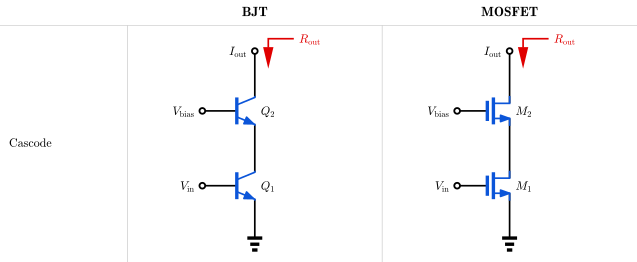

In [2]:
# HIDE/SHOW
show(C.cascode)

**Problem 1**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Two npn transistors are stacked. $Q_2$ has its emitter at ground and its base at a fixed dc voltage $V_{b1}$; its collector feeds the emitter of $Q_1$. $Q_1$ has its base at a fixed voltage $V_{b2}$. Find the small-signal output resistance at the collector of $Q_1$ (a cascode). | Design an NMOS cascode current source (M2 with grounded source and fixed gate bias, M1 stacked on its drain, output at the drain of M1) for an output resistance of $500\,\mathrm{k}\Omega$ at $0.5\,\mathrm{mA}$. For simplicity take M1 and M2 identical. |
| **Given** | symbolic: $g_{m1}$, $r_{\pi1}$, $r_{O1}$, $r_{O2}$ (both bases at ac ground) | $I_D=0.5\,\mathrm{mA}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0.1\,\mathrm{V^{-1}}$, $R_{out}=500\,\mathrm{k}\Omega$ |
| **Answer 1** | **What $Q_2$ looks like.** Its base-emitter voltage is fixed by $V_{b1}$, so $v_{\pi2}=0$ and its current source $g_{m2}v_{\pi2}$ is zero. Only its output resistance remains: $Q_2$ is replaced by $r_{O2}$ from the emitter of $Q_1$ to ground. | **Output resistance formula.** $R_{out}=(1+g_{m1}r_{O2})r_{O1}+r_{O2}\approx g_{m1}r_{O1}r_{O2}$. |
| **Answer 2** | **Recognize the topology.** $Q_1$ now has its base grounded and an emitter resistance $r_{O2}$: an emitter-degenerated stage with $R_E=r_{O2}$. | **Output resistance of each device.** $r_{O1}=r_{O2}=\dfrac1{\lambda I_D}=\dfrac1{0.1\cdot0.5\,\mathrm{mA}}=20\,\mathrm{k}\Omega$. |
| **Answer 3** | – | **Required transconductance.** $g_m\cdot(20\,\mathrm{k}\Omega)^2=500\,\mathrm{k}\Omega\Rightarrow g_m=\dfrac{500\,\mathrm{k}\Omega}{4\times10^8\,\Omega^2}=1.25\,\mathrm{mS}=\dfrac1{800\,\Omega}$. |
| **Answer 4** | **Special case.** If $r_{O2}\gg r_{\pi1}$ then $r_{O2}\parallel r_{\pi1}\approx r_{\pi1}$ and $R_{out}\approx(1+g_{m1}r_{\pi1})r_{O1}=(\beta+1)\,r_{O1}$. If instead $r_{O2}\ll r_{\pi1}$, then $R_{out}\approx(1+g_{m1}r_{O2})r_{O1}+r_{O2}$. | **Aspect ratio.** $g_m=\sqrt{2\mu_nC_{ox}(W/L)I_D}$, so $\dfrac WL=\dfrac{g_m^2}{2\mu_nC_{ox}I_D}=\dfrac{(1.25\,\mathrm{mS})^2}{2\cdot100\,\mu\mathrm{A/V^2}\cdot0.5\,\mathrm{mA}}=15.6$. |
| **Answer 5** | – | **Check of the assumption.** $g_mr_O=1.25\,\mathrm{mS}\cdot20\,\mathrm{k}\Omega=25\gg1$, so the approximation is acceptable. (The exact formula with this $W/L$ gives $26\cdot20+20=540\,\mathrm{k}\Omega$, about 8 % above target.) |
| **Result** | $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{\pi1})]\,r_{O1}+(r_{O2}\parallel r_{\pi1})$ | $W/L\approx15.6$ for both transistors ($g_m=1/800\,\Omega$, $r_O=20\,\mathrm{k}\Omega$, $g_mr_O=25$) |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 2**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn cascode current source has a lower transistor Q2 (emitter grounded, base at a fixed bias) and an upper transistor Q1 (base at a fixed bias) whose emitter sits on the collector of Q2. The output is taken at the collector of Q1. Both transistors are identical, carry $1\,\mathrm{mA}$ and have $\beta=100$, $V_A=5\,\mathrm{V}$. Find the small-signal output resistance and compare it with that of a single transistor. | NMOS cascode current source for $0.5\,\mathrm{mA}$: bottom device $M_2$ ($W/L=20/0.18$, source grounded, gate $V_{b2}$), top device $M_1$ ($W/L=30/0.18$, gate $V_{b1}$), output at the drain of $M_1$. $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{TH}=0.4\,\mathrm{V}$. (a) Ignoring channel-length modulation, find $V_{b2}$ and the minimum $V_{b1}$ that keeps $M_2$ saturated. (b) With $\lambda=0.1\,\mathrm{V^{-1}}$, find $R_{out}$. |
| **Given** | $I_{C1}=I_{C2}=1\,\mathrm{mA}$, $\beta=100$, $V_{A1}=V_{A2}=5\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$ | $I_D=0.5\,\mathrm{mA}$, $(W/L)_1=30/0.18$, $(W/L)_2=20/0.18$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{TH}=0.4\,\mathrm{V}$, $\lambda=0.1\,\mathrm{V^{-1}}$ |
| **Answer 1** | **Model of the lower transistor.** Its base-emitter voltage is fixed, so for small signals Q2 is just its output resistance $r_{O2}$ from the emitter node of Q1 to ground. | **(a) Overdrive of M2.** $V_{GS2}-V_{TH}=\sqrt{\dfrac{2I_D}{\mu_nC_{ox}(W/L)_2}}=\sqrt{\dfrac{10^{-3}}{10^{-4}\cdot111}}=0.300\,\mathrm{V}$ |
| **Answer 2** | **Output resistance of Q1 with emitter load.** Q1 sees $r_{O2}$ from its emitter to ground, in parallel with its own $r_{\pi1}$ (the emitter also looks into the base-emitter path): $R_{out}=\left[1+g_{m1}(r_{O2}\parallel r_{\pi1})\right]r_{O1}+r_{O2}\parallel r_{\pi1}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})$. | **(a) Vb2.** $V_{b2}=V_{TH}+0.3=0.700\,\mathrm{V}$ |
| **Answer 3** | **Small-signal parameters.** $g_m=I_C/V_T=1\,\mathrm{mA}/26\,\mathrm{mV}=38.5\,\mathrm{mS}$ (i.e. $1/26\,\Omega$), $r_O=V_A/I_C=5\,\mathrm{k}\Omega$, $r_\pi=\beta/g_m=2.6\,\mathrm{k}\Omega$. | **(a) Overdrive of M1.** $V_{GS1}-V_{TH}=\sqrt{\dfrac{10^{-3}}{10^{-4}\cdot167}}=0.245\,\mathrm{V}$, so $V_{GS1}=0.645\,\mathrm{V}$ |
| **Answer 4** | **Parallel combination.** $r_{O2}\parallel r_{\pi1}=\dfrac{5\cdot2.6}{5+2.6}\,\mathrm{k}\Omega=1.71\,\mathrm{k}\Omega$. | **(a) Minimum Vb1.** $M_2$ saturated needs $V_X\ge V_{GS2}-V_{TH}=0.3\,\mathrm{V}$; $V_{b1}=V_X+V_{GS1}\ge0.3+0.645=0.945\,\mathrm{V}$ |
| **Answer 5** | **Approximate output resistance.** $R_{out}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})=\dfrac{5000}{26}\cdot1710\,\Omega=329\,\mathrm{k}\Omega$. | **(b) Small-signal parameters.** $r_{O1}=r_{O2}=\dfrac{1}{\lambda I_D}=20\,\mathrm{k}\Omega$, $g_{m1}=\dfrac{2I_D}{V_{GS1}-V_{TH}}=4.08\,\mathrm{mS}$ |
| **Answer 6** | **Exact expression.** $R_{out}=(1+65.8)\cdot5\,\mathrm{k}\Omega+1.71\,\mathrm{k}\Omega=336\,\mathrm{k}\Omega$; the approximation is 2 % low. | **(b) Output resistance.** $R_{out}=(1+g_{m1}r_{O2})r_{O1}+r_{O2}=(1+81.6)\cdot20\,\mathrm{k}\Omega+20\,\mathrm{k}\Omega=1.67\,\mathrm{M}\Omega$ |
| **Answer 7** | **Compare with one transistor.** A single transistor gives $r_{O1}=5\,\mathrm{k}\Omega$, so cascoding raises the output resistance by $329/5\approx66$. | – |
| **Result** | $R_{out}\approx329\,\mathrm{k}\Omega$ (exact formula $336\,\mathrm{k}\Omega$), about 66 times $r_O=5\,\mathrm{k}\Omega$ | (a) $V_{b2}=0.700\,\mathrm{V}$, $V_{b1,min}=0.945\,\mathrm{V}$; (b) $R_{out}=1.67\,\mathrm{M}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Solved twice, with the same result; no answer is published. |

**Problem 3**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the output resistance and compare it with the upper bound of the bipolar cascode, $\beta r_{O1}$. | – |
| **Given** | $I_C=1\,\mathrm{mA}$, $\beta=100$, $V_{A1}=5\,\mathrm{V}$, $V_{A2}=50\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$ | – |
| **Answer 1** | **Parameters.** $g_{m1}=1/26\,\Omega$, $r_{\pi1}=\beta/g_{m1}=2.6\,\mathrm{k}\Omega$, $r_{O1}=5\,\mathrm{k}\Omega$, $r_{O2}=50\,\mathrm{k}\Omega$. | – |
| **Answer 2** | **Parallel resistance at the emitter of Q1.** $r_{O2}\parallel r_{\pi1}=\dfrac{50\cdot2.6}{52.6}\,\mathrm{k}\Omega=2.47\,\mathrm{k}\Omega$. | – |
| **Answer 3** | **Output resistance.** $R_{out}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})=192.3\times2.47\,\mathrm{k}\Omega=475\,\mathrm{k}\Omega$ (exact formula: $483\,\mathrm{k}\Omega$). | – |
| **Answer 4** | **Upper bound.** Letting $r_{O2}\to\infty$ leaves only $r_{\pi1}$ at the emitter, so $R_{out,max}\approx g_{m1}r_{O1}r_{\pi1}=\beta r_{O1}=500\,\mathrm{k}\Omega$. | – |
| **Answer 5** | – | – |
| **Result** | $R_{out}\approx475\,\mathrm{k}\Omega$; bound $\beta r_{O1}=500\,\mathrm{k}\Omega$, about 5 % higher | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 4**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Bipolar cascode current source: npn $Q_2$ has its emitter grounded and its base at $V_{b2}$; npn $Q_1$ sits on top, emitter at the collector of $Q_2$, base at $V_{b1}$; the output is the collector of $Q_1$. Both devices have $I_S=6\times10^{-17}\,\mathrm{A}$ and $\beta=100$; ignore the Early effect. (a) Find $V_{b2}$ for a bias (output) current of $1\,\mathrm{mA}$. (b) Using $V_{CE2}=V_{b1}-V_{BE1}$, find $V_{b1}$ such that the base-collector junction of $Q_2$ is forward biased by only $300\,\mathrm{mV}$. | NMOS cascode current source: $M_2$ at the bottom (source grounded, gate $V_{b2}$), $M_1$ on top (gate $V_{b1}$, source on the drain of $M_2$), output at the drain of $M_1$. It must carry $0.5\,\mathrm{mA}$ with $R_{out}\ge50\,\mathrm{k}\Omega$. Both devices have $W/L=20/0.18$ and $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$. Find the largest allowed $\lambda$. |
| **Given** | $I_S=6\times10^{-17}\,\mathrm{A}$, $\beta=100$, $V_A=\infty$, $I_{C1}=1\,\mathrm{mA}$, $V_T=26\,\mathrm{mV}$ | $I_D=0.5\,\mathrm{mA}$, $W/L=20/0.18$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $R_{out}\ge50\,\mathrm{k}\Omega$ |
| **Answer 1** | **(a) Current of the lower device.** $Q_2$ carries the emitter current of $Q_1$: $I_{C2}=I_{E1}=\dfrac{\beta+1}{\beta}I_{C1}=1.01\,\mathrm{mA}$ | **Transconductance.** $g_{m1}=\sqrt{2\mu_nC_{ox}(W/L)I_D}=\sqrt{2\cdot10^{-4}\cdot111\cdot0.5\times10^{-3}}=3.33\,\mathrm{mS}=(300\,\Omega)^{-1}$ |
| **Answer 2** | **(a) Base voltage of Q2.** $V_{b2}=V_{BE2}=V_T\ln\dfrac{I_{C2}}{I_S}=0.026\ln\dfrac{1.01\times10^{-3}}{6\times10^{-17}}=0.792\,\mathrm{V}$ | **Output resistance.** Eq. (9.22) with $r_{O1}=r_{O2}=r_O$: $R_{out}=(1+g_{m1}r_O)r_O+r_O=g_{m1}r_O^2+2r_O$ |
| **Answer 3** | **(b) Base-emitter voltage of Q1.** $V_{BE1}=V_T\ln\dfrac{I_{C1}}{I_S}=0.026\ln\dfrac{10^{-3}}{6\times10^{-17}}=0.792\,\mathrm{V}$ ($0.7916$ V) | **Solve for rO.** $g_{m1}r_O^2+2r_O-50\,\mathrm{k}\Omega=0\Rightarrow r_O=\dfrac{-2+\sqrt{4+4g_{m1}\cdot50\,\mathrm{k}\Omega}}{2g_{m1}}=3.58\,\mathrm{k}\Omega$ |
| **Answer 4** | **(b) Condition on Q2.** Forward bias of $300\,\mathrm{mV}$: $V_{B2}-V_{C2}=0.3\,\mathrm{V}$, so $V_{C2}=V_{b2}-0.3=0.492\,\mathrm{V}$ | **Largest lambda.** $\lambda=\dfrac{1}{r_OI_D}=\dfrac{1}{3585\cdot0.5\times10^{-3}}=0.558\,\mathrm{V^{-1}}$ |
| **Answer 5** | **(b) Base voltage of Q1.** $V_{b1}=V_{C2}+V_{BE1}=V_{b2}-0.3+V_{BE1}=0.7918-0.3+0.7916=1.28\,\mathrm{V}$ | – |
| **Answer 6** | **(b) Meaning.** This is the lowest $V_{b1}$ allowed; any higher $V_{b1}$ lifts $V_{C2}$ and reduces the forward bias of $Q_2$ | – |
| **Result** | (a) $V_{b2}=0.792\,\mathrm{V}$; (b) $V_{b1}=1.28\,\mathrm{V}$ (minimum) | $\lambda_{max}\approx0.558\,\mathrm{V^{-1}}$ ($0.516\,\mathrm{V^{-1}}$ with $R_{out}\approx g_mr_O^2$) |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 5**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | For a bipolar cascode current source with identical devices at collector current $I_C$, Eq. (9.9) gives $R_{out}\approx\dfrac{1}{I_C}\cdot\dfrac{V_A}{V_T}\cdot\dfrac{\beta V_AV_T}{V_A+\beta V_T}$. Discrete transistors have Early voltages of tens of volts, so $V_A\gg\beta V_T$ for $\beta<100$. Simplify the expression under this approximation and explain why it matches the upper bound $R_{out}\approx\beta r_O$ of Eq. (9.12). | – |
| **Given** | $V_A\gg\beta V_T$, $r_O=V_A/I_C$, $r_\pi=\beta V_T/I_C$ | – |
| **Answer 1** | **Start.** $R_{out}\approx\dfrac{1}{I_C}\cdot\dfrac{V_A}{V_T}\cdot\dfrac{\beta V_AV_T}{V_A+\beta V_T}$ | – |
| **Answer 2** | **Approximate.** $V_A+\beta V_T\approx V_A$, so $R_{out}\approx\dfrac{1}{I_C}\cdot\dfrac{V_A}{V_T}\cdot\beta V_T=\dfrac{\beta V_A}{I_C}=\beta r_O$ | – |
| **Answer 3** | **Why.** $V_A\gg\beta V_T$ means $r_{O2}=V_A/I_C\gg r_{\pi1}=\beta V_T/I_C$, so $r_{O2}\parallel r_{\pi1}\approx r_{\pi1}$ and $g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})\to g_{m1}r_{O1}r_{\pi1}=\beta r_{O1}$, which is Eq. (9.12) | – |
| **Answer 4** | **Example.** $V_A=50\,\mathrm{V}$, $\beta=100$, $I_C=1\,\mathrm{mA}$: Eq. (9.9) gives $4.75\,\mathrm{M}\Omega$, $\beta r_O=5.00\,\mathrm{M}\Omega$ (5 % apart) | – |
| **Result** | $R_{out}\approx\beta V_A/I_C=\beta r_O$, the maximum of Eq. (9.12), because $r_{O2}\gg r_{\pi1}$ | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 6**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Design the npn cascode current source ($Q_2$ with base at $V_{b2}$ and grounded emitter, $Q_1$ stacked on it with base at $V_{b1}$, output at the collector of $Q_1$) for a bias current of $1\,\mathrm{mA}$ and an output impedance of $50\,\mathrm{k}\Omega$. Choose $V_{b1}$ so that $Q_2$ has a base-collector forward bias of only $100\,\mathrm{mV}$. Use the design-problem default device data. | An NMOS cascode current source: $M_2$ (gate $V_{b2}$, source grounded) under $M_1$ (gate $V_{b1}$), output at the drain of $M_1$. It must carry $0.5\,\mathrm{mA}$ with an output impedance of $200\,\mathrm{k}\Omega$. (a) Find $(W/L)_1=(W/L)_2$ for $\lambda=0.1\,\mathrm{V^{-1}}$. (b) Find $V_{b2}$. Use $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{TH}=0.4\,\mathrm{V}$, no body effect. |
| **Given** | $I_C=1\,\mathrm{mA}$, $R_{out}=50\,\mathrm{k}\Omega$, $V_{BC2}=100\,\mathrm{mV}$, $\beta=100$, $I_S=6\times10^{-16}\,\mathrm{A}$, $V_T=26\,\mathrm{mV}$ | $I_D=0.5\,\mathrm{mA}$, $R_{out}=200\,\mathrm{k}\Omega$, $\lambda=0.1\,\mathrm{V^{-1}}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{TH}=0.4\,\mathrm{V}$ |
| **Answer 1** | **Output impedance.** $R_{out}=[1+g_m(r_O\parallel r_\pi)]r_O+r_O\parallel r_\pi$ with $g_m=1/(26\,\Omega)$, $r_\pi=2.6\,\mathrm{k}\Omega$ fixed by the current. | **Output resistance of each device.** $r_O=\dfrac{1}{\lambda I_D}=20\,\mathrm{k}\Omega$. |
| **Answer 2** | **Default devices.** With $V_A=5\,\mathrm{V}$ ($r_O=5\,\mathrm{k}\Omega$), $R_{out}=336\,\mathrm{k}\Omega$, well above $50\,\mathrm{k}\Omega$. | **Cascode impedance.** $R_{out}=(1+g_{m1}r_{O1})r_{O2}+r_{O1}=r_O(2+g_mr_O)$, same $g_m$ for both. |
| **Answer 3** | **Early voltage for exactly $50\,\mathrm{k}\Omega$.** Since $g_m$ and $r_\pi$ are set by $I_C$, only $r_O$ is free: solving gives $r_O=1.38\,\mathrm{k}\Omega$, i.e. $V_A=1.38\,\mathrm{V}$. | **(a) Required $g_m$.** $20\,\mathrm{k}\Omega\,(2+g_m\cdot20\,\mathrm{k}\Omega)=200\,\mathrm{k}\Omega$ gives $g_m=0.400\,\mathrm{mS}$. |
| **Answer 4** | **Bias of $Q_2$.** $V_{BE}=V_T\ln\dfrac{1\,\mathrm{mA}}{6\times10^{-16}\,\mathrm{A}}=0.732\,\mathrm{V}$, so $V_{b2}=0.732\,\mathrm{V}$. | **(a) Aspect ratio.** $\dfrac{W}{L}=\dfrac{g_m^2}{2\mu_nC_{ox}I_D}=\dfrac{(0.4\times10^{-3})^2}{2(100\times10^{-6})(0.5\times10^{-3})}=1.60$. |
| **Answer 5** | **Collector of $Q_2$.** $V_{BC2}=0.1\,\mathrm{V}$ gives $V_X=V_{b2}-0.1=0.632\,\mathrm{V}$. | **(b) Overdrive of $M_2$.** $V_{GS2}-V_{TH}=\dfrac{2I_D}{g_m}=2.50\,\mathrm{V}$. |
| **Answer 6** | **Choose $V_{b1}$.** $V_{b1}=V_X+V_{BE1}=0.632+0.732=1.36\,\mathrm{V}$. | **(b) Gate bias.** $V_{b2}=V_{TH}+2.5=2.90\,\mathrm{V}$. |
| **Result** | $V_{b2}=0.732\,\mathrm{V}$, $V_{b1}=1.36\,\mathrm{V}$; $R_{out}=50\,\mathrm{k}\Omega$ needs $V_A\approx1.38\,\mathrm{V}$ (with the default $V_A=5\,\mathrm{V}$, $R_{out}=336\,\mathrm{k}\Omega$) | (a) $(W/L)_1=(W/L)_2=1.60$; (b) $V_{b2}=2.90\,\mathrm{V}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 7**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | The PMOS cascode current source (two identical PMOS transistors, each at $I_D=100\,\mathrm{\mu A}$ and $\lvert V_{OV}\rvert=0.3\,\mathrm{V}$) is redesigned with the channel length halved from $L=0.55\,\mathrm{\mu m}$. Use $\lvert V_A\rvert=\lvert V_A'\rvert L$ with $\lvert V_A'\rvert=5\,\mathrm{V/\mu m}$ and $\mu_pC_{ox}=90\,\mathrm{\mu A/V^2}$. Find the output resistance $R_o\simeq\dfrac{\lvert V_A\rvert}{\lvert V_{OV}\rvert/2}\cdot\dfrac{\lvert V_A\rvert}{I_D}$ and the required $W/L$ (take $V_{SD}=\lvert V_{OV}\rvert$ when including channel-length modulation). |
| **Given** | – | $L=0.55/2\,\mathrm{\mu m}$, $\lvert V_A'\rvert=5\,\mathrm{V/\mu m}$, $I_D=100\,\mathrm{\mu A}$, $\lvert V_{OV}\rvert=0.3\,\mathrm{V}$, $\mu_pC_{ox}=90\,\mathrm{\mu A/V^2}$ |
| **Answer 1** | – | **Early voltage.** $L=0.55/2=0.275\,\mathrm{\mu m}$, so $\lvert V_A\rvert=5\times0.275=1.375\,\mathrm{V}$. |
| **Answer 2** | – | **Output resistance.** $g_m=2I_D/\lvert V_{OV}\rvert$ and $r_o=\lvert V_A\rvert/I_D$, so $R_o\simeq g_mr_o\,r_o=\dfrac{2\lvert V_A\rvert^2}{\lvert V_{OV}\rvert I_D}$. |
| **Answer 3** | – | **Value.** $R_o=\dfrac{2(1.375)^2}{0.3\times100\times10^{-6}}=126\,\mathrm{k\Omega}$. |
| **Answer 4** | – | **Drain-current equation.** $I_D=\tfrac12\mu_pC_{ox}\dfrac{W}{L}\lvert V_{OV}\rvert^2\left(1+\dfrac{V_{SD}}{\lvert V_A\rvert}\right)$ with $V_{SD}=0.3\,\mathrm{V}$. |
| **Answer 5** | – | **W/L.** $\dfrac{W}{L}=\dfrac{2I_D}{\mu_pC_{ox}\lvert V_{OV}\rvert^2(1+V_{SD}/\lvert V_A\rvert)}=\dfrac{200}{90\times0.09\times1.218}=20.3$. |
| **Result** | – | $R_o=126\,\mathrm{k\Omega}$, $W/L=20.3$ |
| **Check** | – | Agrees with the published answer; solved twice. |

**Problem 8**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | In a MOS cascode current source ($Q_2$ stacked on $Q_1$, both gates at dc bias, $g_mr_o\gg1$), a small voltage $v_x$ is applied to the output (drain of $Q_2$). Find the ratio $v_y/v_x$ of the incremental voltage at the drain of $Q_1$ (source of $Q_2$) to the output voltage, and show it is approximately $1/(g_{m2}r_{o2})$. |
| **Given** | – | Transistors $Q_1$, $Q_2$ with $g_{m2}$, $r_{o1}$, $r_{o2}$; $g_{m2}r_{o2}\gg1$ |
| **Answer 1** | – | **Same current in both.** The test current $i_x$ flows through $Q_2$ and through $Q_1$. The voltage across the whole cascode is $v_x=i_xR_o$ with $R_o=r_{o1}+r_{o2}+g_{m2}r_{o2}r_{o1}$. |
| **Answer 2** | – | **Voltage at the middle node.** The gate of $Q_1$ is at ac ground, so $Q_1$ acts as $r_{o1}$: $v_y=i_xr_{o1}$. |
| **Answer 3** | – | **Ratio.** $\dfrac{v_y}{v_x}=\dfrac{r_{o1}}{R_o}=\dfrac{r_{o1}}{r_{o1}+r_{o2}+g_{m2}r_{o2}r_{o1}}$. |
| **Answer 4** | – | **Approximation.** For $g_{m2}r_{o2}\gg1$ and $g_{m2}r_{o1}\gg1$ the last term dominates: $\dfrac{v_y}{v_x}\approx\dfrac{1}{g_{m2}r_{o2}}$. |
| **Answer 5** | – | **Meaning.** The cascode transistor reduces the output-voltage variation seen by $Q_1$ by the factor $g_{m2}r_{o2}$, so $Q_1$ behaves almost as an ideal current source. |
| **Result** | – | $\dfrac{v_y}{v_x}=\dfrac{r_{o1}}{r_{o1}+r_{o2}+g_{m2}r_{o2}r_{o1}}\approx\dfrac{1}{g_{m2}r_{o2}}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

### Other Circuits

**Problem 9**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the value of $R_E$ that doubles the output resistance, or show that none exists. | – |
| **Given** | $r_O=5\,\mathrm{k}\Omega$, $r_\pi=2.6\,\mathrm{k}\Omega$ | – |
| **Answer 1** | **Replace Q2 and $R_E$ by one resistance.** Looking into the collector of the degenerated Q2: $R_A=\left[1+g_{m2}(R_E\parallel r_{\pi2})\right]r_{O2}+R_E\parallel r_{\pi2}$. This $R_A$ takes the place of $r_{O2}$ in the cascode formula. | – |
| **Answer 2** | **Output resistance with degeneration.** $R_{out}\approx g_{m1}r_{O1}(R_A\parallel r_{\pi1})$. | – |
| **Answer 3** | **Doubling condition.** We need $R_A\parallel r_{\pi1}=2\,(r_{O2}\parallel r_{\pi1})$, i.e. $\dfrac{1}{R_A}=\dfrac{1}{2(r_{O2}\parallel r_{\pi1})}-\dfrac1{r_{\pi1}}$. | – |
| **Answer 4** | **Solve for $R_A$.** With $r_{\pi1}=r_\pi$ and $r_{O2}=r_O$: $\dfrac{1}{R_A}=\dfrac{r_O+r_\pi}{2r_Or_\pi}-\dfrac1{r_\pi}=\dfrac{r_\pi-r_O}{2r_Or_\pi}$, so $R_A=\dfrac{2r_Or_\pi}{r_\pi-r_O}$. | – |
| **Answer 5** | **Sign check.** Here $r_\pi=2.6\,\mathrm{k}\Omega<r_O=5\,\mathrm{k}\Omega$, so $R_A=\dfrac{2\cdot5\cdot2.6}{2.6-5}\,\mathrm{k}\Omega=-10.8\,\mathrm{k}\Omega<0$: no physical value. | – |
| **Answer 6** | **Why it cannot work.** Anything in parallel with $r_{\pi1}$ is at most $r_{\pi1}=2.6\,\mathrm{k}\Omega$, but doubling needs $2\times1.71=3.42\,\mathrm{k}\Omega$. At best (very large $R_E$) $R_{out}$ rises by $r_\pi/(r_O\parallel r_\pi)=1.52$, never 2. | – |
| **Result** | No positive $R_E$ exists: doubling is impossible; the largest possible gain in $R_{out}$ is a factor $1.52$ (limit $\beta r_{O1}$) | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 10**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Two bipolar stacks are drawn with the emitter of Q1 tied to the emitter of Q2 (node X), Q2 having its base at a bias voltage. In the first, Q1 is on top and the output is its collector, with Q2 below it going to ground; the second is its pnp counterpart to the supply. Explain why these are not cascodes and find the output resistance. | – |
| **Given** | Q1, Q2 with the emitters tied at node X; numerical illustration: $1\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$ | – |
| **Answer 1** | **What is different.** In a cascode, Q2 is a current source (resistance $r_{O2}$) under the emitter of Q1. | – |
| **Answer 2** | **Impedance at node X.** $Z_X=\dfrac1{g_{m2}}\parallel r_{O2}\parallel r_{\pi1}$ (the last term is the base-emitter path of Q1). | – |
| **Answer 3** | **Output resistance.** $R_{out}=\left[1+g_{m1}Z_X\right]r_{O1}+Z_X$. | – |
| **Answer 4** | **Simplify.** Since $1/g_{m2}\ll r_{O2},r_{\pi1}$, $Z_X\approx1/g_{m2}$. Both transistors carry about the same current, so $g_{m1}\approx g_{m2}$ and $R_{out}\approx\left(1+\dfrac{g_{m1}}{g_{m2}}\right)r_{O1}+\dfrac1{g_{m2}}\approx2r_{O1}$. | – |
| **Answer 5** | **Numerical illustration.** At $1\,\mathrm{mA}$: $1/g_m=26\,\Omega$, $Z_X=26\parallel5000\parallel2600=25.6\,\Omega$, $R_{out}=(1+25.6/26)\cdot5\,\mathrm{k}\Omega+25.6\,\Omega=9.95\,\mathrm{k}\Omega\approx2r_O=10\,\mathrm{k}\Omega$. | – |
| **Answer 6** | The same holds for the pnp version. | – |
| **Result** | Not cascodes: $R_{out}\approx2r_{O1}$ (about $10\,\mathrm{k}\Omega$ at $1\,\mathrm{mA}$, $V_A=5\,\mathrm{V}$) | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 11**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn cascode current source ($Q_2$ at the bottom, emitter grounded, base at $V_{b2}$; $Q_1$ on top, base at $V_{b1}$, emitter at node $X$ = collector of $Q_2$; output at the collector of $Q_1$) has acquired a parasitic resistor $R_P$. Find $R_{out}$ in four cases: (a) $R_P$ from $V_{b1}$ to $X$; (b) $R_P$ from the output to $X$ (across collector and emitter of $Q_1$); (c) $R_P$ from $X$ to ground; (d) $R_P$ from $V_{b2}$ (base of $Q_2$) to $X$. Include $r_\pi$ and $r_O$. | Find $R_{out}$ (looking into the drain of $M_1$, gate at $V_{b1}$) for four NMOS networks, all devices saturated with $g_mr_O\gg1$; node $X$ is the source of $M_1$ and $M_2$ has its source grounded and its drain at $X$. (a) The gate of $M_2$ is tied to $X$ through a resistor $R_G$ and to nothing else. (b) The gate of $M_2$ is tied to $V_{b1}$. (c) $M_1$ (gate $V_{b1}$) and $M_3$ (gate $V_{b3}$) are in parallel (drains joined at the output, sources joined at $X$) above $M_2$ (gate $V_{b2}$). (d) The gate of $M_2$ is connected to the output node. |
| **Given** | $g_{m1}$, $r_{\pi1}$, $r_{O1}$, $r_{O2}$, $R_P$; $V_{b1}$, $V_{b2}$ ideal (ac ground) | $g_{mi}$, $r_{Oi}$, $g_mr_O\gg1$, no body effect |
| **Answer 1** | **General result.** A transistor with base at ac ground and resistance $R_X$ from its emitter to ac ground has $R_{out}=[1+g_{m1}(R_X\parallel r_{\pi1})]r_{O1}+R_X\parallel r_{\pi1}$ | **(a) Resistance at X.** No gate current flows in $R_G$, so $v_{G2}=v_X$: $M_2$ acts as a diode, $R_X=\dfrac{1}{g_{m2}}\parallel r_{O2}$ |
| **Answer 2** | **(a) Resistance at X.** $V_{b1}$ is an ideal source, so $R_P$ goes from $X$ to ac ground: $R_X=r_{O2}\parallel R_P$ | **(a) Output resistance.** $R_{out}=(1+g_{m1}R_X)r_{O1}+R_X\approx\left(1+\dfrac{g_{m1}}{g_{m2}}\right)r_{O1}$ |
| **Answer 3** | **(a) Output resistance.** $R_{out}=[1+g_{m1}(r_{O2}\parallel R_P\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel R_P\parallel r_{\pi1}$ | **(b).** Gate of $M_2$ at the ideal $V_{b1}$, so $R_X=r_{O2}$: $R_{out}=(1+g_{m1}r_{O2})r_{O1}+r_{O2}\approx g_{m1}r_{O1}r_{O2}$ |
| **Answer 4** | **(b) Nodal equations.** $R_X=r_{O2}$; at $X$: $i_x=v_X/(r_{O2}\parallel r_{\pi1})$; at the output: $i_x=-g_{m1}v_X+(v_x-v_X)(1/r_{O1}+1/R_P)$ | **(c).** $M_1$ and $M_3$ form one device with $g_m=g_{m1}+g_{m3}$ and $r_O=r_{O1}\parallel r_{O3}$: $R_{out}=[1+(g_{m1}+g_{m3})r_{O2}](r_{O1}\parallel r_{O3})+r_{O2}\approx(g_{m1}+g_{m3})(r_{O1}\parallel r_{O3})r_{O2}$ |
| **Answer 5** | **(b) Output resistance.** $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{\pi1})](r_{O1}\parallel R_P)+r_{O2}\parallel r_{\pi1}$: $R_P$ simply shunts $r_{O1}$ | **(d) Equations.** $M_2$: $i_x=g_{m2}v_x+v_X/r_{O2}$; $M_1$: $i_x=-g_{m1}v_X+(v_x-v_X)/r_{O1}$ |
| **Answer 6** | **(c) Output resistance.** $R_P$ from $X$ to ground is in parallel with $r_{O2}$: same as (a), $R_{out}=[1+g_{m1}(r_{O2}\parallel R_P\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel R_P\parallel r_{\pi1}$ | **(d) Output resistance.** $R_{out}=\dfrac{r_{O1}+(1+g_{m1}r_{O1})r_{O2}}{1+g_{m2}r_{O2}(1+g_{m1}r_{O1})}\approx\dfrac{1}{g_{m2}}$ |
| **Answer 7** | **(d) Output resistance.** $V_{b2}$ is ideal, so $R_P$ again ties $X$ to ac ground: same result as (a) and (c) | – |
| **Result** | (a), (c), (d): $R_{out}=[1+g_{m1}(r_{O2}\parallel R_P\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel R_P\parallel r_{\pi1}$; (b): $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{\pi1})](r_{O1}\parallel R_P)+r_{O2}\parallel r_{\pi1}$ | (a) $\approx(1+g_{m1}/g_{m2})r_{O1}$; (b) $\approx g_{m1}r_{O1}r_{O2}$; (c) $\approx(g_{m1}+g_{m3})(r_{O1}\parallel r_{O3})r_{O2}$; (d) $\approx1/g_{m2}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 12**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | npn cascode: $Q_2$ at the bottom (emitter grounded, base $V_{b2}$), $Q_1$ on top (base $V_{b1}$, output at its collector). An ideal current source $I_1=0.5\,\mathrm{mA}$ from $V_{CC}$ also feeds node $X$ (emitter of $Q_1$, collector of $Q_2$), so $I_{C1}=0.5\,\mathrm{mA}$ and $I_{C2}=1\,\mathrm{mA}$. | A PMOS cascode current source ($M_2$ from $V_{DD}$, $M_1$ stacked below, output at the drain of $M_1$) is designed for some $R_{out}$. |
| **Given** | $I_{C1}=0.5\,\mathrm{mA}$, $I_{C2}=1\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$, $I_1$ ideal | $W\to NW$, $L$ and $I_D$ fixed, $\lambda\propto L^{-1}$ |
| **Answer 1** | **Parameters of Q1.** $g_{m1}=I_{C1}/V_T=(52\,\Omega)^{-1}$, $r_{\pi1}=\beta/g_{m1}=5.2\,\mathrm{k}\Omega$, $r_{O1}=V_A/I_{C1}=10\,\mathrm{k}\Omega$ | **Transconductance.** $g_m=\sqrt{2\mu_pC_{ox}(W/L)I_D}\to\sqrt{N}\,g_m$ |
| **Answer 2** | **Parameter of Q2.** $r_{O2}=V_A/I_{C2}=5\,\mathrm{k}\Omega$; the ideal $I_1$ adds no conductance at $X$ | **Output resistance of each device.** $r_O=1/(\lambda I_D)$; $\lambda$ depends only on $L$, so $r_O$ is unchanged |
| **Answer 3** | **Degeneration.** $r_{O2}\parallel r_{\pi1}=5\parallel5.2=2.55\,\mathrm{k}\Omega$, $g_{m1}(r_{O2}\parallel r_{\pi1})=49.0$ | **Cascode.** $R_{out}\approx g_{m1}r_{O1}r_{O2}\to\sqrt{N}\,R_{out}$ |
| **Answer 4** | **Output resistance.** $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel r_{\pi1}=50.0\times10\,\mathrm{k}\Omega+2.55\,\mathrm{k}\Omega=503\,\mathrm{k}\Omega$ | **Example.** $N=4$ doubles $R_{out}$; the price is larger devices (more capacitance), while the overdrive $\lvert V_{GS}-V_{TH}\rvert$ falls by $\sqrt{N}$, which frees some voltage headroom |
| **Answer 5** | **Compare.** Eq. (9.7) gives $g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})=490\,\mathrm{k}\Omega$; | – |
| **Result** | $R_{out}\approx503\,\mathrm{k}\Omega$ (about $490\,\mathrm{k}\Omega$ with Eq. (9.7)) | $R_{out}$ rises by $\sqrt{N}$ ($g_m\propto\sqrt{N}$, $r_O$ unchanged) |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 13**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | The output is the collector of $Q_1$. With $V_{A1}=V_{A2}=V_{A,n}$ and $V_{A3}=V_{A,p}$, find the output impedance. | PMOS cascode current source: $M_2$ with source at $V_{DD}$ and gate $V_{b2}$, $M_1$ below it with gate $V_{b1}$, output at the drain of $M_1$. It must give $0.5\,\mathrm{mA}$ with $R_{out}=40\,\mathrm{k}\Omega$. With $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$ and $\lambda=0.2\,\mathrm{V^{-1}}$, find $(W/L)_1=(W/L)_2$. |
| **Given** | $V_{A1}=V_{A2}=V_{A,n}$, $V_{A3}=V_{A,p}$, $I_{C2}=I_{C1}+I_{C3}$ | $I_D=0.5\,\mathrm{mA}$, $R_{out}=40\,\mathrm{k}\Omega$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda=0.2\,\mathrm{V^{-1}}$ |
| **Answer 1** | **Resistances.** $r_{O1}=V_{A,n}/I_{C1}$, $r_{O2}=V_{A,n}/I_{C2}$, $r_{O3}=V_{A,p}/I_{C3}$, $r_{\pi1}=\beta V_T/I_{C1}$ | **Output resistance of each device.** $r_O=\dfrac{1}{\lambda I_D}=\dfrac{1}{0.2\cdot0.5\times10^{-3}}=10\,\mathrm{k}\Omega$ |
| **Answer 2** | **Resistance at X.** $Q_2$ and $Q_3$ have fixed base-emitter voltages, so each is just its $r_O$: $R_X=r_{O2}\parallel r_{O3}$ | **Cascode equation.** Eq. (9.22): $R_{out}=(1+g_{m1}r_O)r_O+r_O=(2+g_{m1}r_O)r_O=40\,\mathrm{k}\Omega\Rightarrow g_{m1}r_O=2$ |
| **Answer 3** | **Output resistance.** $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{O3}\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel r_{O3}\parallel r_{\pi1}$ | **Transconductance.** $g_{m1}=2/r_O=0.2\,\mathrm{mS}$ |
| **Answer 4** | **Approximation.** $R_{out}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{O3}\parallel r_{\pi1})$ | **Aspect ratio.** $\dfrac{W}{L}=\dfrac{g_m^2}{2\mu_pC_{ox}I_D}=\dfrac{(2\times10^{-4})^2}{2\cdot50\times10^{-6}\cdot0.5\times10^{-3}}=0.800$ |
| **Answer 5** | **Numbers (example).** With $I_{C1}=I_{C3}=0.5\,\mathrm{mA}$, $I_{C2}=1\,\mathrm{mA}$, $V_{A,n}=V_{A,p}=5\,\mathrm{V}$, $\beta=100$: $r_{O3}=10\,\mathrm{k}\Omega$ and $R_{out}=403\,\mathrm{k}\Omega$, below the $503\,\mathrm{k}\Omega$ of the ideal $I_1$ | **Note.** With Eq. (9.23), $g_mr_O^2=40\,\mathrm{k}\Omega$ gives $g_m=0.4\,\mathrm{mS}$ and $W/L=3.20$; but then $g_mr_O=4$, not $\gg1$, so Eq. (9.23) is not accurate here |
| **Result** | $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{O3}\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel r_{O3}\parallel r_{\pi1}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{O3}\parallel r_{\pi1})$ | $3.20$ if the approximation $R_{out}\approx g_mr_O^2$ is used |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 14**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A student stacks $n$ identical npn transistors $Q_n,\dots,Q_2,Q_1$ in series (the lowest emitter grounded, each base at a fixed voltage $V_{bk}$, output at the collector of the top device $Q_1$) hoping to raise the output impedance without limit. What is the largest output impedance obtainable? | – |
| **Given** | identical transistors: $g_m$, $r_\pi=\beta/g_m$, $r_O$ | – |
| **Answer 1** | **Recursion.** If $R_{k+1}$ is the resistance seen below $Q_k$: $R_k=[1+g_m(R_{k+1}\parallel r_\pi)]r_O+R_{k+1}\parallel r_\pi$, with $R_n=r_O$ | – |
| **Answer 2** | **Limit.** As $R_{k+1}\to\infty$, $R_{k+1}\parallel r_\pi\to r_\pi$: $R_k\to(1+g_mr_\pi)r_O+r_\pi=(1+\beta)r_O+r_\pi$ | – |
| **Answer 3** | **Upper bound.** $R_{out,max}\approx\beta r_O$: the base-emitter resistance $r_\pi$ of the top device returns part of the output current to ac ground through its base, whatever sits below it | – |
| **Answer 4** | **Example.** With $g_m=(26\,\Omega)^{-1}$, $\beta=100$, $r_O=5\,\mathrm{k}\Omega$: $n=2$ gives $336\,\mathrm{k}\Omega$, $n=3$ gives $504\,\mathrm{k}\Omega$, $n\ge4$ gives $505\,\mathrm{k}\Omega$, just under $(1+\beta)r_O+r_\pi=508\,\mathrm{k}\Omega$ | – |
| **Result** | $R_{out,max}\approx(\beta+1)r_O+r_\pi\approx\beta r_O$, nearly reached with three devices | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 15**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A student builds a cascode but swaps collector and base of the lower npn $Q_2$: the base of $Q_2$ connects to the emitter of the upper npn $Q_1$ (node $X$), the collector of $Q_2$ goes to a fixed voltage $V_{b2}$, its emitter to ground. $Q_1$ has its base at $V_{b1}$ and the output at its collector. (a) With both in the active region, find $R_{out}$. (b) Compare with a true cascode at the same $I_{C1}$ and say why this is a poor idea. | – |
| **Given** | $I_{C1}$, $\beta$, $V_A$; $V_{b1}$, $V_{b2}$ ideal | – |
| **Answer 1** | **(a) Bias of Q2.** The whole emitter current of $Q_1$ enters the base of $Q_2$: $I_{B2}=I_{E1}$, so $I_{C2}=\beta I_{E1}$ | – |
| **Answer 2** | **(a) Resistance at X.** Looking into the base of $Q_2$ (emitter and collector at ac ground): $R_X=r_{\pi2}=\dfrac{\beta V_T}{I_{C2}}=\dfrac{V_T}{I_{E1}}=\dfrac{\alpha}{g_{m1}}$ | – |
| **Answer 3** | **(a) Output resistance.** $R_{out}=[1+g_{m1}(r_{\pi2}\parallel r_{\pi1})]r_{O1}+r_{\pi2}\parallel r_{\pi1}$ with $g_{m1}(r_{\pi2}\parallel r_{\pi1})=\dfrac{\alpha\beta}{\beta+\alpha}\approx1$ | – |
| **Answer 4** | **(a) Result.** $R_{out}\approx2r_{O1}$; with $\beta=100$: $R_{out}=1.98\,r_{O1}+0.98/g_{m1}$ | – |
| **Answer 5** | **(b) True cascode.** $R_{out}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})$, up to $\beta r_{O1}$; e.g. $336\,\mathrm{k}\Omega$ versus $9.93\,\mathrm{k}\Omega$ for $I_C=1\,\mathrm{mA}$, $V_A=5\,\mathrm{V}$, $\beta=100$ | – |
| **Answer 6** | **(b) Why not.** $X$ sees only about $1/g_{m1}$, so there is almost no degeneration; and $Q_2$ draws $\beta I_{E1}$ from $V_{b2}$, i.e. $\beta$ times the useful current, wasting power and making the bias depend on $\beta$ | – |
| **Result** | (a) $R_{out}=[1+g_{m1}(r_{\pi1}\parallel r_{\pi2})]r_{O1}+r_{\pi1}\parallel r_{\pi2}\approx2r_{O1}$; (b) far below the cascode value $\approx g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})$, at $\beta$ times the supply current | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 16**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the output impedance of seven two-transistor networks ($\beta\gg1$, Early effect included) and say which are cascodes. Unless stated, $Q_1$ has its base at a fixed voltage, the output is its collector and node $X$ is its emitter. (a) $X$ drives the emitter of a pnp $Q_2$ whose collector is grounded and whose base goes through $R_B$ to $V_{b2}$. (b) Standard npn cascode, with $R_B$ in series with the base of the lower npn $Q_2$. (c) Lower npn $Q_2$ (emitter grounded, collector at $X$) has $R_B$ from its collector to its base. (d) $R_P$ from the output to $X$; $X$ drives the emitter of a pnp $Q_2$ whose base and collector are grounded. (e) pnp cascode: $Q_2$ with emitter through $R_E$ to $V_{CC}$, base $V_{b2}$, collector to the emitter of pnp $Q_1$ (base $V_{b1}$), output at the collector of $Q_1$. (f) Folded: pnp $Q_2$ (emitter $V_{CC}$, base $V_{b2}$) and an ideal current source $I_1$ to ground both connect to the emitter of $Q_1$ (base $V_b$), output at the collector of $Q_1$. (g) Folded: ideal $I_1$ from $V_{CC}$ and the collector of npn $Q_1$ (emitter grounded, base fixed) both connect to the emitter of pnp $Q_2$ (base $V_{b2}$), output at the collector of $Q_2$. | Find the output impedance of four stages, all devices saturated, $g_mr_O\gg1$, no body effect. (a) NMOS $M_1$ (gate $V_{b1}$, output at its drain) with its source at $X$; $X$ is the source of a PMOS $M_2$ whose drain is grounded and whose gate goes to ground through $R_G$. (b) NMOS cascode $M_1$ over $M_2$ (gates $V_{b1}$, $V_{b2}$), plus a PMOS $M_3$ (source $V_{DD}$, gate $V_{b3}$) whose drain also feeds $X$. (c) PMOS cascode: $M_2$ (source $V_{DD}$, gate $V_{b2}$) over $M_1$ (gate $V_{b1}$, output at its drain), plus an NMOS $M_3$ (source grounded, gate $V_{b3}$) whose drain is on the node between them. (d) Three stacked NMOS devices $M_1,M_2,M_3$ with gates at $V_{b1},V_{b2},V_{b3}$, output at the top drain. |
| **Given** | $g_m$, $r_\pi$, $r_O$ of each device, $R_B$, $R_P$, $R_E$; $\beta\gg1$; ideal bias voltages and current sources | $g_{mi}$, $r_{Oi}$, $g_mr_O\gg1$, bias voltages ideal |
| **Answer 1** | **General result.** Output device with base at ac ground and $R_X$ at its emitter: $R_{out}=[1+g_m(R_X\parallel r_\pi)]r_O+R_X\parallel r_\pi\approx g_mr_O(R_X\parallel r_\pi)$ if $g_m(R_X\parallel r_\pi)\gg1$ | **General result.** MOS device with gate at ac ground and $R_X$ at its source: $R_{out}=(1+g_mR_X)r_O+R_X$ |
| **Answer 2** | **(a).** Looking into the emitter of the pnp follower: $R_X=\dfrac{R_B+r_{\pi2}}{\beta+1}\parallel r_{O2}\approx\dfrac{1}{g_{m2}}+\dfrac{R_B}{\beta}$; $R_{out}=(1+g_{m1}R_X)r_{O1}+R_X\approx\left(2+\dfrac{R_B}{r_\pi}\right)r_{O1}$ for equal currents: not a cascode | **(a) Resistance at X.** No current in $R_G$, gate of $M_2$ at ac ground: looking into its source, $R_X=\dfrac{1}{g_{m2}}\parallel r_{O2}$ |
| **Answer 3** | **(b).** No signal current flows in $R_B$ (emitter of $Q_2$ grounded): $R_X=r_{O2}$, $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel r_{\pi1}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{\pi1})$: a cascode | **(a) Output resistance.** $R_{out}=(1+g_{m1}R_X)r_{O1}+R_X\approx\left(1+\dfrac{g_{m1}}{g_{m2}}\right)r_{O1}$ |
| **Answer 4** | **(c).** $Q_2$ with $R_B$ from collector to base: $R_X=r_{O2}\parallel\dfrac{R_B+r_{\pi2}}{\beta+1}$, the same as (a); $R_{out}\approx(2+R_B/r_\pi)r_{O1}$: not a cascode | **(b).** $R_X=r_{O2}\parallel r_{O3}$: $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{O3})]r_{O1}+r_{O2}\parallel r_{O3}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{O3})$ |
| **Answer 5** | **(d).** pnp with base and collector grounded is a diode: $R_X=\dfrac{1}{g_{m2}}\parallel r_{\pi2}\parallel r_{O2}\approx\dfrac{1}{g_{m2}}$; with $R_P$ across $Q_1$: $R_{out}=[1+g_{m1}(R_X\parallel r_{\pi1})](r_{O1}\parallel R_P)+R_X\parallel r_{\pi1}\approx2(r_{O1}\parallel R_P)$: not a cascode | **(c).** Same structure in PMOS form: $R_X=r_{O2}\parallel r_{O3}$, $R_{out}\approx g_{m1}r_{O1}(r_{O2}\parallel r_{O3})$ |
| **Answer 6** | **(e).** Degenerated $Q_2$: $R_X=[1+g_{m2}(R_E\parallel r_{\pi2})]r_{O2}+R_E\parallel r_{\pi2}$; $R_{out}=[1+g_{m1}(R_X\parallel r_{\pi1})]r_{O1}+R_X\parallel r_{\pi1}\approx g_{m1}r_{O1}(R_X\parallel r_{\pi1})$: a cascode | **(d) Middle device.** Looking into the drain of $M_2$: $R_2=(1+g_{m2}r_{O3})r_{O2}+r_{O3}\approx g_{m2}r_{O2}r_{O3}$ |
| **Answer 7** | **(f).** Ideal $I_1$ adds nothing: $R_X=r_{O2}$, $R_{out}=[1+g_{m1}(r_{O2}\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel r_{\pi1}$: a (folded) cascode | **(d) Output resistance.** $R_{out}=(1+g_{m1}R_2)r_{O1}+R_2\approx g_{m1}r_{O1}g_{m2}r_{O2}r_{O3}$ |
| **Answer 8** | **(g).** $R_X=r_{O1}$ at the emitter of $Q_2$: $R_{out}=[1+g_{m2}(r_{O1}\parallel r_{\pi2})]r_{O2}+r_{O1}\parallel r_{\pi2}$: a (folded) cascode | – |
| **Answer 9** | **Which are cascodes.** (b), (e), (f), (g): the emitter of the output device sees a high resistance ($r_O$ or more). In (a), (c), (d) it sees about $1/g_m$, so $R_{out}$ is only about $2r_O$ | – |
| **Result** | Cascodes: (b), (e), (f), (g), with $R_{out}\approx g_mr_O(R_X\parallel r_\pi)$ and $R_X=r_{O2}$, $[1+g_{m2}(R_E\parallel r_{\pi2})]r_{O2}+R_E\parallel r_{\pi2}$, $r_{O2}$, $r_{O1}$; not cascodes: (a), (c) with $R_{out}\approx(2+R_B/r_\pi)r_{O1}$ and (d) with $R_{out}\approx2(r_{O1}\parallel R_P)$ | (a) $\approx(1+g_{m1}/g_{m2})r_{O1}$; (b), (c) $\approx g_{m1}r_{O1}(r_{O2}\parallel r_{O3})$; (d) $\approx g_{m1}r_{O1}g_{m2}r_{O2}r_{O3}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 17**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | (b) Compare with the bipolar result of Eq. (9.9), $R_{out}\approx\dfrac{1}{I_C}\cdot\dfrac{V_A}{V_T}\cdot\dfrac{\beta V_AV_T}{V_A+\beta V_T}$. Which depends more strongly on the bias current? | – |
| **Given** | $g_m=\sqrt{2\mu_nC_{ox}(W/L)I_D}$, $r_O=1/(\lambda I_D)$, equal devices | – |
| **Answer 1** | **(a) Substitute.** $R_{out}\approx\sqrt{2\mu_nC_{ox}\dfrac{W}{L}I_D}\cdot\dfrac{1}{\lambda^2I_D^2}=\dfrac{\sqrt{2\mu_nC_{ox}W/L}}{\lambda^2}\,I_D^{-3/2}$ | – |
| **Answer 2** | **(a) Shape.** A falling curve: halving $I_D$ raises $R_{out}$ by $2^{3/2}=2.83$. Example $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $W/L=20/0.18$, $\lambda=0.1\,\mathrm{V^{-1}}$: $R_{out}=14.9\,\mathrm{M}\Omega$ at $0.1\,\mathrm{mA}$, $1.33\,\mathrm{M}\Omega$ at $0.5\,\mathrm{mA}$, $471\,\mathrm{k}\Omega$ at $1\,\mathrm{mA}$ | – |
| **Answer 3** | **(b) Bipolar.** $\dfrac{\beta V_A^2}{V_A+\beta V_T}$ does not depend on the current, so $R_{out}\propto I_C^{-1}$ | – |
| **Answer 4** | **(b) Comparison.** The MOS cascode varies as $I_D^{-3/2}$, the bipolar one as $I_C^{-1}$: the MOS version is the stronger function of bias current, because $g_m$ grows only as $\sqrt{I_D}$ while each $r_O$ falls as $1/I_D$ | – |
| **Result** | $R_{out,MOS}\approx\dfrac{\sqrt{2\mu_nC_{ox}W/L}}{\lambda^2}I_D^{-3/2}$; $R_{out,bip}\propto I_C^{-1}$; the MOS cascode depends more strongly on the current | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 18**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Two npn current sources carry $1\,\mathrm{mA}$. (a) A degenerated source: base at $V_b$, emitter to ground through $R_E$, output at the collector. (b) A cascode: $Q_2$ (base $V_{b2}$, emitter grounded) under $Q_1$ (base $V_{b1}$), output at the collector of $Q_1$. Choose $R_E$ so that it drops about $0.5\,\mathrm{V}$, the minimum $V_{CE}$ of $Q_2$ in (b), and compare the output impedances. Use the design-problem default device data. | A PMOS cascode current source (two stacked PMOS transistors $Q_4$ above $Q_3$, source of $Q_4$ at $V_{DD}=1.3\,\mathrm{V}$, current taken at the drain of $Q_3$) delivers $I=100\,\mu\mathrm{A}$ with both transistors at $\lvert V_{OV}\rvert=0.15\,\mathrm{V}$. Data: $\lvert V_{tp}\rvert=0.4\,\mathrm{V}$, $\mu_pC_{ox}=128\,\mu\mathrm{A/V^2}$, $\lvert V_A\rvert=3\,\mathrm{V}$. Choose $V_{G4}$ and $V_{G3}$ for the widest output swing, find $W/L$ and $R_o$. |
| **Given** | $I_C=1\,\mathrm{mA}$, $V_{RE}\approx0.5\,\mathrm{V}$, $\beta=100$, $V_A=5\,\mathrm{V}$, $I_S=6\times10^{-16}\,\mathrm{A}$, $V_T=26\,\mathrm{mV}$ | $V_{DD}=1.3\,\mathrm{V}$, $I=100\,\mu\mathrm{A}$, $\lvert V_{OV}\rvert=0.15\,\mathrm{V}$, $\lvert V_{tp}\rvert=0.4\,\mathrm{V}$, $\mu_pC_{ox}=128\,\mu\mathrm{A/V^2}$, $\lvert V_A\rvert=3\,\mathrm{V}$ |
| **Answer 1** | **Emitter resistor.** $R_E=\dfrac{0.5\,\mathrm{V}}{1\,\mathrm{mA}}=500\,\Omega$. | **Gate of $Q_4$.** $V_{SG4}=\lvert V_{tp}\rvert+\lvert V_{OV}\rvert=0.55\,\mathrm{V}$, so $V_{G4}=1.3-0.55=0.75\,\mathrm{V}$. |
| **Answer 2** | **Bias of (a).** $V_{BE}=V_T\ln\dfrac{I_C}{I_S}=0.732\,\mathrm{V}$, so $V_b\approx0.732+1.01(0.5)=1.24\,\mathrm{V}$. | **Drain of $Q_4$.** To allow the largest positive swing keep $Q_4$ just saturated: $V_{D4}=V_{DD}-\lvert V_{OV}\rvert=1.15\,\mathrm{V}$. |
| **Answer 3** | **Small-signal parameters.** $g_m=\dfrac{1}{26\,\Omega}$, $r_\pi=2.6\,\mathrm{k}\Omega$, $r_O=\dfrac{V_A}{I_C}=5\,\mathrm{k}\Omega$. | **Gate of $Q_3$.** $V_{SG3}=V_{SG4}=0.55\,\mathrm{V}$, so $V_{G3}=V_{D4}-V_{SG3}=1.15-0.55=0.6\,\mathrm{V}$. The highest output voltage is then $v_{D3\max}=V_{G3}+\lvert V_{tp}\rvert=1.0\,\mathrm{V}$. |
| **Answer 4** | **(a) Degenerated source.** $R_{out}=[1+g_m(R_E\parallel r_\pi)]r_O+R_E\parallel r_\pi$ with $R_E\parallel r_\pi=419\,\Omega$: $R_{out}=86.1\,\mathrm{k}\Omega$. | **Aspect ratios.** $100=\tfrac12(128)\dfrac WL(0.15)^2\Rightarrow\dfrac WL=69.4$ for both. |
| **Answer 5** | **(b) Cascode.** $R_{out}=[1+g_m(r_O\parallel r_\pi)]r_O+r_O\parallel r_\pi$ with $r_O\parallel r_\pi=1.71\,\mathrm{k}\Omega$: $R_{out}=336\,\mathrm{k}\Omega$. | **Small-signal parameters.** $g_m=2I/\lvert V_{OV}\rvert=1.33\,\mathrm{mA/V}$, $r_o=3/0.1=30\,\mathrm{k}\Omega$. |
| **Answer 6** | **Comparison.** For the same $0.5\,\mathrm{V}$ of headroom the cascode gives $3.90$ times the output impedance, because $r_O\parallel r_\pi$ of $Q_2$ degenerates $Q_1$ far more than $500\,\Omega$. | **Output resistance.** $R_o=(g_{m3}r_{o3})r_{o4}=1.33\times30\times30=1.2\,\mathrm{M}\Omega$. |
| **Result** | $R_E=500\,\Omega$; $R_{out,a}=86.1\,\mathrm{k}\Omega$, $R_{out,b}=336\,\mathrm{k}\Omega$ (about $3.9\times$) | $V_{G4}=0.75\,\mathrm{V}$, $V_{G3}=0.6\,\mathrm{V}$, $W/L=69.4$, $R_o\approx1.2\,\mathrm{M}\Omega$ (output up to $1.0\,\mathrm{V}$) |
| **Check** | Solved twice, with the same result; no answer is published. | Agrees with the published answer; solved twice. |

**Problem 19**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A pnp cascode current source ($Q_3$ with its emitter on the collector of $Q_4$, $Q_4$ emitter at the supply, both bases at fixed dc bias) conducts $I=0.2\,\mathrm{mA}$. The transistors are identical. Find the output resistance $R_o$ seen at the collector of $Q_3$. | A PMOS cascode current source is built from $Q_3$ (output) and $Q_4$ (source at $V_{DD}=3.3\,\mathrm{V}$, current $I=100\,\mu\mathrm{A}$) with both transistors at $\lvert V_{OV}\rvert=0.2\,\mathrm{V}$. Choose the gate biases $V_{G4}$ and $V_{G3}$ so that the output voltage can swing as high as possible, find the highest output voltage, the ratio $W/L$ of the devices and the output resistance $R_o$. |
| **Given** | $I=0.2\,\mathrm{mA}$, $\beta=50$, $\lvert V_A\rvert=5\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ | $V_{DD}=3.3\,\mathrm{V}$, $I=100\,\mu\mathrm{A}$, $\lvert V_{OV}\rvert=0.2\,\mathrm{V}$, $\lvert V_{tp}\rvert=0.8\,\mathrm{V}$, $\mu_pC_{ox}=60\,\mu\mathrm{A/V^2}$, $\lvert V_A\rvert=5\,\mathrm{V}$ |
| **Answer 1** | **Cascode formula.** $R_o=(g_{m3}r_{o3})(r_{o4}\parallel r_{\pi3})$: $Q_3$ is a common-base stage with $r_{o4}$ in its emitter, and because its base is at ac ground $r_{\pi3}$ appears in parallel with $r_{o4}$ (from $R_o=r_{o3}+(r_{o4}\parallel r_{\pi3})(1+g_{m3}r_{o3})$ with $g_{m3}r_{o3}\gg1$). | **Gate bias of $Q_4$.** $V_{SG4}=\lvert V_{tp}\rvert+\lvert V_{OV}\rvert=1.0\,\mathrm{V}\Rightarrow V_{G4}=V_{DD}-V_{SG4}=2.3\,\mathrm{V}$. |
| **Answer 2** | **Transconductance.** $g_{m3}=\dfrac{I}{V_T}=\dfrac{0.2}{0.025}=8\,\mathrm{mA/V}$. | **Drain of $Q_4$.** Largest swing: $Q_4$ just in saturation, $V_{D4}=V_{DD}-\lvert V_{OV}\rvert=3.1\,\mathrm{V}$. |
| **Answer 3** | **Output resistances.** $r_{o3}=r_{o4}=\dfrac{\lvert V_A\rvert}{I}=\dfrac{5}{0.2}=25\,\mathrm{k}\Omega$. | **Gate bias of $Q_3$.** $V_{SG3}=V_{SG4}=1\,\mathrm{V}$ (same current and $V_{OV}$), so $V_{G3}=V_{D4}-V_{SG3}=2.1\,\mathrm{V}$. |
| **Answer 4** | **Input resistance of $Q_3$.** $r_{\pi3}=\dfrac{\beta}{g_{m3}}=\dfrac{50}{8}=6.25\,\mathrm{k}\Omega$. | **Highest output voltage.** $v_{D3,max}=V_{G3}+\lvert V_{tp}\rvert=2.1+0.8=2.9\,\mathrm{V}$. |
| **Answer 5** | **Parallel combination.** $r_{o4}\parallel r_{\pi3}=25\parallel6.25=5\,\mathrm{k}\Omega$. | **Aspect ratio.** $I=\tfrac12\mu_pC_{ox}(W/L)V_{OV}^2\Rightarrow(W/L)_{3,4}=\dfrac{2\times100}{60\times0.04}=83.3$. |
| **Answer 6** | **Output resistance.** $R_o=(8\times25)\times5=1000\,\mathrm{k}\Omega=1\,\mathrm{M}\Omega$. | **Small-signal parameters.** $g_m=\dfrac{2I}{\lvert V_{OV}\rvert}=1\,\mathrm{mA/V}$, $r_o=\dfrac{\lvert V_A\rvert}{I}=\dfrac{5}{0.1}=50\,\mathrm{k}\Omega$. |
| **Answer 7** | – | **Output resistance.** $R_o=(g_{m3}r_{o3})r_{o4}=1\times50\times50=2.5\,\mathrm{M}\Omega$. |
| **Result** | $R_o\approx1\,\mathrm{M}\Omega$ | $V_{G4}=2.3\,\mathrm{V}$, $V_{G3}=2.1\,\mathrm{V}$, $v_{O,max}=2.9\,\mathrm{V}$, $W/L=83.3$, $R_o=2.5\,\mathrm{M}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 20**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A pnp cascode current source has identical transistors. (a) Starting from $R_o=(g_mr_o)(r_o\parallel r_\pi)$ show that $IR_o=\dfrac{\lvert V_A\rvert}{V_T/\lvert V_A\rvert+1/\beta}$. (b) Evaluate it for $\lvert V_A\rvert=5\,\mathrm{V}$, $\beta=50$, and find $R_o$ for $I=0.1$, $0.5$ and $1\,\mathrm{mA}$. | Show that $IR_o=2\lvert V_A\rvert^2/\lvert V_{OV}\rvert$, then find $R_o$ and the $W/L$ of the transistors for (a) $I=0.1\,\mathrm{mA}$, (b) $I=0.5\,\mathrm{mA}$. |
| **Given** | $\lvert V_A\rvert=5\,\mathrm{V}$, $\beta=50$, $V_T=25\,\mathrm{mV}$, $I=0.1,\,0.5,\,1\,\mathrm{mA}$ | $\lvert V_A\rvert=4\,\mathrm{V}$, $\lvert V_{OV}\rvert=0.2\,\mathrm{V}$, $\mu_pC_{ox}=100\,\mu\mathrm{A/V^2}$, $I=0.1$ and $0.5\,\mathrm{mA}$ |
| **Answer 1** | **Basic relations.** $g_m=I/V_T$, $r_o=\lvert V_A\rvert/I$, $g_mr_o=\lvert V_A\rvert/V_T$, $r_\pi=\beta/g_m$. | **Derivation.** $R_o\approx g_{m3}r_{o3}r_{o4}$. For identical transistors $g_mr_o=\dfrac{2\lvert V_A\rvert}{\lvert V_{OV}\rvert}$ and $r_o=\dfrac{\lvert V_A\rvert}{I}$, so $R_o=\dfrac{2\lvert V_A\rvert}{\lvert V_{OV}\rvert}\cdot\dfrac{\lvert V_A\rvert}{I}$ and $IR_o=\dfrac{2\lvert V_A\rvert^2}{\lvert V_{OV}\rvert}$. |
| **Answer 2** | **Product $IR_o$.** $IR_o=g_mr_o\,\dfrac{Ir_or_\pi}{r_o+r_\pi}=\dfrac{\lvert V_A\rvert}{V_T}\cdot\dfrac{\lvert V_A\rvert\,r_\pi}{r_o+r_\pi}$. | **Value of the product.** $IR_o=\dfrac{2\times4^2}{0.2}=160\,\mathrm{V}$. |
| **Answer 3** | **Divide by $r_\pi$.** $=\dfrac{\lvert V_A\rvert}{V_T}\cdot\dfrac{\lvert V_A\rvert}{1+r_o/r_\pi}$ with $\dfrac{r_o}{r_\pi}=\dfrac{g_mr_o}{\beta}=\dfrac{\lvert V_A\rvert}{\beta V_T}$. | **(a) $I=0.1\,\mathrm{mA}$.** $R_o=160/0.1\,\mathrm{mA}=1.6\,\mathrm{M}\Omega$. $I=\tfrac12\mu_pC_{ox}\dfrac WL\lvert V_{OV}\rvert^2\Rightarrow100=\tfrac12(100)\dfrac WL(0.04)\Rightarrow\dfrac WL=50$. |
| **Answer 4** | **Simplify.** $IR_o=\dfrac{\lvert V_A\rvert^2/V_T}{1+\lvert V_A\rvert/(\beta V_T)}=\dfrac{\lvert V_A\rvert}{V_T/\lvert V_A\rvert+1/\beta}$ (Q.E.D.). | **(b) $I=0.5\,\mathrm{mA}$.** $R_o=160/0.5=320\,\mathrm{k}\Omega$. $500=\tfrac12(100)\dfrac WL(0.04)\Rightarrow\dfrac WL=250$. |
| **Answer 5** | **(b) Number.** $IR_o=\dfrac{5}{0.025/5+1/50}=\dfrac{5}{0.025}=200\,\mathrm{V}$. | – |
| **Answer 6** | **(b) Table.** $R_o=200/I$: $I=0.1\,\mathrm{mA}\to2000\,\mathrm{k}\Omega$; $0.5\,\mathrm{mA}\to400\,\mathrm{k}\Omega$; $1\,\mathrm{mA}\to200\,\mathrm{k}\Omega$. | – |
| **Result** | $IR_o=200\,\mathrm{V}$; $R_o=2000,\ 400,\ 200\,\mathrm{k}\Omega$ for $I=0.1,\ 0.5,\ 1\,\mathrm{mA}$ | $IR_o=2\lvert V_A\rvert^2/\lvert V_{OV}\rvert=160\,\mathrm{V}$; $I=0.1\,\mathrm{mA}$: $R_o=1.6\,\mathrm{M}\Omega$, $W/L=50$; $I=0.5\,\mathrm{mA}$: $R_o=320\,\mathrm{k}\Omega$, $W/L=250$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 21**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | In an NMOS cascode current source (M2 at the bottom, M1 on top, output at the drain of M1) a large parasitic resistor $R_P$ appears between the drain and the source of M1. Find the output resistance. |
| **Given** | – | $g_{m1}$, $r_{O1}$, $r_{O2}$, $R_P$ (symbolic); check values $g_{m1}=2\,\mathrm{mS}$, $r_{O1}=r_{O2}=20\,\mathrm{k}\Omega$, $R_P=40\,\mathrm{k}\Omega$ |
| **Answer 1** | – | **Recognize the parallel pair.** $R_P$ is across $r_{O1}$ in the small-signal model of M1, so the two act together as $r_{O1}\parallel R_P$. |
| **Answer 2** | – | **Use the cascode formula.** The result $R_{out}=(1+g_{m1}r_{O2})r_{O1}+r_{O2}$ is derived with $r_{O1}$ across drain and source of M1; $R_P$ simply adds to that conductance, so replace $r_{O1}\to r_{O1}\parallel R_P$. |
| **Answer 3** | – | **Exact result.** $R_{out}=(1+g_{m1}r_{O2})(r_{O1}\parallel R_P)+r_{O2}$. |
| **Answer 4** | – | **Approximation.** If $g_{m1}(r_{O1}\parallel R_P)\gg1$: $R_{out}\approx g_{m1}(r_{O1}\parallel R_P)\,r_{O2}$; the shunt resistor lowers $R_{out}$ in proportion to $r_{O1}\parallel R_P$. |
| **Answer 5** | – | **Numerical check.** With the values above: $r_{O1}\parallel R_P=13.3\,\mathrm{k}\Omega$, $R_{out}=(1+40)\cdot13.3\,\mathrm{k}\Omega+20\,\mathrm{k}\Omega=567\,\mathrm{k}\Omega$, confirmed by a nodal solution. |
| **Result** | – | $R_{out}=(1+g_{m1}r_{O2})(r_{O1}\parallel R_P)+r_{O2}\approx g_{m1}(r_{O1}\parallel R_P)\,r_{O2}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

## Cascode Amplifiers

### Cascode

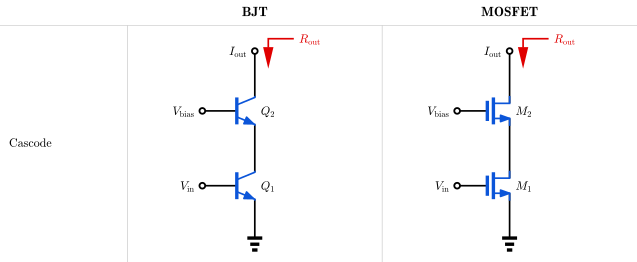

In [3]:
# HIDE/SHOW
show(C.cascode)

**Problem 22**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A bipolar cascode amplifier has Q1 as a common-emitter transistor (input at its base) with Q2 stacked on it (base at a fixed bias, output at its collector); the load is an ideal current source. Both transistors carry $1\,\mathrm{mA}$ and have $\beta=100$, $V_A=5\,\mathrm{V}$. Find the voltage gain. | An NMOS cascode amplifier ($Q_1$ common source, $Q_2$ common gate) has both transistors at $I_D=0.1\,\mathrm{mA}$, $V_{OV}=0.2\,\mathrm{V}$ and $V_A=2\,\mathrm{V}$, and drives a load $R_L$ at the output. Find the gain $A_{v1}$ of the first stage (the common-source stage loaded by the input resistance of $Q_2$), the overall gain $A_v$ and the gain $A_{v2}$ of the second stage for (a) $R_L=20\,\mathrm{k\Omega}$ and (b) $R_L=400\,\mathrm{k\Omega}$. |
| **Given** | $I_C=1\,\mathrm{mA}$, $\beta=100$, $V_A=5\,\mathrm{V}$, $V_T=26\,\mathrm{mV}$ | $I_D=0.1\,\mathrm{mA}$, $V_{OV}=0.2\,\mathrm{V}$, $V_A=2\,\mathrm{V}$, $R_L=20\,\mathrm{k\Omega}$ or $400\,\mathrm{k\Omega}$ |
| **Answer 1** | **Gain method.** $A_v=-G_mR_{out}$ with $G_m\approx g_{m1}$ (almost all of the collector current of Q1 reaches the output short) and $R_{out}$ of the cascode. | **Small-signal parameters.** $g_m=\dfrac{2I_D}{V_{OV}}=1\,\mathrm{mA/V}$, $r_o=\dfrac{V_A}{I_D}=20\,\mathrm{k\Omega}$, $g_mr_o=20$. |
| **Answer 2** | **Parameters.** $g_{m1}=g_{m2}=1/26\,\Omega$, $r_{\pi1}=r_{\pi2}=2.6\,\mathrm{k}\Omega$, $r_{O1}=r_{O2}=5\,\mathrm{k}\Omega$. | **(a) Input resistance of Q2.** $R_{in2}\simeq\dfrac{R_L}{g_{m2}r_{o2}}+\dfrac{1}{g_{m2}}=1+1=2\,\mathrm{k\Omega}$ (the exact value $(R_L+r_o)/(1+g_mr_o)$ is $1.9\,\mathrm{k\Omega}$). |
| **Answer 3** | **Parallel pair.** $r_{O1}\parallel r_{\pi2}=1.71\,\mathrm{k}\Omega$ so $g_{m2}(r_{O1}\parallel r_{\pi2})=65.8$. | **(a) First-stage gain.** $A_{v1}=-g_{m1}(r_{o1}\parallel R_{in2})=-1\times(20\parallel2)=-1.82\,\mathrm{V/V}$. |
| **Answer 4** | **Gain expression.** $A_v\approx-g_{m1}r_{O1}\,g_{m2}(r_{O1}\parallel r_{\pi2})$. | **(a) Overall gain.** $A_v=-g_{m1}\left[(g_{m2}r_{o2}r_{o1})\parallel R_L\right]=-(400\,\mathrm{k\Omega}\parallel20\,\mathrm{k\Omega})\times1\,\mathrm{mA/V}=-19.0\,\mathrm{V/V}$; the second stage contributes $A_{v2}=A_v/A_{v1}=10.5\,\mathrm{V/V}$. |
| **Answer 5** | **Numbers.** $g_{m1}r_{O1}=192.3$; $\lvert A_v\rvert=192.3\times65.8\approx12{,}650$. | **(b) Input resistance of Q2.** $R_{in2}\simeq\dfrac{400}{20}+1=21\,\mathrm{k\Omega}$. |
| **Answer 6** | **Comparison.** A simple CE stage gives $192.3$, so cascoding raises the gain by $g_m(r_O\parallel r_\pi)=65.8$ (the exact two-term $R_{out}$ would give about $12{,}900$). | **(b) First-stage gain.** $A_{v1}=-1\times(20\parallel21)=-10.2\,\mathrm{V/V}$. |
| **Answer 7** | – | **(b) Overall gain.** $A_v=-(400\parallel400)\times1=-200\,\mathrm{V/V}$ and $A_{v2}=A_v/A_{v1}=19.5\,\mathrm{V/V}$ ($19.6$ if $A_{v1}$ is first rounded to $-10.2$). |
| **Result** | – | (a) $A_{v1}=-1.82$, $A_v=-19.0$, $A_{v2}=10.5$ (V/V); (b) $A_{v1}=-10.2$, $A_v=-200$, $A_{v2}=19.5$ (V/V) |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 23**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn cascode amplifier: $Q_1$ (input $V_{in}$ at the base, emitter grounded) under $Q_2$ (base at $V_{b1}$), with an ideal current source $I_1$ from $V_{CC}$ as the load at the collector of $Q_2$ (the output). The voltage gain must be $500$ using $\lvert A_v\rvert\approx g_{m1}r_{O1}\,g_{m1}(r_{O1}\parallel r_{\pi2})$, with $\beta=100$. (a) Minimum Early voltage? (b) Dc component of $V_{in}$ for $0.5\,\mathrm{mA}$. (c) $V_{b1}$ so that $Q_1$ has $V_{CE}=500\,\mathrm{mV}$. | An NMOS cascode amplifier ($M_1$ input device, source grounded; $M_2$ cascode with its gate at $V_{b1}$; ideal current-source load $I_1$ at the drain of $M_2$) must give a voltage gain of 200 at a bias current of $1\,\mathrm{mA}$. With $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$ and $\lambda=0.1\,\mathrm{V^{-1}}$ for both transistors, find $(W/L)_1=(W/L)_2$. |
| **Given** | $\lvert A_v\rvert=500$, $\beta=100$, $I_C=0.5\,\mathrm{mA}$, $V_{CE1}=0.5\,\mathrm{V}$, $I_S=6\times10^{-16}\,\mathrm{A}$, $V_T=26\,\mathrm{mV}$ | $\lvert A_v\rvert=200$, $I_D=1\,\mathrm{mA}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lambda=0.1\,\mathrm{V^{-1}}$ |
| **Answer 1** | **Gain in terms of $V_A$.** $g_mr_O=\dfrac{V_A}{V_T}\equiv a$ and $g_mr_\pi=\beta$, so $\lvert A_v\rvert=a\cdot\dfrac{a\beta}{a+\beta}$. | **Gain of the cascode.** With an ideal load, $\lvert A_v\rvert\approx g_{m1}r_{O1}g_{m2}r_{O2}=(g_mr_O)^2$ for identical devices. |
| **Answer 2** | **(a) Solve.** $\dfrac{100a^2}{a+100}=500\Rightarrow a^2-5a-500=0\Rightarrow a=25$. | **Required intrinsic gain.** $g_mr_O=\sqrt{200}=14.1$ |
| **Answer 3** | **(a) Early voltage.** $V_A=25V_T=0.650\,\mathrm{V}$ (independent of the bias current). | **Output resistance.** $r_O=\dfrac{1}{\lambda I_D}=\dfrac{1}{0.1\times10^{-3}}=10\,\mathrm{k}\Omega$ |
| **Answer 4** | **(b) Input bias.** $V_{in}=V_{BE1}=V_T\ln\dfrac{0.5\,\mathrm{mA}}{6\times10^{-16}\,\mathrm{A}}=0.714\,\mathrm{V}$. | **Transconductance.** $g_m=\dfrac{14.1}{10\,\mathrm{k}\Omega}=1.41\,\mathrm{mS}$ |
| **Answer 5** | **(c) Cascode bias.** $V_{b1}=V_{CE1}+V_{BE2}=0.5+0.714=1.21\,\mathrm{V}$. | **Aspect ratio.** $\dfrac{W}{L}=\dfrac{g_m^2}{2\mu_nC_{ox}I_D}=\dfrac{(1.41\times10^{-3})^2}{2\times100\times10^{-6}\times10^{-3}}=10.0$ |
| **Answer 6** | **Check.** With $V_A=0.65\,\mathrm{V}$ at $0.5\,\mathrm{mA}$: $r_O=1.3\,\mathrm{k}\Omega$, $r_\pi=5.2\,\mathrm{k}\Omega$, $\lvert A_v\rvert=500$. | **Check.** With $W/L=10$: $g_m=\sqrt{2\times10^{-4}\times10\times10^{-3}}=1.41\,\mathrm{mS}$, $(g_mr_O)^2=200$. |
| **Answer 7** | – | **Size of the approximation.** With the output open and an ideal current-source load, no signal current flows through either transistor, so $v_X=-g_{m1}r_{O1}v_{in}$ and $v_{out}=(1+g_{m2}r_{O2})v_X$. The exact gain is therefore $\lvert A_v\rvert=g_{m1}r_{O1}(1+g_{m2}r_{O2})=x^2+x$ with $x=g_mr_O$: 214 for $W/L=10$, and exactly 200 for $x=13.7$, i.e. $W/L=9.32$. The intermediate form $g_{m1}[(1+g_{m2}r_{O2})r_{O1}+r_{O2}]=x^2+2x$ is not more accurate than $(g_mr_O)^2$: it keeps every term of $R_{out}$ but still takes $G_m=g_{m1}$, while in fact $G_m=g_{m1}\dfrac{1+x}{2+x}$; it would give $W/L=8.68$, for which the gain is only 187. |
| **Result** | (a) $V_A=0.650\,\mathrm{V}$; (b) $V_{in}=0.714\,\mathrm{V}$; (c) $V_{b1}=1.21\,\mathrm{V}$ | $(W/L)_1=(W/L)_2\approx10$ from $\lvert A_v\rvert\approx g_{m1}r_{O1}g_{m2}r_{O2}$ (9.32 with the exact gain $g_{m1}r_{O1}(1+g_{m2}r_{O2})$) |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 24**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | An NMOS cascode amplifier with an ideal current-source load ($M_1$ input, $M_2$ cascode) is designed for a gain $A_v$. The widths of both transistors are multiplied by $N$ while their lengths and the bias current stay the same. What happens to the gain? |
| **Given** | – | $W\to NW$, $L$ and $I_D$ unchanged |
| **Answer 1** | – | **Gain in device parameters.** $\lvert A_v\rvert\approx g_{m1}r_{O1}g_{m2}r_{O2}$ with $g_mr_O=\dfrac{\sqrt{2\mu_nC_{ox}(W/L)I_D}}{\lambda I_D}=\dfrac{1}{\lambda}\sqrt{\dfrac{2\mu_nC_{ox}(W/L)}{I_D}}$ |
| **Answer 2** | – | **Hence.** $\lvert A_v\rvert\approx\dfrac{2\mu_nC_{ox}}{\lambda_1\lambda_2I_D}\sqrt{\left(\dfrac{W}{L}\right)_1\left(\dfrac{W}{L}\right)_2}$ |
| **Answer 3** | – | **Effect of the widths.** $\lambda$ depends on $L$, which is unchanged, so $r_O$ stays the same; each $g_m$ grows by $\sqrt N$. |
| **Answer 4** | – | **New gain.** $A_v\to N\,A_v$: the gain rises by the factor $N$ (each intrinsic gain by $\sqrt N$), at the cost of $N$ times the area and capacitance and an overdrive $V_{GS}-V_{TH}$ smaller by $\sqrt N$. |
| **Answer 5** | – | – |
| **Result** | – | The gain is multiplied by $N$ (each $g_m$ by $\sqrt N$, $r_O$ unchanged) |
| **Check** | – | Solved twice, with the same result; no answer is published. |

**Problem 25**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | – |
| **Given** | – | $L\to NL$, $W$ and $I_D$ unchanged; $\lambda\propto1/L$ |
| **Answer 1** | – | **Gain in device parameters.** $\lvert A_v\rvert\approx(g_mr_O)^2$ per pair, $g_mr_O=\dfrac{1}{\lambda}\sqrt{\dfrac{2\mu_nC_{ox}(W/L)}{I_D}}$ |
| **Answer 2** | – | **Effect on $g_m$.** $W/L$ falls by $N$, so each $g_m$ falls by $\sqrt N$. |
| **Answer 3** | – | **Effect on $r_O$.** Channel-length modulation weakens in longer devices, $\lambda\propto1/L$, so $\lambda$ falls by $N$ and $r_O$ rises by $N$. |
| **Answer 4** | – | **Intrinsic gain.** $g_mr_O$ rises by $N/\sqrt N=\sqrt N$ for each transistor. |
| **Answer 5** | – | **New gain.** $A_v\to N\,A_v$: the gain again rises by $N$, but now through $r_O$; the overdrive rises by $\sqrt N$ (less headroom) and the gate area by $N$. |
| **Answer 6** | – | $W/L=2.5$, $\lambda=0.025\,\mathrm{V^{-1}}$, gain 800. |
| **Result** | – | The gain is multiplied by $N$ ($g_m$ down by $\sqrt N$, $r_O$ up by $N$), assuming $\lambda\propto1/L$ |
| **Check** | – | Solved twice, with the same result; no answer is published. |

**Problem 26**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | An NMOS cascode amplifier has a common-source transistor $Q_1$ driving the source of a common-gate transistor $Q_2$, with drain resistor $R_D$ at the output. The two transistors are biased identically and $r_o$ is ignored. The resistance looking into the source of $Q_2$ is $50\,\Omega$. A $5\,\mathrm{mV}$ signal at the gate of $Q_1$ produces $1\,\mathrm{V}$ at the output. Find $g_m$ and $R_D$. |
| **Given** | – | $1/g_{m2}=50\,\Omega$, $v_{gs1}=5\,\mathrm{mV}$, $v_o=1\,\mathrm{V}$, $r_o\to\infty$ |
| **Answer 1** | – | **Transconductance of $Q_2$.** $R_{i2}=\dfrac{1}{g_{m2}}=50\,\Omega\Rightarrow g_{m2}=20\,\mathrm{mA/V}$. |
| **Answer 2** | – | **Same bias for $Q_1$.** $g_{m1}=g_{m2}=20\,\mathrm{mA/V}$. |
| **Answer 3** | – | **Drain current of $Q_1$.** $i_{d1}=g_{m1}v_{gs1}=20\times0.005=0.1\,\mathrm{mA}$ (all of it flows through $Q_2$ to $R_D$). |
| **Answer 4** | – | **Voltage at the cascode node.** $v_{d1}=i_{d1}\times50\,\Omega=5\,\mathrm{mV}$ (gain of $Q_1$ is $-1$). |
| **Answer 5** | – | **Drain resistor.** $v_o=i_{d1}R_D=1\,\mathrm{V}$, so $R_D=\dfrac{1}{0.1\,\mathrm{mA}}=10\,\mathrm{k\Omega}$. |
| **Result** | – | $g_m=20\,\mathrm{mA/V}$, $R_D=10\,\mathrm{k\Omega}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

**Problem 27**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | A MOS cascode amplifier is built from two identical transistors each having $V_A=3\,\mathrm{V}$ and operating at $V_{OV}=0.15\,\mathrm{V}$, driven by an ideal current-source load. Find its open-circuit voltage gain $A_{vo}$. |
| **Given** | – | $V_A=3\,\mathrm{V}$, $V_{OV}=0.15\,\mathrm{V}$ (so $A_0=40$) |
| **Answer 1** | – | **Intrinsic gain of one transistor.** $A_0=g_mr_o=\dfrac{2V_A}{V_{OV}}=\dfrac{2\times3}{0.15}=40\,\mathrm{V/V}$. |
| **Answer 2** | – | **Cascode gain.** $A_{vo}\approx-(g_mr_o)^2=-A_0^2=-40^2=-1600\,\mathrm{V/V}$. |
| **Result** | – | $A_{vo}\approx-1600\,\mathrm{V/V}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

**Problem 28**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | Process: $V_A'=5\,\mathrm{V/\mu m}$, $\mu_nC_{ox}=511\,\mu\mathrm{A/V^2}$, $V_t=0.4\,\mathrm{V}$. Find the bias current $I$, the length $L$, $W/L$, the gate voltage $V_G$ of the upper transistor for the maximum output swing, and the minimum output voltage. |
| **Given** | – | $g_{m1}=3\,\mathrm{mA/V}$, $V_{OV}=0.15\,\mathrm{V}$, $R_o=150\,\mathrm{k}\Omega$, $V_A'=5\,\mathrm{V/\mu m}$, $\mu_nC_{ox}=511\,\mu\mathrm{A/V^2}$, $V_t=0.4\,\mathrm{V}$ |
| **Answer 1** | – | **Bias current.** $g_{m1}=\dfrac{2I}{V_{OV}}\Rightarrow I=\dfrac{3\times0.15}{2}=0.225\,\mathrm{mA}$. |
| **Answer 2** | – | **Early voltage.** $R_o=(g_mr_o)r_o=\dfrac{2V_A}{V_{OV}}\cdot\dfrac{V_A}{I}=\dfrac{2V_A^2}{V_{OV}I}$, so $150=\dfrac{2V_A^2}{0.15\times0.225}\Rightarrow V_A^2=2.53\Rightarrow V_A=1.59\approx1.6\,\mathrm{V}$. |
| **Answer 3** | – | **Length.** $L=V_A/V_A'=1.59/5=0.318\approx0.32\,\mu\mathrm{m}$. |
| **Answer 4** | – | **Aspect ratio.** $225=\tfrac12(511)\dfrac WL(0.15)^2\Rightarrow\dfrac WL=39.1$. |
| **Answer 5** | – | **Gate bias of $Q_2$.** For the largest negative swing, $Q_1$ drain sits at $V_{OV}=0.15\,\mathrm{V}$: $V_G=0.15+V_{GS2}=0.15+0.15+0.4=0.7\,\mathrm{V}$. |
| **Answer 6** | – | **Minimum output.** $v_{O\min}=V_G-V_t=0.7-0.4=0.3\,\mathrm{V}=2V_{OV}$. |
| **Result** | – | $I=0.225\,\mathrm{mA}$, $L\approx0.32\,\mu\mathrm{m}$, $W/L=39.1$, $V_G=0.7\,\mathrm{V}$, $v_{O\min}=0.3\,\mathrm{V}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

**Problem 29**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | An NMOS cascode amplifier has two identical transistors, each $W/L=5.4/0.36$. The input is applied to the gate of $Q_1$ (source grounded), the gate of $Q_2$ is at a dc bias $V_{G2}$, and the drain of $Q_2$ (output) is fed by an ideal current source $I=0.2\,\mathrm{mA}$ and loaded by a resistance $R_L$ to ground. Find the value of $R_L$ that makes the gain $v_o/v_i=-100\,\mathrm{V/V}$, and the gain $A_1$ of the first stage (from the input to the drain of $Q_1$). |
| **Given** | – | $(W/L)_{1,2}=5.4/0.36$, $I_D=0.2\,\mathrm{mA}$, $\mu_nC_{ox}=387\,\mu\mathrm{A/V^2}$, $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$, $L=0.36\,\mu\mathrm{m}$, $A_v=-100\,\mathrm{V/V}$ |
| **Answer 1** | – | **Transconductance.** $g_{m1}=g_{m2}=\sqrt{2\mu_nC_{ox}(W/L)I_D}=\sqrt{2\times0.387\times15\times0.2}=1.52\,\mathrm{mA/V}$. |
| **Answer 2** | – | **Output resistance of a transistor.** $r_{o1}=r_{o2}=\dfrac{V_A^{\prime}L}{I_D}=\dfrac{5\times0.36}{0.2}=9\,\mathrm{k}\Omega$. |
| **Answer 3** | – | **Output resistance of the cascode.** $R_o=r_{o1}+r_{o2}+g_{m2}r_{o2}r_{o1}=9+9+1.524\times9\times9=141\,\mathrm{k}\Omega$. |
| **Answer 4** | – | **Gain equation.** $A_v=-g_{m1}(R_o\parallel R_L)\Rightarrow R_o\parallel R_L=\dfrac{100}{1.524}=65.6\,\mathrm{k}\Omega$. |
| **Answer 5** | – | **Solve for $R_L$.** $\dfrac1{R_L}=\dfrac1{65.6}-\dfrac1{141.4}\Rightarrow R_L=122\,\mathrm{k}\Omega$. |
| **Answer 6** | – | **Resistance looking into the source of $Q_2$.** $R_{in2}=\dfrac{r_{o2}+R_L}{1+g_{m2}r_{o2}}=\dfrac{9+122.4}{1+1.524\times9}=8.93\,\mathrm{k}\Omega$. |
| **Answer 7** | – | **Load of $Q_1$.** $R_{d1}=r_{o1}\parallel R_{in2}=9\parallel8.93=4.48\,\mathrm{k}\Omega$. |
| **Answer 8** | – | **First-stage gain.** $A_1=-g_{m1}R_{d1}=-1.524\times4.48=-6.83\,\mathrm{V/V}$. |
| **Result** | – | $R_L\approx122\,\mathrm{k}\Omega$, $A_1\approx-6.83\,\mathrm{V/V}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

### Other Circuits

**Problem 30**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | The pnp devices have $V_A=4\,\mathrm{V}$, $\beta=50$ and carry about $1\,\mathrm{mA}$. Find the voltage gain. | A CMOS cascode amplifier has NMOS M1 (common source, input at its gate) with NMOS M2 stacked on it, loaded by a PMOS cascode current source (M4 at the supply, M3 stacked below it). Each device carries $0.5\,\mathrm{mA}$. Find the voltage gain. |
| **Given** | $I_C=1\,\mathrm{mA}$; npn: $\beta=100$, $V_A=5\,\mathrm{V}$; pnp: $\beta=50$, $V_A=4\,\mathrm{V}$; $V_T=26\,\mathrm{mV}$ | $(W/L)_{1,2}=30$, $(W/L)_{3,4}=40$, $I_D=0.5\,\mathrm{mA}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.15\,\mathrm{V^{-1}}$ |
| **Answer 1** | – | **NMOS transconductance.** $g_{m1,2}=\sqrt{2\mu_nC_{ox}(W/L)I_D}=\sqrt{2\cdot100\,\mu\cdot30\cdot0.5\,\mathrm{mA}}=1.73\,\mathrm{mS}=1/(577\,\Omega)$. |
| **Answer 2** | **pnp parameters.** $g_m=1/26\,\Omega$, $r_{O3}=r_{O4}=4\,\mathrm{k}\Omega$, $r_{\pi}=50\cdot26=1.3\,\mathrm{k}\Omega$, $r_O\parallel r_\pi=0.981\,\mathrm{k}\Omega$. | **PMOS transconductance.** $g_{m3,4}=\sqrt{2\cdot50\,\mu\cdot40\cdot0.5\,\mathrm{mA}}=1.41\,\mathrm{mS}=1/(707\,\Omega)$. |
| **Answer 3** | **Output resistance of the pnp cascode.** $R_{op}\approx g_{m3}r_{O3}(r_{O4}\parallel r_{\pi3})=153.8\times0.981\,\mathrm{k}\Omega=151\,\mathrm{k}\Omega$. | **Output resistances.** $r_{O1,2}=1/(\lambda_nI_D)=20\,\mathrm{k}\Omega$; $r_{O3,4}=1/(\lambda_pI_D)=13.3\,\mathrm{k}\Omega$. |
| **Answer 4** | **Total output resistance.** $R_{on}\parallel R_{op}=329\parallel151\,\mathrm{k}\Omega=103\,\mathrm{k}\Omega$. | **NMOS cascode.** $R_{on}\approx g_{m2}r_{O2}r_{O1}=1.73\,\mathrm{mS}\cdot(20\,\mathrm{k}\Omega)^2=693\,\mathrm{k}\Omega$. |
| **Answer 5** | **Gain.** $\lvert A_v\rvert=g_{m1}(R_{on}\parallel R_{op})=\dfrac{103.4\,\mathrm{k}\Omega}{26\,\Omega}\approx3980$. | **PMOS cascode.** $R_{op}\approx g_{m3}r_{O3}r_{O4}=1.41\,\mathrm{mS}\cdot(13.3\,\mathrm{k}\Omega)^2=251\,\mathrm{k}\Omega$. |
| **Answer 6** | **Comparison.** The gain is about 3.2 times lower than the ideal-source case (12,650), because the pnp devices have lower $V_A$ and $\beta$. | **Gain.** $A_v\approx-g_{m1}(R_{on}\parallel R_{op})=-1.73\,\mathrm{mS}\cdot185\,\mathrm{k}\Omega\approx-320$. |
| **Result** | $R_{op}\approx151\,\mathrm{k}\Omega$, $R_{on}\approx329\,\mathrm{k}\Omega$, $\lvert A_v\rvert\approx3980$ | $A_v\approx-320$ ($R_{on}\approx693\,\mathrm{k}\Omega$, $R_{op}\approx251\,\mathrm{k}\Omega$) |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 31**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the short-circuit transconductance $G_m$ and the voltage gain of seven stages ($\lambda>0$, $V_A<\infty$, no body effect). (a) NMOS $M_1$ (input at gate, source grounded) loaded by NMOS $M_2$ (drain $V_{DD}$, gate $V_b$, source at the output). (b) Same stack, input at the gate of $M_2$, $M_1$ gate at $V_b$. (c) npn $Q_1$ (input at base, emitter through $R_E$ to ground) loaded by pnp $Q_2$ (emitter $V_{CC}$, base $V_b$). (d) Same stack with input at the base of pnp $Q_2$ and $Q_1$ at fixed base $V_b$ with $R_E$. (e) PMOS $M_2$ (source through $R_E$ to $V_{DD}$, gate $V_{b2}$) over NMOS $M_1$ in common gate (gate $V_{b1}$), whose source goes through $R_S$ to the input; output at the joined drains. (f) As (e) but the input drives the gate of $M_2$ and $R_S$ goes to ground. (g) pnp $Q_2$ with emitter through $R_E$ to $V_{CC}$, input at base, output at collector with $R_C$ to ground. | – |
| **Given** | $g_m$, $r_O$, $r_\pi$ of each device; $R_E$, $R_S$, $R_C$. $G_m=i_{out}/v_{in}$ with the output shorted, $i_{out}$ flowing from the short into the stage, so $A_v=-G_mR_{out}$ | – |
| **Answer 1** | **(a).** $G_m=g_{m1}$; $R_{out}=r_{O1}\parallel r_{O2}\parallel\dfrac{1}{g_{m2}}$; $A_v=-g_{m1}\left(r_{O1}\parallel r_{O2}\parallel\dfrac{1}{g_{m2}}\right)\approx-\dfrac{g_{m1}}{g_{m2}}$ | – |
| **Answer 2** | **(b).** Source follower: $G_m=-g_{m2}$; $R_{out}=r_{O1}\parallel r_{O2}\parallel\dfrac{1}{g_{m2}}$; $A_v=\dfrac{g_{m2}(r_{O1}\parallel r_{O2})}{1+g_{m2}(r_{O1}\parallel r_{O2})}$ | – |
| **Answer 3** | **(c) Gm.** Degenerated CE: $G_m=\dfrac{g_{m1}-R_E/(r_{\pi1}r_{O1})}{1+(g_{m1}+1/r_{\pi1})R_E+R_E/r_{O1}}\approx\dfrac{g_{m1}}{1+g_{m1}R_E}$ | – |
| **Answer 4** | **(c) Gain.** $R_{out}=r_{O2}\parallel\{[1+g_{m1}(R_E\parallel r_{\pi1})]r_{O1}+R_E\parallel r_{\pi1}\}$, $A_v=-G_mR_{out}$ | – |
| **Answer 5** | **(d).** CE pnp: $G_m=g_{m2}$; $R_{out}=r_{O2}\parallel\{[1+g_{m1}(R_E\parallel r_{\pi1})]r_{O1}+R_E\parallel r_{\pi1}\}$; $A_v=-g_{m2}R_{out}$ | – |
| **Answer 6** | **(e) Gm.** Common gate from $R_S$: $G_m=-\dfrac{g_{m1}+1/r_{O1}}{1+(g_{m1}+1/r_{O1})R_S}$ (non-inverting) | – |
| **Answer 7** | **(e) Gain.** $R_{out}=[(1+g_{m2}R_E)r_{O2}+R_E]\parallel[(1+g_{m1}R_S)r_{O1}+R_S]$, $A_v=\dfrac{(g_{m1}+1/r_{O1})R_{out}}{1+(g_{m1}+1/r_{O1})R_S}$ | – |
| **Answer 8** | **(f).** Degenerated PMOS: $G_m=\dfrac{g_{m2}}{1+g_{m2}R_E+R_E/r_{O2}}$; $R_{out}$ as in (e); $A_v=-G_mR_{out}$ | – |
| **Answer 9** | **(g).** $G_m=\dfrac{g_{m2}-R_E/(r_{\pi2}r_{O2})}{1+(g_{m2}+1/r_{\pi2})R_E+R_E/r_{O2}}$; $R_{out}=R_C\parallel\{[1+g_{m2}(R_E\parallel r_{\pi2})]r_{O2}+R_E\parallel r_{\pi2}\}$; $A_v=-G_mR_{out}\approx-\dfrac{R_C}{R_E+1/g_{m2}}$ for $R_C\ll r_O$ | – |
| **Result** | $A_v=-G_mR_{out}$ with: (a) $G_m=g_{m1}$, $R_{out}=r_{O1}\parallel r_{O2}\parallel g_{m2}^{-1}$; (b) $G_m=-g_{m2}$, same $R_{out}$; (c) $G_m\approx g_{m1}/(1+g_{m1}R_E)$; (d) $G_m=g_{m2}$; (e) $G_m=-(g_{m1}+r_{O1}^{-1})/[1+(g_{m1}+r_{O1}^{-1})R_S]$; (f) $G_m=g_{m2}/(1+g_{m2}R_E+R_E/r_{O2})$; (g) degenerated-CE $G_m$ with $R_{out}=R_C\parallel R_{down}$ | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 32**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | For the npn cascode amplifier with an ideal current-source load ($Q_1$ input device, $Q_2$ cascode device, equal currents and Early voltages), Eq. (9.53) gives $A_v\approx-g_{m1}r_{O1}g_{m1}(r_{O1}\parallel r_{\pi2})$. Show that it reduces to $A_v\approx-\dfrac{\beta V_A^2}{V_T(V_A+\beta V_T)}$, independent of the bias current. | In the CMOS cascode amplifier with a PMOS cascode load (NMOS $M_1$ input, NMOS cascode $M_2$, PMOS cascode $M_3$, PMOS current source $M_4$, all carrying the same current), every transistor has $W/L=20/0.18$. With $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.15\,\mathrm{V^{-1}}$, find the bias current that gives a voltage gain of 500. |
| **Given** | $g_m=I_C/V_T$, $r_O=V_A/I_C$, $r_\pi=\beta V_T/I_C$, equal $I_C$, $V_A$, $\beta$ | $W/L=20/0.18$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.15\,\mathrm{V^{-1}}$, $\lvert A_v\rvert=500$ |
| **Answer 1** | **Intrinsic gain.** $g_{m1}r_{O1}=\dfrac{I_C}{V_T}\cdot\dfrac{V_A}{I_C}=\dfrac{V_A}{V_T}$ | – |
| **Answer 2** | **Parallel resistance.** $r_{O1}\parallel r_{\pi2}=\dfrac{(V_A/I_C)(\beta V_T/I_C)}{(V_A+\beta V_T)/I_C}=\dfrac{1}{I_C}\cdot\dfrac{\beta V_AV_T}{V_A+\beta V_T}$ | **Constants.** $W/L=111.1$: $\sqrt{2\mu_nC_{ox}(W/L)}=0.149\,\mathrm{A^{1/2}/V}$, $a=14.9$, $b=4.68$, $\dfrac{ab}{a+b}=3.56$ (units $\mathrm{A^{1/2}\,V}$). |
| **Answer 3** | **Second factor.** $g_{m1}(r_{O1}\parallel r_{\pi2})=\dfrac{\beta V_A}{V_A+\beta V_T}$ | **Solve for the current.** $I_D=\dfrac{0.149\times3.56}{500}=1.06\,\mathrm{mA}$ |
| **Answer 4** | **Product.** $A_v\approx-\dfrac{V_A}{V_T}\cdot\dfrac{\beta V_A}{V_A+\beta V_T}=-\dfrac{\beta V_A^2}{V_T(V_A+\beta V_T)}$; $I_C$ has cancelled | **Small-signal values.** At $1.06\,\mathrm{mA}$: $g_{m1,2}=4.86\,\mathrm{mS}$, $g_{m3,4}=3.44\,\mathrm{mS}$, $r_{O1,2}=9.41\,\mathrm{k}\Omega$, $r_{O3,4}=6.27\,\mathrm{k}\Omega$. |
| **Answer 5** | **Numerical check.** $V_A=5\,\mathrm{V}$, $\beta=100$: | **Check.** $R_{on}=g_{m2}r_{O2}r_{O1}=430\,\mathrm{k}\Omega$, $R_{op}=g_{m3}r_{O3}r_{O4}=135\,\mathrm{k}\Omega$, $g_{m1}(R_{on}\parallel R_{op})=500$. |
| **Answer 6** | – | **Remark.** Eq. (9.72) is the form the chapter uses. A full nodal solution of the four-transistor small-signal circuit gives a gain of 529 at this current and exactly 500 at $I_D=1.13\,\mathrm{mA}$, so the design value is good to about 6 %. (Keeping the full $(1+g_mr_O)r_O+r_O$ in $R_{on}$ and $R_{op}$ while still taking $G_m=g_{m1}$ gives 540 and $1.15\,\mathrm{mA}$, which overstates the gain.) |
| **Result** | $A_v\approx-\dfrac{\beta V_A^2}{V_T(V_A+\beta V_T)}$, independent of $I_C$ | $I_D\approx1.06\,\mathrm{mA}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 33**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn cascode amplifier (input npn $Q_1$ with emitter grounded, cascode npn $Q_2$ with fixed base, ideal current source $I_1=1\,\mathrm{mA}$ as the load at the collector of $Q_2$) must have a voltage gain of 500. With $\beta_1=\beta_2=100$, find the minimum $V_{A1}=V_{A2}$. | – |
| **Given** | $\lvert A_v\rvert=500$, $\beta=100$, $I_1=1\,\mathrm{mA}$, $V_T=26\,\mathrm{mV}$ | – |
| **Answer 1** | **Gain formula.** Eq. (9.130): $\lvert A_v\rvert=\dfrac{\beta V_A^2}{V_T(V_A+\beta V_T)}$, independent of $I_1$ | – |
| **Answer 2** | **Quadratic.** $\beta V_A^2-\lvert A_v\rvert V_TV_A-\lvert A_v\rvert\beta V_T^2=0$: $100V_A^2-13V_A-33.8=0$ | – |
| **Answer 3** | **Solve.** $V_A=\dfrac{13+\sqrt{169+4\cdot100\cdot33.8}}{200}=\dfrac{13+117}{200}=0.650\,\mathrm{V}$ | – |
| **Answer 4** | **Check.** $g_mr_O=0.65/0.026=25$, $r_O=650\,\Omega$, $r_\pi=2.6\,\mathrm{k}\Omega$, $g_m(r_O\parallel r_\pi)=520/26=20$: $\lvert A_v\rvert=25\cdot20=500$ | – |
| **Answer 5** | **Exact form.** Eq. (9.50), $\lvert A_v\rvert=g_{m1}\{[1+g_{m2}(r_{O1}\parallel r_{\pi2})]r_{O2}+r_{O1}\parallel r_{\pi2}\}$, gives $V_A=0.618\,\mathrm{V}$ | – |
| **Result** | – | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 34**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A student applies the input to the base of the upper npn $Q_2$ of a cascode: $Q_1$ at the bottom has its emitter grounded and its base at a fixed $V_{b1}$; $Q_2$ sits on it (emitter on the collector of $Q_1$), takes $v_{in}$ at its base, and drives the output at its collector, which is loaded by an ideal current source $I_1$ from $V_{CC}$. (a) Replacing $Q_1$ by $r_{O1}$, explain why the gain cannot be as high as that of a cascode. (b) With $g_mr_O\gg1$, find $G_m$ and $A_v$. | – |
| **Given** | $g_{m2}$, $r_{\pi2}$, $r_{O2}$, $r_{O1}$, ideal load, $g_mr_O\gg1$ | – |
| **Answer 1** | **(a) Intuition.** $Q_2$ is a CE stage degenerated by $r_{O1}$. The large degeneration raises $R_{out}$ by about $g_{m2}(r_{O1}\parallel r_{\pi2})$ but lowers $G_m$ by about the same factor ($G_m\approx1/r_{O1}$), so $\lvert A_v\rvert$ stays below one intrinsic gain $g_{m2}r_{O2}$, as for a simple CE stage. In a cascode, $Q_1$ supplies the full $g_{m1}$ and $Q_2$ only raises $R_{out}$ | – |
| **Answer 2** | **(b) Gm.** With output shorted: $G_m=\dfrac{g_{m2}-r_{O1}/(r_{\pi2}r_{O2})}{1+(g_{m2}+1/r_{\pi2})r_{O1}+r_{O1}/r_{O2}}\approx\dfrac{g_{m2}}{1+g_{m2}r_{O1}(1+1/\beta)}\approx\dfrac{1}{r_{O1}}$ | – |
| **Answer 3** | **(b) Rout.** $R_{out}=[1+g_{m2}(r_{O1}\parallel r_{\pi2})]r_{O2}+r_{O1}\parallel r_{\pi2}\approx g_{m2}r_{O2}(r_{O1}\parallel r_{\pi2})$ | – |
| **Answer 4** | **(b) Gain.** $A_v=-G_mR_{out}\approx-g_{m2}r_{O2}\dfrac{r_{\pi2}}{r_{O1}+r_{\pi2}}$ | – |
| **Answer 5** | **(b) Equal devices.** With $r_O=V_A/I_C$, $r_\pi=\beta V_T/I_C$: $A_v\approx-\dfrac{\beta V_A}{V_A+\beta V_T}$. Example $V_A=5\,\mathrm{V}$, $\beta=100$, $1\,\mathrm{mA}$: $A_v\approx-65.8$ ($-65.1$ from the full expressions), versus $-12{,}650$ for the cascode | – |
| **Result** | $G_m\approx\dfrac{g_{m2}}{1+g_{m2}r_{O1}}\approx\dfrac{1}{r_{O1}}$, $A_v\approx-g_{m2}r_{O2}\dfrac{r_{\pi2}}{r_{O1}+r_{\pi2}}\approx-\dfrac{\beta V_A}{V_A+\beta V_T}$ | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 35**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A common-base stage is cascoded: npn $Q_1$ has its base at the fixed bias $V_{b1}$ and its emitter driven directly by the input source $V_{in}$; npn $Q_2$ has its base at the fixed bias $V_{b2}$, its emitter at the collector of $Q_1$, and its collector at the output node, which is loaded by an ideal current source $I_1$ from $V_{CC}$. Both transistors have finite $\beta$ and Early voltage. Find the short-circuit transconductance $G_m$ and the voltage gain $v_{out}/v_{in}$. | – |
| **Given** | $Q_1$: $g_{m1}$, $r_{O1}$; $Q_2$: $g_{m2}$, $r_{\pi2}$, $r_{O2}$; ideal current-source load $I_1$ | – |
| **Answer 1** | **Lemma.** With an ideal current-source load the gain is $A_v=v_{out}/v_{in}=G_mR_{out}$ up to sign; here a rise of $v_{in}$ lowers $V_{BE1}$, lowers the current pulled from the output and raises $v_{out}$, so the gain is positive. | – |
| **Answer 2** | **Short-circuit current of $Q_1$.** With the output shorted, node $X$ (collector of $Q_1$) sits near ground because it sees $1/g_{m2}$. $Q_1$ has $v_{be1}=-v_{in}$ and $v_{ce1}\approx-v_{in}$, so $i_{C1}=-(g_{m1}+1/r_{O1})v_{in}$. | – |
| **Answer 3** | **Transfer through $Q_2$.** $Q_2$ passes this current to the output (all but its base current), so $G_m\approx g_{m1}+\dfrac{1}{r_{O1}}\approx g_{m1}$. | – |
| **Answer 4** | **Resistance below $Q_2$.** With $v_{in}=0$ the emitter of $Q_1$ is at ac ground and its base is fixed, so looking into its collector one sees $r_{O1}$. | – |
| **Answer 5** | **Output resistance.** $Q_2$ is degenerated by $r_{O1}$: $R_{out}=[1+g_{m2}(r_{O1}\parallel r_{\pi2})]r_{O2}+r_{O1}\parallel r_{\pi2}$. | – |
| **Answer 6** | **Voltage gain.** $A_v=G_mR_{out}\approx\left(g_{m1}+\dfrac{1}{r_{O1}}\right)\{[1+g_{m2}(r_{O1}\parallel r_{\pi2})]r_{O2}+r_{O1}\parallel r_{\pi2}\}\approx g_{m1}g_{m2}r_{O2}(r_{O1}\parallel r_{\pi2})$ | – |
| **Answer 7** | **Numerical check.** With $I_C=1\,\mathrm{mA}$, $\beta=100$, $V_A=10\,\mathrm{V}$ ($g_m=1/26\,\Omega$, $r_\pi=2.6\,\mathrm{k}\Omega$, $r_O=10\,\mathrm{k}\Omega$): $R_{out}=806\,\mathrm{k}\Omega$, and the formulas give $G_m=0.0386\,\mathrm{S}$ and $A_v=+31\,100$; a full nodal solution gives $G_m=0.0381\,\mathrm{S}$ and $A_v=+30\,700$ (within 1.3 %, the base current of $Q_2$). | – |
| **Result** | $G_m\approx g_{m1}+1/r_{O1}\approx g_{m1}$; $A_v\approx +(g_{m1}+1/r_{O1})\{[1+g_{m2}(r_{O1}\parallel r_{\pi2})]r_{O2}+r_{O1}\parallel r_{\pi2}\}\approx g_{m1}g_{m2}r_{O2}(r_{O1}\parallel r_{\pi2})$ (non-inverting) | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 36**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Four npn cascode amplifiers, each with input at the base of the lower transistor $Q_2$ (emitter grounded unless noted), cascode device $Q_1$ with its base at $V_{b1}$ and its collector at the output, and an ideal current source $I_1$ from $V_{CC}$ as load. (a) A resistor $R_P$ connects the base of $Q_1$ to its emitter. (b) $R_P$ connects the collector of $Q_1$ (output) to its emitter. (c) No $R_P$, but the emitter of $Q_2$ goes to ground through $R_E$. (d) A pnp $Q_3$, emitter at $V_{CC}$ and base at $V_{b3}$, has its collector tied to the node between $Q_1$ and $Q_2$. Find the voltage gain of each, with finite $\beta$ and Early voltage. | Four CMOS cascode amplifiers, each with NMOS $M_1$ (source grounded), NMOS cascode $M_2$ (gate at $V_{b2}$, drain at the output), PMOS cascode $M_3$ (gate at $V_{b3}$, drain at the output) and PMOS source $M_4$ (gate at $V_{b4}$, source at $V_{DD}$). (a) Input at the gate of $M_1$; a resistor $R_P$ from the output to the source of $M_2$. (b) Input at the gate of $M_1$; $R_P$ from the source of $M_2$ to ground. (c) $M_1$ gate at $V_{b1}$; a PMOS $M_5$ with its gate at $V_{in}$, source at $V_{DD}$, drain at the source of $M_2$. (d) $M_1$ gate at $V_{b1}$; an NMOS $M_5$ with its gate at $V_{in}$, source grounded, drain at the node between $M_4$ and $M_3$. Find each voltage gain, with $g_mr_O\gg1$. |
| **Given** | $g_{m}$, $r_\pi$, $r_O$ of each device; $R_P$, $R_E$; ideal load $I_1$ | $g_{m}$, $r_O$ of $M_1\ldots M_5$; $R_P$; $g_mr_O\gg1$ |
| **Answer 1** | **Method.** Use $A_v=-G_mR_{out}$. Call $X$ the node between $Q_2$ and $Q_1$. In every case $Q_1$ is a degenerated device: $R_{out}=[1+g_{m1}(R_X\parallel r_{\pi1})]r_{O1}+R_X\parallel r_{\pi1}$, where $R_X$ is the resistance from $X$ to ac ground excluding $Q_1$. | **Method.** $A_v=-G_m(R_{on}\parallel R_{op})$, with $R_{op}\approx g_{m3}r_{O3}r_{O4}$ unless $M_5$ changes it. Call $X$ the source of $M_2$ and $Y$ the source of $M_3$. |
| **Answer 2** | **(a) Resistance at $X$.** The base of $Q_1$ is at ac ground, so $R_P$ appears from $X$ to ground in parallel with $r_{O2}$ and $r_{\pi1}$: $R_X\parallel r_{\pi1}=r_{O2}\parallel R_P\parallel r_{\pi1}$. $G_m\approx g_{m2}$ as long as $R_P\gg1/g_{m1}$. | **(a) $R_P$ across $M_2$.** $R_P$ sits in parallel with $r_{O2}$: $R_{on}=(1+g_{m2}r_{O1})(r_{O2}\parallel R_P)+r_{O1}\approx g_{m2}r_{O1}(r_{O2}\parallel R_P)$; $G_m\approx g_{m1}$. |
| **Answer 3** | **(a) Gain.** $A_v\approx-g_{m2}\{[1+g_{m1}(r_{O2}\parallel R_P\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel R_P\parallel r_{\pi1}\}$ | **(a) Gain.** $A_v\approx-g_{m1}\{[g_{m2}r_{O1}(r_{O2}\parallel R_P)]\parallel(g_{m3}r_{O3}r_{O4})\}$ |
| **Answer 4** | **(b) $R_P$ across $Q_1$.** $R_P$ connects the same two nodes as $r_{O1}$, so it simply replaces $r_{O1}$ by $r_{O1}\parallel R_P$; $G_m\approx g_{m2}$. | **(b) $R_P$ from $X$ to ground.** $R_P$ sits in parallel with $r_{O1}$: $R_{on}\approx g_{m2}r_{O2}(r_{O1}\parallel R_P)$. The signal current $g_{m1}v_{in}$ now divides between $R_P\parallel r_{O1}$ and $1/g_{m2}$: $G_m\approx g_{m1}\dfrac{r_{O1}\parallel R_P}{r_{O1}\parallel R_P+1/g_{m2}}$ ($\approx g_{m1}$ if $R_P\gg1/g_{m2}$). |
| **Answer 5** | **(b) Gain.** $A_v\approx-g_{m2}\{[1+g_{m1}(r_{O2}\parallel r_{\pi1})](r_{O1}\parallel R_P)+r_{O2}\parallel r_{\pi1}\}$ | **(b) Gain.** $A_v\approx-G_m\{[g_{m2}r_{O2}(r_{O1}\parallel R_P)]\parallel(g_{m3}r_{O3}r_{O4})\}$ |
| **Answer 6** | **(c) Degenerated input device.** $G_m\approx\dfrac{g_{m2}}{1+g_{m2}R_E}$ and $R_X=[1+g_{m2}(R_E\parallel r_{\pi2})]r_{O2}+R_E\parallel r_{\pi2}\gg r_{\pi1}$, so $R_{out}\approx(1+g_{m1}r_{\pi1})r_{O1}\approx\beta_1r_{O1}$. | **(c) Folded input.** $M_5$ injects $-g_{m5}v_{in}$ into $X$; nearly all of it flows into the low impedance $1/g_{m2}$ and changes the current of $M_2$ by $+g_{m5}v_{in}$, so $G_m\approx g_{m5}\dfrac{r_{O1}\parallel r_{O5}}{r_{O1}\parallel r_{O5}+1/g_{m2}}\approx g_{m5}$. $X$ now sees $r_{O1}\parallel r_{O5}$: $R_{on}\approx g_{m2}r_{O2}(r_{O1}\parallel r_{O5})$. |
| **Answer 7** | **(c) Gain.** $A_v\approx-\dfrac{g_{m2}}{1+g_{m2}R_E}\{[1+g_{m1}(R_X\parallel r_{\pi1})]r_{O1}+R_X\parallel r_{\pi1}\}\approx-\dfrac{g_{m2}\beta_1r_{O1}}{1+g_{m2}R_E}$ | **(c) Gain.** $A_v\approx-G_m\{[g_{m2}r_{O2}(r_{O1}\parallel r_{O5})]\parallel(g_{m3}r_{O3}r_{O4})\}$ |
| **Answer 8** | **(d) Extra device at $X$.** $Q_3$ is a current source whose collector adds $r_{O3}$ from $X$ to ac ground; it also adds its bias current, so $Q_2$ carries $I_1+I_{C3}$ (larger $g_{m2}$, smaller $r_{O2}$). | **(d) Input in the load.** $M_5$ draws $g_{m5}v_{in}$ from $Y$, which comes almost entirely through $M_3$, so the output current changes by $g_{m5}v_{in}$ and $G_m\approx g_{m5}\dfrac{r_{O4}\parallel r_{O5}}{r_{O4}\parallel r_{O5}+1/g_{m3}}\approx g_{m5}$; $Y$ now sees $r_{O4}\parallel r_{O5}$: $R_{op}\approx g_{m3}r_{O3}(r_{O4}\parallel r_{O5})$, $R_{on}\approx g_{m2}r_{O2}r_{O1}$. |
| **Answer 9** | **(d) Gain.** $A_v\approx-g_{m2}\{[1+g_{m1}(r_{O2}\parallel r_{O3}\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel r_{O3}\parallel r_{\pi1}\}$ | **(d) Gain.** $A_v\approx-G_m\{(g_{m2}r_{O2}r_{O1})\parallel[g_{m3}r_{O3}(r_{O4}\parallel r_{O5})]\}$ (inverting: a rise of $v_{in}$ steals current from the load). |
| **Answer 10** | **Numerical check.** With $I_1=1\,\mathrm{mA}$, $\beta=100$, $V_A=10\,\mathrm{V}$: (a) $R_P=2\,\mathrm{k}\Omega$: formula $-15\,400$, nodal $-15\,100$; (b) $R_P=20\,\mathrm{k}\Omega$: $-20\,700$ vs. $-20\,400$; (c) $R_E=200\,\Omega$: $-4340$ vs. $-4250$, with $R_{out}=982\,\mathrm{k}\Omega\approx\beta r_O$; (d) $I_{C3}=I_1$: $-44\,100$ vs. $-43\,300$ (differences of 1 to 2.5 % come from base currents and the finite $1/g_{m1}$ at $X$). | **Numerical check.** With NMOS $g_m=2\,\mathrm{mS}$, $r_O=20\,\mathrm{k}\Omega$, PMOS $g_m=1.41\,\mathrm{mS}$, $r_O=13.3\,\mathrm{k}\Omega$, $R_P=5\,\mathrm{k}\Omega$, $M_5$ like the other devices of its type, the formulas give (a) $-221$, (b) $-196$, (c) $-205$, (d) $-262$, against $-216$, $-197$, $-205$, $-263$ from a nodal solution. Without the current-division factors, (b) to (d) would be 6 to 12 % high. |
| **Result** | (a) $A_v\approx-g_{m2}\{[1+g_{m1}(r_{O2}\parallel R_P\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel R_P\parallel r_{\pi1}\}$; (b) $A_v\approx-g_{m2}\{[1+g_{m1}(r_{O2}\parallel r_{\pi1})](r_{O1}\parallel R_P)+r_{O2}\parallel r_{\pi1}\}$; (c) $A_v\approx-\dfrac{g_{m2}\beta_1r_{O1}}{1+g_{m2}R_E}$; (d) $A_v\approx-g_{m2}\{[1+g_{m1}(r_{O2}\parallel r_{O3}\parallel r_{\pi1})]r_{O1}+r_{O2}\parallel r_{O3}\parallel r_{\pi1}\}$ | (a) $-g_{m1}\{[g_{m2}r_{O1}(r_{O2}\parallel R_P)]\parallel g_{m3}r_{O3}r_{O4}\}$; (b) $-G_m\{[g_{m2}r_{O2}(r_{O1}\parallel R_P)]\parallel g_{m3}r_{O3}r_{O4}\}$, $G_m\approx g_{m1}$; (c) $-g_{m5}\{[g_{m2}r_{O2}(r_{O1}\parallel r_{O5})]\parallel g_{m3}r_{O3}r_{O4}\}$; (d) $-g_{m5}\{g_{m2}r_{O2}r_{O1}\parallel[g_{m3}r_{O3}(r_{O4}\parallel r_{O5})]\}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 37**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | In the bipolar cascode amplifier with a cascode load (npn $Q_1$ input device with emitter grounded, npn $Q_2$ cascode, pnp $Q_3$ cascode and pnp $Q_4$ current source, all bases except that of $Q_1$ at fixed bias, all four carrying the same collector current $I_C$), take $\beta_1=\beta_2=\beta_N$, $V_{A1}=V_{A2}=V_{A,N}$, $\beta_3=\beta_4=\beta_P$, $V_{A3}=V_{A4}=V_{A,P}$. Rewrite the gain $A_v\approx-g_{m1}\{[g_{m2}r_{O2}(r_{O1}\parallel r_{\pi2})]\parallel[g_{m3}r_{O3}(r_{O4}\parallel r_{\pi3})]\}$ in terms of these quantities and decide whether it depends on the bias current. | For the CMOS cascode amplifier with a PMOS cascode load (NMOS $M_1$ input, NMOS cascode $M_2$, PMOS cascode $M_3$, PMOS source $M_4$, all carrying $I_D$), the gain is $A_v\approx-g_{m1}[(g_{m2}r_{O2}r_{O1})\parallel(g_{m3}r_{O3}r_{O4})]$. Using $g_m=\sqrt{2\mu C_{ox}(W/L)I_D}$ and $r_O=1/(\lambda I_D)$, express the gain in device parameters and sketch it versus $I_D$. |
| **Given** | $g_m=I_C/V_T$, $r_O=V_A/I_C$, $r_\pi=\beta V_T/I_C$, same $I_C$ in all devices | $\mu_nC_{ox}$, $\mu_pC_{ox}$, $(W/L)_{1\ldots4}$, $\lambda_n$, $\lambda_p$, common drain current $I_D$ |
| **Answer 1** | **Device parameters.** $g_m=\dfrac{I_C}{V_T}$, $r_O=\dfrac{V_A}{I_C}$, $r_\pi=\dfrac{\beta V_T}{I_C}$, so $g_mr_O=\dfrac{V_A}{V_T}$. | **Pull-down resistance.** $R_{on}=g_{m2}r_{O2}r_{O1}=\sqrt{2\mu_nC_{ox}(W/L)_2I_D}\cdot\dfrac{1}{\lambda_n^2I_D^2}=\dfrac{a}{I_D^{3/2}}$, with $a=\dfrac{\sqrt{2\mu_nC_{ox}(W/L)_2}}{\lambda_n^2}$ |
| **Answer 2** | **Pull-down resistance.** $R_{on}=g_{m2}r_{O2}(r_{O1}\parallel r_{\pi2})=\dfrac{V_{A,N}}{V_T}\cdot\dfrac{V_{A,N}\beta_NV_T}{I_C(V_{A,N}+\beta_NV_T)}=\dfrac{1}{I_C}\cdot\dfrac{\beta_NV_{A,N}^2}{V_{A,N}+\beta_NV_T}$ | **Pull-up resistance.** $R_{op}=g_{m3}r_{O3}r_{O4}=\dfrac{b}{I_D^{3/2}}$, with $b=\dfrac{\sqrt{2\mu_pC_{ox}(W/L)_3}}{\lambda_p^2}$ |
| **Answer 3** | **Pull-up resistance.** $R_{op}=g_{m3}r_{O3}(r_{O4}\parallel r_{\pi3})=\dfrac{1}{I_C}\cdot\dfrac{\beta_PV_{A,P}^2}{V_{A,P}+\beta_PV_T}$ | **Parallel combination.** $R_{on}\parallel R_{op}=\dfrac{1}{I_D^{3/2}}\cdot\dfrac{ab}{a+b}$ |
| **Answer 4** | **Gain.** Write $X_N=\dfrac{\beta_NV_{A,N}^2}{V_{A,N}+\beta_NV_T}$ and $X_P=\dfrac{\beta_PV_{A,P}^2}{V_{A,P}+\beta_PV_T}$. Then $A_v=-\dfrac{I_C}{V_T}\cdot\dfrac{1}{I_C}\cdot\dfrac{X_NX_P}{X_N+X_P}=-\dfrac{1}{V_T}\cdot\dfrac{X_NX_P}{X_N+X_P}$ | **Gain in device parameters.** $A_v\approx-\sqrt{2\mu_nC_{ox}(W/L)_1I_D}\cdot\dfrac{1}{I_D^{3/2}}\cdot\dfrac{ab}{a+b}=-\dfrac{\sqrt{2\mu_nC_{ox}(W/L)_1}}{I_D}\cdot\dfrac{ab}{a+b}$ |
| **Answer 5** | **Bias dependence.** $I_C$ cancels: $g_{m1}\propto I_C$ while $R_{on}\parallel R_{op}\propto1/I_C$, so the gain does not depend on the bias current (as long as $\beta$ and $V_A$ stay constant). | **Sketch.** $\lvert A_v\rvert\propto1/I_D$: a hyperbola, very large at small currents and falling as $1/I_D$ (halving $I_D$ doubles the gain), as long as the devices stay in saturation (strong inversion). |
| **Answer 6** | – | – |
| **Result** | $A_v\approx-\dfrac{1}{V_T}\cdot\dfrac{X_NX_P}{X_N+X_P}$ with $X_{N,P}=\dfrac{\beta_{N,P}V_{A,N,P}^2}{V_{A,N,P}+\beta_{N,P}V_T}$: independent of $I_C$ | $A_v\approx-\dfrac{\sqrt{2\mu_nC_{ox}(W/L)_1}}{I_D}\cdot\dfrac{ab}{a+b}$, $a=\dfrac{\sqrt{2\mu_nC_{ox}(W/L)_2}}{\lambda_n^2}$, $b=\dfrac{\sqrt{2\mu_pC_{ox}(W/L)_3}}{\lambda_p^2}$; $\lvert A_v\rvert\propto1/I_D$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 38**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A bipolar cascode amplifier was built wrongly: npn $Q_1$ (input $v_{in}$ at the base, emitter grounded) and npn cascode $Q_2$ (base at $V_{b1}$, collector at the output) are loaded by pnp $Q_3$ (base at $V_{b2}$, collector at the output), but the pnp $Q_4$ above $Q_3$ has its base tied to its own collector (diode-connected), emitter at $V_{CC}$, collector at the emitter of $Q_3$. All devices carry about the same current. Find the voltage gain with finite $\beta$ and Early voltage. | A CMOS cascode was wired wrongly: NMOS $M_1$ (gate at $V_{b1}$, source grounded), NMOS $M_2$ (gate at $V_{b2}$, source at the drain of $M_1$, drain at the output), PMOS $M_3$ (gate at $V_{b3}$, drain at the output) and PMOS $M_4$ (gate at $V_{b4}$, source at $V_{DD}$, drain at the source of $M_3$). The input source $V_{in}$ is connected to the node between $M_1$ and $M_2$ instead of the gate of $M_1$. Find the voltage gain (finite $r_O$). |
| **Given** | $g_{m}$, $r_\pi$, $r_O$ of $Q_1$ to $Q_4$ | $g_{m2}$, $r_{O1}\ldots r_{O4}$, $g_{m3}$; ideal input voltage source |
| **Answer 1** | **Short-circuit transconductance.** As in any cascode, $G_m\approx g_{m1}$, so $A_v=-g_{m1}(R_{on}\parallel R_{op})$. | **Effect of the wrong connection.** The ideal source fixes the source voltage of $M_2$, so $M_1$ (a current source in parallel with the source) plays no role: the circuit is a common-gate stage driven at its source. |
| **Answer 2** | **Pull-down resistance.** $Q_2$ degenerated by $r_{O1}$: $R_{on}=[1+g_{m2}(r_{O1}\parallel r_{\pi2})]r_{O2}+r_{O1}\parallel r_{\pi2}\approx\beta_2r_{O2}$ when $r_{O1}\gg r_{\pi2}$. | **Load.** The PMOS cascode presents $R_{op}=(1+g_{m3}r_{O4})r_{O3}+r_{O4}\approx g_{m3}r_{O3}r_{O4}$. |
| **Answer 3** | **What $Q_4$ now presents.** A diode-connected transistor is a small resistance: $\dfrac{1}{g_{m4}}\parallel r_{\pi4}\parallel r_{O4}\approx\dfrac{1}{g_{m4}}$ from the emitter of $Q_3$ to ac ground, instead of $r_{O4}$. | **Current through $M_2$.** With $v_{gs2}=-v_{in}$: $i_{D2}=-g_{m2}v_{in}+\dfrac{v_{out}-v_{in}}{r_{O2}}$ (drain to source). |
| **Answer 4** | **Pull-up resistance.** $Q_3$ is degenerated by $R_E=r_{\pi3}\parallel\dfrac{1}{g_{m4}}\parallel r_{\pi4}\parallel r_{O4}$: $R_{op}=(1+g_{m3}R_E)r_{O3}+R_E$. With $g_{m3}\approx g_{m4}$, $g_{m3}R_E\approx1$, so $R_{op}\approx2r_{O3}$. | **KCL at the output.** $\dfrac{v_{out}}{R_{op}}+i_{D2}=0\Rightarrow v_{out}\left(\dfrac{1}{R_{op}}+\dfrac{1}{r_{O2}}\right)=v_{in}\left(g_{m2}+\dfrac{1}{r_{O2}}\right)$ |
| **Answer 5** | **Voltage gain.** $A_v\approx-g_{m1}\{[(1+g_{m3}R_E)r_{O3}+R_E]\parallel R_{on}\}\approx-g_{m1}(2r_{O3}\parallel\beta_2r_{O2})\approx-2g_{m1}r_{O3}$, i.e. only about twice the gain of a simple common-emitter stage loaded by $r_{O3}$. | **Voltage gain.** $A_v=\dfrac{(1+g_{m2}r_{O2})R_{op}}{R_{op}+r_{O2}}\approx1+g_{m2}r_{O2}\approx g_{m2}r_{O2}$, since $R_{op}\gg r_{O2}$: non-inverting and only about one intrinsic gain. |
| **Answer 6** | **Numerical check.** With $I_C=1\,\mathrm{mA}$, npn $\beta=100$, $V_A=10\,\mathrm{V}$, pnp $\beta=50$, $V_A=5\,\mathrm{V}$: $R_{op}=9.81\,\mathrm{k}\Omega\approx2r_{O3}$, formula $A_v=-373$, nodal solution $-368$. | **Numerical check.** With $g_{m2}=2\,\mathrm{mS}$, $r_{O1,2}=20\,\mathrm{k}\Omega$, $g_{m3}=1.41\,\mathrm{mS}$, $r_{O3,4}=13.3\,\mathrm{k}\Omega$: $R_{op}=277\,\mathrm{k}\Omega$, formula $A_v=38.2$, nodal $38.2$ (versus $g_{m2}r_{O2}=40$). |
| **Result** | $A_v\approx-g_{m1}\{[(1+g_{m3}R_E)r_{O3}+R_E]\parallel[(1+g_{m2}(r_{O1}\parallel r_{\pi2}))r_{O2}]\}\approx-2g_{m1}r_{O3}$, $R_E=r_{\pi3}\parallel(1/g_{m4})$ | $A_v=\dfrac{(1+g_{m2}r_{O2})R_{op}}{R_{op}+r_{O2}}\approx g_{m2}r_{O2}$, $R_{op}=(1+g_{m3}r_{O4})r_{O3}+r_{O4}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 39**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A bipolar cascode amplifier on $V_{CC}=2.5\,\mathrm{V}$: npn $Q_1$ (input $V_{in}$, emitter grounded) and npn cascode $Q_2$ (base $V_{b1}$); above the output node a pnp cascode $Q_3$ (base $V_{b2}$) and a pnp current source $Q_4$ (base $V_{b3}$, emitter at $V_{CC}$). Design for a power budget of $2\,\mathrm{mW}$, choose $V_{b1}$ and $V_{b2}$ so that $Q_1$ and $Q_4$ have a base-collector forward bias of $200\,\mathrm{mV}$, and find the voltage gain. Use the design-problem default device data. | A cascode amplifier with a cascode current-source load has all four transistors identical, with $g_mr_o=20$: NMOS $Q_1$ (gate driven by $v_i$, source grounded) with NMOS cascode $Q_2$ above it, and PMOS cascode $Q_3$ above the output node with PMOS source $Q_4$ (gates of $Q_2,Q_3,Q_4$ at dc bias). The output is open-circuited. Let $i_1=g_mv_i$ be the signal current of $Q_1$; $i_2$ is the part flowing in $r_{o1}$, $i_3$ the part flowing into the source of $Q_2$, $i_4$ the current in $Q_2$, $i_5$ the current in $Q_3$, $i_6$ the controlled-source current of $Q_4$ and $i_7$ the current in $r_{o4}$. $v_1$, $v_2$, $v_3$ are the signal voltages at the drain of $Q_1$, at the output and at the drain of $Q_4$. (a) Give the resistances $R_1$ (looking into the drain of $Q_1$), $R_2$ (looking up into $Q_3$) and $R_3$ (looking into the source of $Q_2$). (b) Find all currents in terms of $g_mv_i$. (c) Find $v_1,v_2,v_3$. (d) For a $5\,\mathrm{mV}$ peak sine input describe the waveforms $v_i,v_1,v_2,v_3$ with their peaks. |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $P=2\,\mathrm{mW}$, $V_{BC}=0.2\,\mathrm{V}$ for $Q_1$, $Q_4$, $I_S=6\times10^{-16}\,\mathrm{A}$, $\beta_n=100$, $\beta_p=50$, $V_A=5\,\mathrm{V}$ | $g_mr_o=20$, $v_i$ a $5\,\mathrm{mV}$ peak sine; $g_m$, $r_o$ equal in all four transistors |
| **Answer 1** | **Bias current.** $I_C=\dfrac{2\,\mathrm{mW}}{2.5\,\mathrm{V}}=0.8\,\mathrm{mA}$. | **(a) Resistances.** $R_1=r_o$; $R_2=(g_mr_o)r_o$ (cascode formed by $Q_3$ on $Q_4$); $R_3=\dfrac{R_2+r_o}{g_mr_o}\approx r_o$ (resistance into the source of $Q_2$, loaded by $R_2$). |
| **Answer 2** | **Base-emitter voltages.** $V_{BE}=\lvert V_{BE}\rvert=V_T\ln\dfrac{0.8\,\mathrm{mA}}{6\times10^{-16}\,\mathrm{A}}=0.726\,\mathrm{V}$, so $V_{in}=0.726\,\mathrm{V}$ and $V_{b3}=2.5-0.726=1.77\,\mathrm{V}$. | **(b) Split of $i_1$.** $i_1=g_mv_i$; $i_2=i_1\dfrac{R_3}{R_3+r_o}=i_1\dfrac{r_o}{2r_o}=\tfrac12g_mv_i$ flows in $r_{o1}$. |
| **Answer 3** | **$V_{b1}$.** Collector of $Q_1$ at $V_X=V_{BE1}-0.2=0.526\,\mathrm{V}$, so $V_{b1}=V_X+V_{BE2}=1.25\,\mathrm{V}$. | **(b) Other currents.** $i_3=i_1-i_2=\tfrac12g_mv_i$; $i_4=i_3=\tfrac12g_mv_i$; $i_5=i_4=\tfrac12g_mv_i$; $i_6=0$ because $v_{sg4}=0$ (gate of $Q_4$ at ac ground); $i_7=i_5=\tfrac12g_mv_i$. |
| **Answer 4** | **$V_{b2}$.** Collector of $Q_4$ at $V_Y=V_{b3}+0.2=1.97\,\mathrm{V}$, so $V_{b2}=V_Y-\lvert V_{BE3}\rvert=1.25\,\mathrm{V}$. | **(c) Voltages.** $v_1=-i_2r_o=-\tfrac12(g_mr_o)v_i$; $v_2=-i_4R_2=-\tfrac12g_m(g_mr_o)r_ov_i=-\tfrac12(g_mr_o)^2v_i$; $v_3=-i_5R_1=-\tfrac12(g_mr_o)v_i$. |
| **Answer 5** | **Small-signal parameters.** $g_m=30.8\,\mathrm{mS}$, $r_O=6.25\,\mathrm{k}\Omega$, $r_{\pi n}=3.25\,\mathrm{k}\Omega$, $r_{\pi p}=1.63\,\mathrm{k}\Omega$. | **Numbers for $g_mr_o=20$.** $v_1/v_i=-10$, $v_2/v_i=-200$, $v_3/v_i=-10$. |
| **Answer 6** | **Output impedances.** $R_{on}=[1+g_m(r_O\parallel r_{\pi n})]r_O+r_O\parallel r_{\pi n}=420\,\mathrm{k}\Omega$; $R_{op}=[1+g_m(r_O\parallel r_{\pi p})]r_O+r_O\parallel r_{\pi p}=256\,\mathrm{k}\Omega$. | **(d) Waveforms.** $v_i$: $5\,\mathrm{mV}$ peak. $\hat v_1=10\times5=50\,\mathrm{mV}$ peak, $180^\circ$ out of phase with $v_i$. $\hat v_2=200\times5\,\mathrm{mV}=1\,\mathrm{V}$ peak, $180^\circ$ out of phase. $\hat v_3=50\,\mathrm{mV}$ peak, $180^\circ$ out of phase. |
| **Answer 7** | **Voltage gain.** $A_v=-g_m(R_{on}\parallel R_{op})=-30.8\,\mathrm{mS}\times159\,\mathrm{k}\Omega\approx-4890$. | **Check with a nodal solution.** Solving the three node equations without the approximations (the resistance into $Q_3$ is then $22r_o$, not $20r_o$) gives $v_1/v_i=-10.5$, $v_2/v_i=-210$, $v_3/v_i=-9.5$: within about 5 % of the approximate values. |
| **Result** | $I_C=0.8\,\mathrm{mA}$, $V_{in}=0.726\,\mathrm{V}$, $V_{b1}=1.25\,\mathrm{V}$, $V_{b2}=1.25\,\mathrm{V}$, $V_{b3}=1.77\,\mathrm{V}$, $A_v\approx-4890$ | $i_2=i_3=i_4=i_5=i_7=\tfrac12g_mv_i$, $i_6=0$; $v_1=v_3=-\tfrac12(g_mr_o)v_i$ ($50\,\mathrm{mV}$ peak), $v_2=-\tfrac12(g_mr_o)^2v_i$ ($1\,\mathrm{V}$ peak), all inverted |
| **Check** | Solved twice, with the same result; no answer is published. | Agrees with the published answer; solved twice. |

**Problem 40**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the maximum values of $R_{on}$, $R_{op}$ and of $\lvert A_v\rvert$ in terms of $\beta$ and $r_o$. | – |
| **Given** | $R_{on}=(g_{m2}r_{o2})(r_{o1}\parallel r_{\pi2})$, $R_{op}=(g_{m3}r_{o3})(r_{o4}\parallel r_{\pi3})$ | – |
| **Answer 1** | **Maximum condition.** The parallel factors are largest when $r_{o1},r_{o4}\gg r_\pi$, so $r_{o1}\parallel r_{\pi2}\to r_{\pi2}$ and $r_{o4}\parallel r_{\pi3}\to r_{\pi3}$. | – |
| **Answer 2** | **Maximum Ron.** $R_{on\,max}=(g_{m2}r_{o2})r_{\pi2}=\beta_2r_{o2}$ because $g_mr_\pi=\beta$. | – |
| **Answer 3** | **Maximum Rop.** $R_{op\,max}=(g_{m3}r_{o3})r_{\pi3}=\beta_3r_{o3}$. | – |
| **Answer 4** | **Maximum gain.** $\lvert A_{v\,max}\rvert=g_{m1}\left(\beta_2r_{o2}\parallel\beta_3r_{o3}\right)$. | – |
| **Answer 5** | – | – |
| **Result** | $R_{on\,max}=\beta_2r_{o2}$, $R_{op\,max}=\beta_3r_{o3}$, $\lvert A_{v\,max}\rvert=g_{m1}(\beta_2r_{o2}\parallel\beta_3r_{o3})$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 41**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | $Q_3,Q_4$ pnp), all biased at $I_C=0.2\,\mathrm{mA}$, the npn transistors have $\beta=100$ and $V_A=5\,\mathrm{V}$, the pnp have $\beta=50$ and $\lvert V_A\rvert=4\,\mathrm{V}$. Find $R_{on}$, $R_{op}$, $A_v$ and the maximum possible gain $A_{v\,max}$ ($V_T=25\,\mathrm{mV}$). | A triple cascode amplifier stacks three NMOS transistors $Q_1$ (input), $Q_2$, $Q_3$ (output) with the gates of $Q_2$ and $Q_3$ at dc bias. Derive its output resistance and open-circuit gain for identical transistors, and evaluate them for $g_m=2\,\mathrm{mA/V}$ and $r_o=15\,\mathrm{k}\Omega$. |
| **Given** | $I_C=0.2\,\mathrm{mA}$; npn $\beta=100$, $V_A=5\,\mathrm{V}$; pnp $\beta=50$, $\lvert V_A\rvert=4\,\mathrm{V}$; $V_T=25\,\mathrm{mV}$ | $g_m=2\,\mathrm{mA/V}$, $r_o=15\,\mathrm{k}\Omega$ for all three transistors |
| **Answer 1** | **npn parameters.** $g_m=\dfrac{0.2}{0.025}=8\,\mathrm{mA/V}$, $r_\pi=\dfrac{100}{8}=12.5\,\mathrm{k\Omega}$, $r_o=\dfrac{5}{0.2\,\mathrm{mA}}=25\,\mathrm{k\Omega}$. | **Output resistance of the triple cascode.** $R_o=(g_{m3}r_{o3})(g_{m2}r_{o2})r_{o1}$ (each added stage multiplies the resistance by $g_mr_o$). |
| **Answer 2** | **npn cascode resistance.** $R_{on}=(g_{m2}r_{o2})(r_{o1}\parallel r_{\pi2})=(8\times25)(25\parallel12.5)=200\times8.33=1.67\,\mathrm{M\Omega}$. | **Open-circuit gain.** $A_{vo}=-g_{m1}R_o=-(g_{m1}r_{o1})(g_{m2}r_{o2})(g_{m3}r_{o3})$. |
| **Answer 3** | **pnp parameters.** $g_m=8\,\mathrm{mA/V}$, $r_\pi=\dfrac{50}{8}=6.25\,\mathrm{k\Omega}$, $r_o=\dfrac{4}{0.2\,\mathrm{mA}}=20\,\mathrm{k\Omega}$. | **Identical transistors.** $R_o=(g_mr_o)^2r_o$, $A_{vo}=-(g_mr_o)^3$. |
| **Answer 4** | **pnp cascode resistance.** $R_{op}=(g_{m3}r_{o3})(r_{o4}\parallel r_{\pi3})=(8\times20)(20\parallel6.25)=160\times4.76=762\,\mathrm{k\Omega}$. | **Intrinsic gain.** $g_mr_o=2\times15=30$. |
| **Answer 5** | **Gain.** $A_v=-g_{m1}(R_{on}\parallel R_{op})=-8\,\mathrm{mA/V}\times(1.67\,\mathrm{M\Omega}\parallel0.762\,\mathrm{M\Omega})=-4183\,\mathrm{V/V}$ (the rounded $1.67\,\mathrm{M\Omega}$ and $762\,\mathrm{k\Omega}$ give $-4186$). | **Numbers.** $R_o=30^2\times15\,\mathrm{k}\Omega=13.5\,\mathrm{M}\Omega$; $A_{vo}=-30^3=-2.7\times10^4\,\mathrm{V/V}$. |
| **Answer 6** | **Maximum gain.** For $r_{o1},r_{o4}\gg r_\pi$: $R_{on}=\beta_nr_{o2}=2.5\,\mathrm{M\Omega}$, $R_{op}=\beta_pr_{o3}=1\,\mathrm{M\Omega}$, so $A_{v\,max}=-8\times(2.5\parallel1)=-5714\,\mathrm{V/V}$. | – |
| **Result** | $R_{on}=1.67\,\mathrm{M\Omega}$, $R_{op}=762\,\mathrm{k\Omega}$, $A_v=-4183\,\mathrm{V/V}$, $A_{v\,max}=-5714\,\mathrm{V/V}$ | $R_o=13.5\,\mathrm{M}\Omega$, $A_{vo}=-2.7\times10^4\,\mathrm{V/V}$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 42**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the open-circuit voltage gain $A_{vo}$, first as a general expression and then numerically. | All four transistors carry the same drain current, have the same overdrive $\lvert V_{OV}\rvert=0.25\,\mathrm{V}$, the same length and the same $\lvert V_A\rvert$. Find the bias current $I$, the channel length $L$ and the ratios $W/L$ of the NMOS and PMOS devices. |
| **Given** | $\beta=50$, $\lvert V_A\rvert=5\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ | $A_v=-280\,\mathrm{V/V}$, $g_{m1}=1\,\mathrm{mA/V}$, $\lvert V_{OV}\rvert=0.25\,\mathrm{V}$, $\mu_nC_{ox}=400\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lvert V_A\rvert=V_A^{\prime}L$ with $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$ |
| **Answer 1** | **Resistance looking down and up.** $R_{on}=R_{op}=g_mr_o(r_o\parallel r_\pi)$ (cascode with the $r_\pi$ of the cascode transistor shunting the emitter resistance). | **Required output resistance.** $A_{vo}=-g_{m1}R_o\Rightarrow R_o=\dfrac{280}{1\,\mathrm{mA/V}}=280\,\mathrm{k}\Omega$. |
| **Answer 2** | **Output resistance.** $R_o=R_{on}\parallel R_{op}=\tfrac12g_mr_o(r_o\parallel r_\pi)$. | **Bias current.** $g_{m1}=\dfrac{2I}{V_{OV}}\Rightarrow I=\tfrac12g_{m1}V_{OV}=\tfrac12\times1\times0.25=0.125\,\mathrm{mA}$. |
| **Answer 3** | **Gain.** $A_{vo}=-g_mR_o=-\tfrac12(g_mr_o)\,g_m(r_o\parallel r_\pi)$. | **Resistance of each half.** $R_o=R_{on}\parallel R_{op}$ with $R_{on}=R_{op}$ (same $I$, $V_{OV}$, $L$, $V_A$), so $R_{on}=R_{op}=2R_o=560\,\mathrm{k}\Omega$. |
| **Answer 4** | **Rewrite with $g_mr_o$ and $g_mr_\pi$.** $g_m(r_o\parallel r_\pi)=\dfrac{g_mr_or_\pi}{r_o+r_\pi}=\dfrac{1}{\dfrac1{g_mr_o}+\dfrac1{g_mr_\pi}}$ with $g_mr_o=\lvert V_A\rvert/V_T$ and $g_mr_\pi=\beta$. | **Cascode resistance in terms of $V_A$.** $R_{on}=(g_mr_o)r_o=\dfrac{2\lvert V_A\rvert}{V_{OV}}\cdot\dfrac{\lvert V_A\rvert}{I}=\dfrac{2\lvert V_A\rvert^2}{V_{OV}I}$. |
| **Answer 5** | **General result.** $A_{vo}=-\dfrac12\cdot\dfrac{\lvert V_A\rvert/V_T}{V_T/\lvert V_A\rvert+1/\beta}$. | **Early voltage.** $\lvert V_A\rvert=\sqrt{\dfrac{R_{on}V_{OV}I}{2}}=\sqrt{\dfrac{560\times0.25\times0.125}{2}}=2.96\,\mathrm{V}$. |
| **Answer 6** | **Numbers.** $g_mr_o=5/0.025=200$; $A_{vo}=-\dfrac12\cdot\dfrac{200}{0.005+0.02}=-4000\,\mathrm{V/V}$. | **Channel length.** $L=\dfrac{\lvert V_A\rvert}{V_A^{\prime}}=\dfrac{2.96}{5}=0.592\,\mu\mathrm{m}\approx0.6\,\mu\mathrm{m}$. |
| **Answer 7** | – | **W/L of the NMOS devices.** $I=\tfrac12\mu_nC_{ox}(W/L)V_{OV}^2\Rightarrow\dfrac{W}{L}=\dfrac{2\times125}{400\times0.25^2}=10$. |
| **Answer 8** | – | **W/L of the PMOS devices.** $\dfrac{W}{L}=\dfrac{2\times125}{100\times0.25^2}=40$. |
| **Result** | $A_{vo}=-\dfrac12\dfrac{\lvert V_A\rvert/V_T}{V_T/\lvert V_A\rvert+1/\beta}=-4000\,\mathrm{V/V}$ | $I=0.125\,\mathrm{mA}$, $L\approx0.6\,\mu\mathrm{m}$ ($0.592$ before rounding), $(W/L)_{1,2}=10$, $(W/L)_{3,4}=40$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 43**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A BJT cascode amplifier (npn $Q_1$ with cascode $Q_2$, bias $I=0.2\,\mathrm{mA}$) is loaded by $R_L=\beta r_o$, a load typical of a pnp cascode source. Using the output resistance $R_o=g_mr_o(r_o\parallel r_\pi)$ of the amplifier itself, find the gain $A_v$. | A CMOS cascode amplifier has a cascode NMOS stage ($Q_1$, $Q_2$) and a cascode PMOS current-source load ($Q_3$, $Q_4$), all four transistors matched and biased at $I_D=0.2\,\mathrm{mA}$, $\lvert V_{OV}\rvert=0.2\,\mathrm{V}$, $\lvert V_A\rvert=2\,\mathrm{V}$. Find $g_m$, $r_o$, the output resistances $R_{on}$ and $R_{op}$ of the two cascodes, the total $R_o$ and the gain $A_v$. |
| **Given** | $\lvert V_A\rvert=100\,\mathrm{V}$, $\beta=50$, $I=0.2\,\mathrm{mA}$, $R_L=\beta r_o$, $V_T=25\,\mathrm{mV}$ | $I_D=0.2\,\mathrm{mA}$, $\lvert V_{OV}\rvert=0.2\,\mathrm{V}$, $\lvert V_A\rvert=2\,\mathrm{V}$ |
| **Answer 1** | **Gain expression.** $A_v=-g_m(R_o\parallel R_L)=-g_m\left(R_o\parallel\beta r_o\right)$. | **Transconductance.** $g_m=\dfrac{2I_D}{\lvert V_{OV}\rvert}=\dfrac{2\times0.2}{0.2}=2\,\mathrm{mA/V}$ for all four. |
| **Answer 2** | **Transconductance and $r_\pi$.** $g_m=\dfrac{0.2}{0.025}=8\,\mathrm{mA/V}$, $r_\pi=\dfrac{50}{8}=6.25\,\mathrm{k}\Omega$. | **Output resistance of a transistor.** $r_o=\dfrac{\lvert V_A\rvert}{I_D}=\dfrac{2}{0.2\,\mathrm{mA}}=10\,\mathrm{k\Omega}$. |
| **Answer 3** | **Output resistance of a transistor.** $r_o=\dfrac{100}{0.2}=500\,\mathrm{k}\Omega$; $r_o\parallel r_\pi=6.17\,\mathrm{k}\Omega$. | **NMOS cascode.** $R_{on}=(g_{m2}r_{o2})r_{o1}=(2\times10)\times10=200\,\mathrm{k\Omega}$. |
| **Answer 4** | **Cascode output resistance.** $R_o=8\times500\times6.17=24\,691\,\mathrm{k}\Omega\approx24.7\,\mathrm{M}\Omega$. | **PMOS cascode.** $R_{op}=(g_{m3}r_{o3})r_{o4}=200\,\mathrm{k\Omega}$. |
| **Answer 5** | **Load.** $R_L=\beta r_o=50\times500=25\,\mathrm{M}\Omega$, so $R_o\parallel R_L=12.4\,\mathrm{M}\Omega$. | **Total output resistance.** $R_o=R_{on}\parallel R_{op}=100\,\mathrm{k\Omega}$. |
| **Answer 6** | **Gain.** $A_v=-8\,\mathrm{mA/V}\times12.4\,\mathrm{M}\Omega\approx-9.94\times10^4\approx-10^5\,\mathrm{V/V}$. | **Gain.** $A_v=-g_{m1}R_o=-2\,\mathrm{mA/V}\times100\,\mathrm{k\Omega}=-200\,\mathrm{V/V}$. |
| **Result** | $A_v\approx-9.94\times10^4\approx-10^5\,\mathrm{V/V}$ | $g_m=2\,\mathrm{mA/V}$, $r_o=10\,\mathrm{k\Omega}$, $R_{on}=R_{op}=200\,\mathrm{k\Omega}$, $R_o=100\,\mathrm{k\Omega}$, $A_v=-200\,\mathrm{V/V}$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 44**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the transconductance $G_m$, output resistance $R_o$ and open-circuit gain $A_{vo}$ of two cascode amplifiers biased at $0.1\,\mathrm{mA}$: (a) an NMOS common-source transistor $Q_1$ with a BJT (npn) cascode transistor $Q_2$ above it; (b) the all-MOS cascode, with an NMOS cascode $Q_2$ on $Q_1$. Both use the same $Q_1$; the cascode device has the same $\lvert V_A\rvert$. Compare. | – |
| **Given** | $Q_1$: $\mu_nC_{ox}=0.4\,\mathrm{mA/V^2}$, $W/L=25$, $I_D=0.1\,\mathrm{mA}$; $\lvert V_A\rvert=1.8\,\mathrm{V}$ for all devices; BJT $\beta=125$, $V_T=25\,\mathrm{mV}$ | – |
| **Answer 1** | **(a) $Q_1$ parameters.** $g_{m1}=\sqrt{2\mu_nC_{ox}(W/L)I_D}=\sqrt{2\times0.4\times25\times0.1}=1.41\,\mathrm{mA/V}$, $r_{o1}=\dfrac{1.8}{0.1}=18\,\mathrm{k}\Omega$. | – |
| **Answer 2** | **(a) $Q_2$ (BJT) parameters.** $g_{m2}=\dfrac{0.1}{0.025}=4\,\mathrm{mA/V}$, $r_{o2}=18\,\mathrm{k}\Omega$, $r_{\pi2}=\dfrac{125}{4}=31.25\,\mathrm{k}\Omega$. | – |
| **Answer 3** | **(a) $G_m$ and $R_o$.** $G_m=g_{m1}=1.41\,\mathrm{mA/V}$; $R_o\approx g_{m2}r_{o2}(r_{o1}\parallel r_{\pi2})=4\times18\times(18\parallel31.25)=72\times11.42=822\,\mathrm{k}\Omega$. | – |
| **Answer 4** | **(a) Gain.** $A_{vo}=-G_mR_o=-1.414\times822\approx-1160\,\mathrm{V/V}$. | – |
| **Answer 5** | **(b) all MOS.** $g_{m1}=g_{m2}=1.41\,\mathrm{mA/V}$, $r_{o1}=r_{o2}=18\,\mathrm{k}\Omega$; $R_o=g_{m2}r_{o2}r_{o1}=1.414\times18\times18=458\,\mathrm{k}\Omega$. | – |
| **Answer 6** | **(b) Gain.** $A_{vo}=-1.414\times458\approx-648\,\mathrm{V/V}$. | – |
| **Answer 7** | **Comparison.** The BJT cascode transistor has a much larger $g_m$ at the same current, so the BJT-cascode amplifier has the higher $R_o$ and gain ($-1160$ against $-648$). | – |
| **Result** | (a) $G_m=1.41\,\mathrm{mA/V}$, $R_o\approx822\,\mathrm{k}\Omega$, $A_{vo}\approx-1160$; (b) $R_o\approx458\,\mathrm{k}\Omega$, $A_{vo}\approx-648$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 45**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | In a MOSFET cascode amplifier the cascode transistor $Q_2$ must have an intrinsic gain $g_{m2}r_{o2}=50$ when operated at an overdrive voltage $V_{OV}=0.2\,\mathrm{V}$. Find the channel length $L$ that must be used. |
| **Given** | – | $g_{m2}r_{o2}=50$, $V_{OV}=0.2\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$ |
| **Answer 1** | – | **Intrinsic gain.** $g_mr_o=\dfrac{2I_D/V_{OV}}{I_D/V_A}=\dfrac{2V_A}{V_{OV}}$. |
| **Answer 2** | – | **Early voltage needed.** $V_A=\dfrac{g_mr_o\,V_{OV}}{2}=\dfrac{50\times0.2}{2}=5\,\mathrm{V}$. |
| **Answer 3** | – | **Length.** $V_A=V_A^{\prime}L\Rightarrow L=\dfrac{5\,\mathrm{V}}{5\,\mathrm{V}/\mu\mathrm{m}}=1\,\mu\mathrm{m}$. |
| **Result** | – | $L=1\,\mu\mathrm{m}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

**Problem 46**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | Show that the product $IR_o$ of a cascode stage is $2V_A^{\prime2}L^2/\lvert V_{OV}\rvert$, evaluate it for the three lengths, and complete the table of $g_m$, $R_o$ (of one cascode), $A_{vo}$ of the amplifier and the area $2WL$ for the nine cases (the width scales so that $V_{OV}$ stays $0.2\,\mathrm{V}$: $W/L=n$, $10n$, $100n$ for the three currents). Then: (a) what price is paid for a longer $L$; (b) what is gained by a larger $I$; (c) compare the largest-area and the smallest-area designs. |
| **Given** | – | $\lvert V_{OV}\rvert=0.2\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$, $L_{min}=0.18\,\mu\mathrm{m}$ |
| **Answer 1** | – | **Cascode output resistance.** For identical transistors $R_{o}=(g_mr_o)r_o=\dfrac{2\lvert V_A\rvert}{\lvert V_{OV}\rvert}\cdot\dfrac{\lvert V_A\rvert}{I}$, so $IR_o=\dfrac{2\lvert V_A\rvert^2}{\lvert V_{OV}\rvert}$. |
| **Answer 2** | – | **Insert $V_A=V_A^{\prime}L$.** $IR_o=\dfrac{2V_A^{\prime2}}{\lvert V_{OV}\rvert}L^2$ (Q.E.D.). |
| **Answer 3** | – | **$IR_o$ for the three lengths.** $L=0.18\,\mu\mathrm{m}$: $\dfrac{2\times25}{0.2}\times0.18^2=8.1\,\mathrm{V}$; $L=0.36$: $32.4\,\mathrm{V}$; $L=0.54$: $72.9\,\mathrm{V}$. |
| **Answer 4** | – | **Table rules.** $g_m=2I/V_{OV}=10I$; $R_o$ of one cascode $=IR_o/I$; with equal cascodes above and below the output, the output resistance of the amplifier is $R_o/2$, so $A_{vo}=-g_m(R_o/2)$; area $2WL=2(W/L)L^2$. |
| **Answer 5** | – | **Table, $L=0.18\,\mu\mathrm{m}$.** $I=0.01$: $g_m=0.1\,\mathrm{mA/V}$, $R_o=810\,\mathrm{k}\Omega$, $A_{vo}=-40.5$, area $0.065n\,\mu\mathrm{m}^2$; $I=0.1$: $1.0$, $81\,\mathrm{k}\Omega$, $-40.5$, $0.65n$; $I=1$: $10$, $8.1\,\mathrm{k}\Omega$, $-40.5$, $6.5n$. |
| **Answer 6** | – | **Table, $L=0.36\,\mu\mathrm{m}$.** $I=0.01$: $0.1$, $3240\,\mathrm{k}\Omega$, $-162$, $0.26n$; $I=0.1$: $1.0$, $324\,\mathrm{k}\Omega$, $-162$, $2.6n$; $I=1$: $10$, $32.4\,\mathrm{k}\Omega$, $-162$, $26n$. |
| **Answer 7** | – | **Table, $L=0.54\,\mu\mathrm{m}$.** $I=0.01$: $0.1$, $7290\,\mathrm{k}\Omega$, $-364.5$, $0.58n$; $I=0.1$: $1.0$, $729\,\mathrm{k}\Omega$, $-364.5$, $5.8n$; $I=1$: $10$, $72.9\,\mathrm{k}\Omega$, $-364.5$, $58n$. |
| **Answer 8** | – | **(a) Price of a longer $L$.** $A_{vo}$ rises as $L^2$ ($-40.5\to-162\to-364.5$) but the area rises as $L^2$ too: the price is silicon area. |
| **Answer 9** | – | **(b) Benefit of a larger $I$.** $g_m$ rises in proportion to $I$ while the gain is unchanged: more current-driving capability (and, as shown later, more bandwidth). |
| **Answer 10** | – | **(c) Largest against smallest area.** Area $58n$ against $0.065n$: $A_{vo}$ is $364.5/40.5=9$ times larger, $g_m$ is $100$ times larger, but $R_o$ is $11.1$ times lower. |
| **Result** | – | $IR_o=8.1,\ 32.4,\ 72.9\,\mathrm{V}$; $A_{vo}=-40.5,\ -162,\ -364.5\,\mathrm{V/V}$ for $L_{min},2L_{min},3L_{min}$ (independent of $I$); full table above |
| **Check** | – | Agrees with the published answer; solved twice. |

## Current Mirrors

### Current mirror

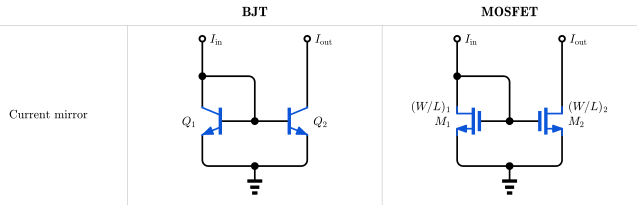

In [4]:
# HIDE/SHOW
show(C.current_mirror)

**Problem 47**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A student builds a simple bipolar current mirror from two nominally identical discrete npn transistors and finds the copy current $30\,\%$ higher than the reference current. Explain why, and what saturation-current ratio this implies. | – |
| **Given** | $I_{copy}=1.3\,I_{REF}$; $\beta$ taken as 100 for the base-current estimate | – |
| **Answer 1** | **Ideal mirror relation.** $I_{copy}=\dfrac{I_{S1}}{I_{S,REF}}I_{REF}$ (equal $V_{BE}$). | – |
| **Answer 2** | **What a 30 % error means.** $I_{S1}/I_{S,REF}=1.3$: the two transistors differ in $I_S$ by 30 %. | – |
| **Answer 3** | **Why discrete parts differ.** Discrete transistors may come from different batches or processes, and random variation changes $I_S$ and the emitter area, so a large mismatch is plausible. Integrated devices on one die match far better. | – |
| **Answer 4** | **Rule out the other errors.** Base currents make the copy lower, not higher, by only $1/(1+2/\beta)$, a 2 % effect at $\beta=100$; neither it nor the Early effect with a similar $V_{CE}$ explains $+30\,\%$. | – |
| **Answer 5** | **Conclusion.** The cause is $I_S$ mismatch; this is why mirrors are rarely used in discrete designs. | – |
| **Result** | $I_S$ mismatch of about $30\,\%$ between the two discrete transistors | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 48**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn mirror on $V_{CC}=2.5\,\mathrm{V}$: $I_{REF}$ flows into diode-connected $Q_{REF}$; $Q_1$ on the same base sinks $I_1=0.5\,\mathrm{mA}$ from a circuit connected to $V_{CC}$. The total power budget (reference plus output branch) is $2\,\mathrm{mW}$. With $V_A=\infty$ and $\beta\gg1$, find $I_{REF}$ and the relative sizes of $Q_{REF}$ and $Q_1$. | – |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $P=2\,\mathrm{mW}$, $I_1=0.5\,\mathrm{mA}$, $V_A=\infty$, $\beta\gg1$ | – |
| **Answer 1** | **Total supply current.** $I_{tot}=\dfrac{2\,\mathrm{mW}}{2.5\,\mathrm{V}}=0.8\,\mathrm{mA}$. | – |
| **Answer 2** | **Reference current.** $I_{REF}=I_{tot}-I_1=0.8-0.5=0.3\,\mathrm{mA}$. | – |
| **Answer 3** | **Area ratio.** $\dfrac{A_{E1}}{A_{E,REF}}=\dfrac{I_1}{I_{REF}}=\dfrac{0.5}{0.3}=\dfrac{5}{3}$, e.g. $Q_{REF}$ of 3 unit transistors and $Q_1$ of 5. | – |
| **Result** | $I_{REF}=0.3\,\mathrm{mA}$; $A_{E1}:A_{E,REF}=5:3$ | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 49**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A BJT current mirror with $Q_1$ diode-connected and $Q_2$ (ratio $m=1$) is fed by $I_{REF}=1\,\mathrm{mA}$. The transistors have $I_S=10^{-15}\,\mathrm{A}$, $\beta=100$ and $V_{A2}=100\,\mathrm{V}$ ($V_T=25\,\mathrm{mV}$). Find $V_{BE}$, the output current $I_O$ at $V_O=5\,\mathrm{V}$ and the output resistance $R_o$. | – |
| **Given** | $I_{REF}=1\,\mathrm{mA}$, $I_S=10^{-15}\,\mathrm{A}$, $\beta=100$, $V_A=100\,\mathrm{V}$, $V_O=5\,\mathrm{V}$, $m=1$, $V_T=25\,\mathrm{mV}$ | – |
| **Answer 1** | **Base-emitter voltage.** $V_{BE}=V_T\ln\dfrac{I_{REF}}{I_S}=0.025\ln\dfrac{10^{-3}}{10^{-15}}=0.691\,\mathrm{V}$. | – |
| **Answer 2** | **Mirror equation.** $I_O=I_{REF}\dfrac{m}{1+(m+1)/\beta}\left(1+\dfrac{V_O-V_{BE}}{V_{A}}\right)$ (finite $\beta$ and Early effect). | – |
| **Answer 3** | **Base-current factor.** $\dfrac{1}{1+2/100}=0.980$. | – |
| **Answer 4** | **Early factor.** $1+\dfrac{5-0.691}{100}=1.043$. | – |
| **Answer 5** | **Output current.** $I_O=1\,\mathrm{mA}\times0.980\times1.043=1.02\,\mathrm{mA}$. | – |
| **Answer 6** | **Output resistance.** $R_o=r_{o2}=\dfrac{V_A}{I_O}=\dfrac{100\,\mathrm{V}}{1.02\,\mathrm{mA}}=97.8\,\mathrm{k\Omega}\approx98\,\mathrm{k\Omega}$. | – |
| **Result** | $V_{BE}=0.691\,\mathrm{V}$, $I_O=1.02\,\mathrm{mA}$, $R_o=97.8\,\mathrm{k\Omega}$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 50**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn current mirror is fed through a resistor $R$ from $V_{CC}=5\,\mathrm{V}$ to the collector of the diode-connected $Q_1$. $Q_1$ and $Q_2$ are matched with $I_S=10^{-15}\,\mathrm{A}$, $\beta=100$, $V_A=50\,\mathrm{V}$; the mirror is to supply $I_O=0.5\,\mathrm{mA}$ at $V_O=2\,\mathrm{V}$. Find $I_{REF}$, $R$, the minimum $V_O$ for which $Q_2$ stays active (take $V_{CEsat}=0.3\,\mathrm{V}$), and $I_O$ when $V_O=5\,\mathrm{V}$ ($V_T=25\,\mathrm{mV}$). | The output current is $I_O=80\,\mathrm{\mu A}$; $V_t=0.5\,\mathrm{V}$, $k_n'=400\,\mathrm{\mu A/V^2}$ and $W/L=10$ for both. Find $V_{OV}$, $R$ and the minimum output voltage $V_{O\,min}$ for $Q_2$ to stay in saturation. |
| **Given** | $V_{CC}=5\,\mathrm{V}$, $I_S=10^{-15}\,\mathrm{A}$, $\beta=100$, $V_A=50\,\mathrm{V}$, $I_O=0.5\,\mathrm{mA}$ at $V_O=2\,\mathrm{V}$, $V_{CEsat}=0.3\,\mathrm{V}$ | $V_{DD}=1.8\,\mathrm{V}$, $I_O=I_{REF}=80\,\mathrm{\mu A}$, $V_t=0.5\,\mathrm{V}$, $k_n'=400\,\mathrm{\mu A/V^2}$, $W/L=10$ |
| **Answer 1** | **Base-emitter voltage.** $V_{BE}=V_T\ln\dfrac{I_O}{I_S}=0.025\ln\dfrac{0.5\times10^{-3}}{10^{-15}}=0.673\,\mathrm{V}$. | **Overdrive.** $I_O=\tfrac12k_n'\dfrac{W}{L}V_{OV}^2\Rightarrow V_{OV}=\sqrt{\dfrac{2\times80}{400\times10}}=0.2\,\mathrm{V}$. |
| **Answer 2** | **Mirror equation.** $I_O=\dfrac{I_{REF}}{1+2/\beta}\left(1+\dfrac{V_O-V_{BE}}{V_A}\right)$. | **Gate-source voltage.** $V_{GS}=V_t+V_{OV}=0.7\,\mathrm{V}$. |
| **Answer 3** | **Reference current.** $I_{REF}=I_O\dfrac{1+2/\beta}{1+(V_O-V_{BE})/V_A}=0.5\,\mathrm{mA}\times\dfrac{1.02}{1.0265}=0.497\,\mathrm{mA}$. | **Reference resistor.** With matched devices $I_{REF}=I_O=80\,\mathrm{\mu A}$ and $I_{REF}=\dfrac{V_{DD}-V_{GS}}{R}$, so $R=\dfrac{1.8-0.7}{0.08\,\mathrm{mA}}=13.75\,\mathrm{k\Omega}$. |
| **Answer 4** | **Resistor.** $R=\dfrac{V_{CC}-V_{BE}}{I_{REF}}=\dfrac{5-0.673}{0.497\,\mathrm{mA}}=8.71\,\mathrm{k\Omega}$. | **Minimum output voltage.** $Q_2$ stays saturated while $V_O\ge V_{GS}-V_t=V_{OV}$, so $V_{O\,min}=0.2\,\mathrm{V}$. |
| **Answer 5** | **Minimum output voltage.** $V_{O\,min}=V_{CE\,sat}=0.3\,\mathrm{V}$. | – |
| **Answer 6** | **Output current at 5 V.** $I_O=\dfrac{0.497\,\mathrm{mA}}{1.02}\left(1+\dfrac{5-0.673}{50}\right)=0.53\,\mathrm{mA}$. | – |
| **Result** | $I_{REF}=0.497\,\mathrm{mA}$, $R=8.71\,\mathrm{k\Omega}$, $V_{O\,min}=0.3\,\mathrm{V}$, $I_O(5\,\mathrm{V})=0.529\,\mathrm{mA}$ | $V_{OV}=0.2\,\mathrm{V}$, $R=13.75\,\mathrm{k\Omega}$, $V_{O\,min}=0.2\,\mathrm{V}$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 51**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A simple npn current mirror with unity ratio ($m=1$) has $I_{REF}=100\,\mu\mathrm{A}$. Transistor data: $\beta=100$, $V_{A}=35\,\mathrm{V}$, $I_S=6\times10^{-18}\,\mathrm{A}$, $V_T=25\,\mathrm{mV}$. Find the output current $I_O$ when $V_O=2\,\mathrm{V}$, the output resistance $R_o$, and the change in $I_O$ when $V_O$ is lowered by $1\,\mathrm{V}$. | $(W/L)_2/(W/L)_1=4$ with the same $L=0.54\,\mu\mathrm{m}$. Data: $\mu_nC_{ox}=387\,\mu\mathrm{A/V^2}$, $V_t=0.5\,\mathrm{V}$, $V_A'=5\,\mathrm{V}/\mu\mathrm{m}$. Find $V_{OV}$, the nominal $I_O$, the minimum $V_O$, $R_o$, and $I_O$ for $V_O=0.2,\,0.7,\,1.2,\,1.7\,\mathrm{V}$. |
| **Given** | $I_{REF}=100\,\mu\mathrm{A}$, $m=1$, $\beta=100$, $V_{A}=35\,\mathrm{V}$, $I_S=6\times10^{-18}\,\mathrm{A}$, $V_O=2\,\mathrm{V}$ | $I_{REF}=25\,\mu\mathrm{A}$, $(W/L)_1=1.74/0.54$, ratio $4$, $\mu_nC_{ox}=387\,\mu\mathrm{A/V^2}$, $V_t=0.5\,\mathrm{V}$, $V_A'=5\,\mathrm{V}/\mu\mathrm{m}$, $L=0.54\,\mu\mathrm{m}$ |
| **Answer 1** | **Base-emitter voltage.** $V_{BE}=V_T\ln\dfrac{I_{REF}}{I_S}=0.025\ln\dfrac{100\times10^{-6}}{6\times10^{-18}}=0.761\,\mathrm{V}$. | **Overdrive.** $25=\tfrac12\times387\times\dfrac{1.74}{0.54}V_{OV}^2\Rightarrow V_{OV}=0.2\,\mathrm{V}$, so $V_{GS}=0.7\,\mathrm{V}$. |
| **Answer 2** | **Mirror equation.** $I_O=I_{REF}\,\dfrac{m}{1+(m+1)/\beta}\left(1+\dfrac{V_O-V_{BE}}{V_A}\right)$ with $m=1$. | **Nominal output current.** $I_{O,\mathrm{nom}}=4\times25=100\,\mu\mathrm{A}$ (at $V_O=V_{GS}$). |
| **Answer 3** | **Output current at 2 V.** $I_O=100\times\dfrac{1}{1+2/100}\left(1+\dfrac{2-0.761}{35}\right)=98.04\times1.0354=101.5\,\mu\mathrm{A}$. | **Minimum output voltage.** $V_{O,\min}=V_{OV}=0.2\,\mathrm{V}$. |
| **Answer 4** | **Output resistance.** $R_o=r_{o2}=\dfrac{V_A}{I_{O,\mathrm{nominal}}}=\dfrac{35\,\mathrm{V}}{0.1\,\mathrm{mA}}=350\,\mathrm{k}\Omega$ (with the actual $I_C\approx101.5\,\mu\mathrm{A}$ it would be $345\,\mathrm{k}\Omega$). | **Output resistance.** $V_{A2}=5\times0.54=2.7\,\mathrm{V}$; $R_o=r_{o2}=\dfrac{2.7}{0.1\,\mathrm{mA}}=27\,\mathrm{k}\Omega$. |
| **Answer 5** | **Change for $V_O$ lowered by 1 V.** $\Delta I_O=\dfrac{\Delta V_O}{R_o}=\dfrac{1\,\mathrm{V}}{350\,\mathrm{k}\Omega}\approx2.9\,\mu\mathrm{A}$ (the mirror equation gives $I_O\approx98.7\,\mu\mathrm{A}$ at $V_O=1\,\mathrm{V}$, a drop of $2.8\,\mu\mathrm{A}$). | **Output current vs $V_O$.** $I_O=100\left(1+\dfrac{V_O-0.7}{2.7}\right)\,\mu\mathrm{A}$. |
| **Answer 6** | – | **Values.** $V_O=0.2\,\mathrm{V}$: $81.5\,\mu\mathrm{A}$; $0.7\,\mathrm{V}$: $100\,\mu\mathrm{A}$; $1.2\,\mathrm{V}$: $118.5\,\mu\mathrm{A}$; $1.7\,\mathrm{V}$: $137\,\mu\mathrm{A}$. |
| **Result** | $I_O=101.5\,\mu\mathrm{A}$; $R_o=350\,\mathrm{k}\Omega$; $\Delta I_O\approx-2.9\,\mu\mathrm{A}$ for $\Delta V_O=-1\,\mathrm{V}$ | $V_{OV}=0.2\,\mathrm{V}$, $I_{O,\mathrm{nom}}=100\,\mu\mathrm{A}$, $R_o=27\,\mathrm{k}\Omega$; $I_O=81.5,\,100,\,118.5,\,137\,\mu\mathrm{A}$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 52**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A bipolar current mirror has $I_{REF}=1\,\mathrm{mA}$ and the output transistor has Early voltage $V_{A2}=90\,\mathrm{V}$. The output voltage varies from $1\,\mathrm{V}$ to $10\,\mathrm{V}$. Find the output resistance and the resulting change in $I_O$ as a percentage of the nominal value. | Redesign the mirror so that a $1\,\mathrm{V}$ change in the output voltage $V_O$ changes $I_O$ by only $1\%$ of $I_O$, keeping the same overdrive voltage. Find $L$ and $W$ of the two transistors. |
| **Given** | $I_{REF}=1\,\mathrm{mA}$, $V_{A2}=90\,\mathrm{V}$, $V_O$: $1\,\mathrm{V}\to10\,\mathrm{V}$ | $I_O=100\,\mathrm{\mu A}$, $\Delta V_O=1\,\mathrm{V}$, $\Delta I_O=0.01I_O$, $V_A'=20\,\mathrm{V/\mu m}$, original $W/L=10$ |
| **Answer 1** | **Nominal current.** $I_O=I_{REF}=1\,\mathrm{mA}$ (ideal ratio). | **Allowed current change.** $\Delta I_O=0.01\times100\,\mathrm{\mu A}=1\,\mathrm{\mu A}$. |
| **Answer 2** | **Output resistance.** $r_{o2}=\dfrac{V_{A2}}{I_O}=\dfrac{90\,\mathrm{V}}{1\,\mathrm{mA}}=90\,\mathrm{k}\Omega$. | **Required output resistance.** $\Delta I_O=\dfrac{\Delta V_O}{r_{o2}}\Rightarrow r_{o2}=\dfrac{1\,\mathrm{V}}{1\,\mathrm{\mu A}}=1\,\mathrm{M\Omega}$. |
| **Answer 3** | **Current change.** $\Delta I_O=\dfrac{\Delta V_O}{r_{o2}}=\dfrac{10-1}{90\,\mathrm{k}\Omega}=0.1\,\mathrm{mA}$. | **Channel length.** $r_{o2}=\dfrac{V_A'L}{I_O}\Rightarrow L=\dfrac{r_{o2}I_O}{V_A'}=\dfrac{100\,\mathrm{V}}{20\,\mathrm{V/\mu m}}=5\,\mathrm{\mu m}$. |
| **Answer 4** | **Percentage.** $\dfrac{\Delta I_O}{I_O}=\dfrac{0.1}{1}=10\,\%$. | **Keep the overdrive.** $V_{OV}$ is fixed by $I_O$ and $W/L$ only, so $W/L$ must stay $10$. |
| **Answer 5** | – | **Width.** $W=10\times L=10\times5\,\mathrm{\mu m}=50\,\mathrm{\mu m}$. |
| **Result** | $R_o=90\,\mathrm{k}\Omega$; $\Delta I_O=0.1\,\mathrm{mA}$, i.e. $10\,\%$ | $r_{o2}=1\,\mathrm{M\Omega}$, $L=5\,\mathrm{\mu m}$, $W=50\,\mathrm{\mu m}$ for both $Q_1$ and $Q_2$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 53**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn current mirror with matched transistors, $I_S=10^{-17}\,\mathrm{A}$ and $V_T=25\,\mathrm{mV}$, must work for reference currents from $10\,\mu\mathrm{A}$ to $10\,\mathrm{mA}$. (a) Neglecting base currents, find the range of $V_{BE}$. (b) With finite $\beta$ ($\beta=50$ at $10\,\mu\mathrm{A}$ and $10\,\mathrm{mA}$, $\beta=100$ at $0.1\,\mathrm{mA}$ and $1\,\mathrm{mA}$) find $I_O$ for $I_{REF}=10\,\mu\mathrm{A}$, $0.1$, $1$, $10\,\mathrm{mA}$. | The output voltage may range from $V_{OV}=0.3\,\mathrm{V}$ up to $V_{DD}$, and $I_O$ must change by no more than $10\,\%$ over that range. With $\mu_nC_{ox}=400\,\mu\mathrm{A/V^2}$, $V_t=0.5\,\mathrm{V}$ and $V_A'=10\,\mathrm{V}/\mu\mathrm{m}$, find $L$, $W$ and $R$. |
| **Given** | $I_S=10^{-17}\,\mathrm{A}$, $V_T=25\,\mathrm{mV}$, $I_{REF}=10\,\mu\mathrm{A}\ldots10\,\mathrm{mA}$, $\beta=50$ or $100$ as stated | $I_{REF}=150\,\mu\mathrm{A}$, $V_{DD}=1.8\,\mathrm{V}$, $V_{OV}=0.3\,\mathrm{V}$, $\mu_nC_{ox}=400\,\mu\mathrm{A/V^2}$, $V_t=0.5\,\mathrm{V}$, $V_A'=10\,\mathrm{V}/\mu\mathrm{m}$, $\Delta I_O/I_O=10\,\%$ |
| **Answer 1** | **(a) $V_{BE}$ at the low end.** $V_{BE}=V_T\ln\dfrac{I_{REF}}{I_S}=0.025\ln\dfrac{10^{-5}}{10^{-17}}=0.691\,\mathrm{V}$. | **Allowed current change.** $\Delta I_O=0.1\times150=15\,\mu\mathrm{A}$ over $\Delta V_O=1.8-0.3=1.5\,\mathrm{V}$. |
| **Answer 2** | **(a) $V_{BE}$ at the high end.** $V_{BE}=0.025\ln\dfrac{10^{-2}}{10^{-17}}=0.863\,\mathrm{V}$; so $0.691\,\mathrm{V}\le V_{BE}\le0.863\,\mathrm{V}$ while $10\,\mu\mathrm{A}\le I_O\le10\,\mathrm{mA}$. | **Required output resistance.** $r_o=\dfrac{\Delta V_O}{\Delta I_O}=\dfrac{1.5\,\mathrm{V}}{15\,\mu\mathrm{A}}=100\,\mathrm{k}\Omega$. |
| **Answer 3** | **(b) Finite-$\beta$ ratio.** $I_O=\dfrac{I_{REF}}{1+2/\beta}$. | **Channel length.** $r_o=\dfrac{V_A'L}{I_O}$ with $I_O=0.15\,\mathrm{mA}$: $100=\dfrac{10L}{0.15}\Rightarrow L=1.5\,\mu\mathrm{m}$, so $V_A=15\,\mathrm{V}$. |
| **Answer 4** | **(b) $10\,\mu\mathrm{A}$ and $10\,\mathrm{mA}$.** $\beta=50$: $I_O=\dfrac{10\,\mu\mathrm{A}}{1.04}=9.62\,\mu\mathrm{A}$ and $\dfrac{10\,\mathrm{mA}}{1.04}=9.62\,\mathrm{mA}$. | **Gate-source voltage.** $V_{GS}=V_t+V_{OV}=0.8\,\mathrm{V}$; the diode-connected $Q_1$ has $V_{DS}=V_{GS}=0.8\,\mathrm{V}$. |
| **Answer 5** | **(b) $0.1\,\mathrm{mA}$ and $1\,\mathrm{mA}$.** $\beta=100$: $I_O=\dfrac{0.1}{1.02}=0.098\,\mathrm{mA}$ and $\dfrac{1}{1.02}=0.980\,\mathrm{mA}$. | **Width of $Q_1$.** $I_{REF}=\tfrac12\mu_nC_{ox}\dfrac{W}{L}V_{OV}^2\left(1+\dfrac{V_{DS}}{V_A}\right)$: $150=\tfrac12\times400\times\dfrac WL\times0.09\times\left(1+\dfrac{0.8}{15}\right)\Rightarrow\dfrac WL=7.91$, so $W=7.91\times1.5=11.9\,\mu\mathrm{m}$. |
| **Answer 6** | – | **Resistor.** $R=\dfrac{V_{DD}-V_{GS}}{I_{REF}}=\dfrac{1.8-0.8}{0.15\,\mathrm{mA}}=6.7\,\mathrm{k}\Omega$. |
| **Result** | (a) $0.691\,\mathrm{V}\le V_{BE}\le0.863\,\mathrm{V}$; (b) $I_O=9.62\,\mu\mathrm{A},\,0.098,\,0.98,\,9.62\,\mathrm{mA}$ | $L=1.5\,\mu\mathrm{m}$, $W=11.9\,\mu\mathrm{m}$ ($W/L=7.91$), $R=6.7\,\mathrm{k}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 54**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | In a bipolar current mirror the output transistor $Q_2$ has an emitter area $m$ times that of the reference transistor $Q_1$. Neglecting the Early effect, show that $I_O/I_{REF}=m/\bigl(1+(m+1)/\beta\bigr)$. Then find the largest $m$ for which the transfer ratio is at least $90\,\%$ of the ideal value $m$ when $\beta=80$. | – |
| **Given** | $I_O=mI_{C1}$, $\beta=80$, tolerance $10\,\%$ | – |
| **Answer 1** | **Collector currents.** Same $V_{BE}$, so $I_O=I_{C2}=mI_{C1}$, i.e. $I_{C1}=I_O/m$. | – |
| **Answer 2** | **Base currents.** $I_{B1}+I_{B2}=\dfrac{I_{C1}+I_O}{\beta}$. | – |
| **Answer 3** | **Node equation at the collector of $Q_1$.** $I_{REF}=I_{C1}+\dfrac{I_O+I_{C1}}{\beta}=\dfrac{I_O}{m}+\dfrac{I_O}{\beta}\left(1+\dfrac1m\right)=\dfrac{I_O}{m}\left(1+\dfrac{m+1}{\beta}\right)$. | – |
| **Answer 4** | **Transfer ratio.** $\dfrac{I_O}{I_{REF}}=\dfrac{m}{1+(m+1)/\beta}$. | – |
| **Answer 5** | **10 % condition.** $\dfrac{m}{1+(m+1)/\beta}\ge0.9m\Rightarrow1+\dfrac{m+1}{\beta}\le\dfrac1{0.9}\Rightarrow\dfrac{m+1}{\beta}\le\dfrac1{0.9}-1=0.1111$. | – |
| **Answer 6** | – | – |
| **Result** | $\dfrac{I_O}{I_{REF}}=\dfrac{m}{1+(m+1)/\beta}$; $m_{\max}=7.89\approx7.9$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 55**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A bipolar mirror used as a current amplifier has a reference transistor $Q_1$ (diode-connected, carrying the input current) and an output transistor $Q_2$ with emitter area $m$ times larger. Using the hybrid-$\pi$ model with finite $\beta$ and the Early effect, derive $R_{in}$, the short-circuit current gain $A_{is}=i_o/i_i$ and $R_o$. Evaluate for $I=0.1\,\mathrm{mA}$ (input bias in $Q_1$), $m=5$, $\beta=100$, $V_A=30\,\mathrm{V}$. | An NMOS mirror is used as a current amplifier. $Q_1$ (diode-connected) has $W/L=10/0.5$ and carries $I_{D1}=0.1\,\mathrm{mA}$; $Q_2$ has $W/L=50/0.5$. Technology: $\mu_nC_{ox}=0.5\,\mathrm{mA/V^2}$, $V_A'=10\,\mathrm{V}/\mu\mathrm{m}$. Find the input resistance $R_{in}$, the current gain $A_{is}$ and the output resistance $R_o$. |
| **Given** | $m=5$, $I=0.1\,\mathrm{mA}$, $\beta=100$, $V_A=30\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ | $(W/L)_1=10/0.5$, $(W/L)_2=50/0.5$, $I_{D1}=0.1\,\mathrm{mA}$, $\mu_nC_{ox}=0.5\,\mathrm{mA/V^2}$, $V_A'=10\,\mathrm{V}/\mu\mathrm{m}$ |
| **Answer 1** | **Model of $Q_1$.** $g_{m1}v_{\pi1}$ lies across its own control voltage, so it equals a resistance $1/g_{m1}$. | **Transconductance of $Q_1$.** $g_{m1}=\sqrt{2\mu_nC_{ox}(W/L)_1I_{D1}}=\sqrt{2\times0.5\times20\times0.1}=1.414\,\mathrm{mA/V}$, so $1/g_{m1}=0.707\,\mathrm{k}\Omega$. |
| **Answer 2** | **Input resistance.** $R_{in}=r_{o1}\parallel\dfrac1{g_{m1}}\parallel r_{\pi1}\parallel r_{\pi2}\simeq\dfrac1{g_{m1}}\parallel r_{\pi1}\parallel r_{\pi2}$ (since $r_{o1}\gg r_{\pi1}$). | **Output resistance of $Q_1$.** $r_{o1}=\dfrac{V_A'L}{I_{D1}}=\dfrac{10\times0.5}{0.1\,\mathrm{mA}}=50\,\mathrm{k}\Omega$. |
| **Answer 3** | **Scaling.** $r_{\pi1}=\beta/g_{m1}$ and, since $I_{C2}=mI_{C1}$, $g_{m2}=mg_{m1}$, $r_{\pi2}=\dfrac{\beta}{mg_{m1}}$. | **Input resistance.** $R_{in}=r_{o1}\parallel\dfrac{1}{g_{m1}}=50\parallel0.707=0.697\,\mathrm{k}\Omega\approx700\,\Omega$. |
| **Answer 4** | **Combine.** $R_{in}=\dfrac1{g_{m1}\left(1+\dfrac{m+1}\beta\right)}$. | **Current gain.** $A_{is}=\dfrac{(W/L)_2}{(W/L)_1}=\dfrac{50/0.5}{10/0.5}=5$. |
| **Answer 5** | **Current gain.** Short-circuit $i_o=g_{m2}v_{\pi2}$ with $v_{\pi2}=v_{\pi1}=i_iR_{in}$: $A_{is}=g_{m2}R_{in}=\dfrac{m}{1+(m+1)/\beta}$. | **Output resistance.** $I_{D2}=5\times0.1=0.5\,\mathrm{mA}$; $R_o=r_{o2}=\dfrac{10\times0.5}{0.5\,\mathrm{mA}}=10\,\mathrm{k}\Omega$. |
| **Answer 6** | **Output resistance.** By inspection $R_o=r_{o2}=\dfrac{V_A}{mI}$. | – |
| **Answer 7** | **Numbers.** $g_{m1}=\dfrac{0.1}{0.025}=4\,\mathrm{mA/V}$; $R_{in}=\dfrac1{4\times1.06}=0.236\,\mathrm{k}\Omega$; $A_{is}=\dfrac5{1.06}=4.72$; $R_o=\dfrac{30}{5\times0.1}=60\,\mathrm{k}\Omega$. | – |
| **Result** | $R_{in}=\dfrac1{g_{m1}(1+(m+1)/\beta)}$, $A_{is}=\dfrac{m}{1+(m+1)/\beta}$, $R_o=\dfrac{V_A}{mI}$; $0.236\,\mathrm{k}\Omega$, $4.72$, $60\,\mathrm{k}\Omega$ | $R_{in}\approx700\,\Omega$, $A_{is}=5\,\mathrm{A/A}$, $R_o=10\,\mathrm{k}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 56**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | In the basic NMOS mirror (diode-connected $M_{REF}$ carrying $I_{REF}$, output $M_1$ on the same gate carrying $I_{copy}$), the two transistors are identical but $\lambda\neq0$. (a) What $V_{DS}$ of $M_1$ makes $I_{copy}$ exactly equal to $I_{REF}$? (b) Find the error in $I_{copy}$ if $V_{DS1}=V_{GS}-V_{TH}$ (edge of saturation). |
| **Given** | – | identical transistors, $\lambda\neq0$, $V_{DS,REF}=V_{GS}$ |
| **Answer 1** | – | **Square law with $\lambda$.** $I_D=\tfrac12\mu_nC_{ox}\dfrac{W}{L}(V_{GS}-V_{TH})^2(1+\lambda V_{DS})$; both have the same $V_{GS}$. |
| **Answer 2** | – | **Ratio of currents.** $\dfrac{I_{copy}}{I_{REF}}=\dfrac{1+\lambda V_{DS1}}{1+\lambda V_{GS}}$ since the diode-connected device has $V_{DS}=V_{GS}$. |
| **Answer 3** | – | **(a) Exact copy.** $I_{copy}=I_{REF}$ requires $V_{DS1}=V_{GS}$, the same drain-source voltage as $M_{REF}$. |
| **Answer 4** | – | **(b) Edge of saturation.** $\dfrac{I_{copy}}{I_{REF}}=\dfrac{1+\lambda(V_{GS}-V_{TH})}{1+\lambda V_{GS}}=1-\dfrac{\lambda V_{TH}}{1+\lambda V_{GS}}$. |
| **Answer 5** | – | **(b) Size of the error.** Error $=-\dfrac{\lambda V_{TH}}{1+\lambda V_{GS}}\approx-\lambda V_{TH}$; e.g. $\lambda=0.1\,\mathrm{V^{-1}}$, $V_{TH}=0.4\,\mathrm{V}$, $V_{GS}=0.8\,\mathrm{V}$ gives $I_{copy}=0.963I_{REF}$, $-3.70\,\%$. |
| **Result** | – | (a) $V_{DS1}=V_{GS}$; (b) $\dfrac{I_{copy}-I_{REF}}{I_{REF}}=-\dfrac{\lambda V_{TH}}{1+\lambda V_{GS}}$ |
| **Check** | – | Solved twice, with the same result; no answer is published. |

**Problem 57**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | An NMOS mirror is to be used as a current amplifier with nominal gain $4$, input resistance $R_{in}=500\,\Omega$ and output resistance $R_o=20\,\mathrm{k}\Omega$, with $I_{D1}=0.2\,\mathrm{mA}$, $\mu_nC_{ox}=0.4\,\mathrm{mA/V^2}$ and $V_A'=20\,\mathrm{V}/\mu\mathrm{m}$ (same $L$ for both transistors). Find $W/L$ of $Q_1$, the length $L$, $W_1$ and $W_2$, and the actual current gain that results. |
| **Given** | – | $A_{is}=4$, $R_{in}=500\,\Omega$, $R_o=20\,\mathrm{k}\Omega$, $I_{D1}=0.2\,\mathrm{mA}$, $\mu_nC_{ox}=0.4\,\mathrm{mA/V^2}$, $V_A'=20\,\mathrm{V}/\mu\mathrm{m}$ |
| **Answer 1** | – | **Width ratio.** $A_{is}=\dfrac{(W/L)_2}{(W/L)_1}=4$ with equal $L$, so $W_2=4W_1$. |
| **Answer 2** | – | **Transconductance.** $R_{in}=r_{o1}\parallel\dfrac1{g_{m1}}\approx\dfrac1{g_{m1}}=500\,\Omega\Rightarrow g_{m1}=2\,\mathrm{mA/V}$. |
| **Answer 3** | – | **$W/L$ of $Q_1$.** $g_{m1}=\sqrt{2\mu_nC_{ox}(W/L)_1I_{D1}}$: $2=\sqrt{2\times0.4\times(W/L)_1\times0.2}\Rightarrow(W/L)_1=25$. |
| **Answer 4** | – | **Length.** $I_{D2}=4\times0.2=0.8\,\mathrm{mA}$ and $R_o=r_{o2}=\dfrac{V_A'L}{I_{D2}}$: $20=\dfrac{20L}{0.8}\Rightarrow L=0.8\,\mu\mathrm{m}$. |
| **Answer 5** | – | **Widths.** $W_1=25\times0.8=20\,\mu\mathrm{m}$, $W_2=4W_1=80\,\mu\mathrm{m}$. |
| **Answer 6** | – | **Actual gain.** $r_{o1}=\dfrac{20\times0.8}{0.2}=80\,\mathrm{k}\Omega$; $A_{is}=\dfrac{(W/L)_2}{(W/L)_1}\,\dfrac1{1+1/(g_{m1}r_{o1})}=\dfrac{4}{1+\dfrac1{2\times80}}=3.975$, an error of $-0.6\,\%$. |
| **Result** | – | $(W/L)_1=25$, $L=0.8\,\mu\mathrm{m}$, $W_1=20\,\mu\mathrm{m}$, $W_2=80\,\mu\mathrm{m}$, $A_{is}=3.975\,\mathrm{A/A}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

### Other Circuits

**Problem 58**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A student draws an npn current mirror (reference QREF fed by a current source IREF at its collector, copy transistor Q1, emitters grounded, bases joined) but forgets to connect the base of QREF to its collector, so the joined bases connect to nothing else. Explain what happens to the copy current. | A student copies the idea of the bipolar mirror into NMOS, reasoning that gates draw no current, and leaves the gates of MREF and M1 joined but unconnected to anything (MREF has no diode connection). The reference current source feeds the drain of MREF. Explain what happens. |
| **Given** | npn pair with emitters grounded, common base node floating, $I_{REF}$ into the collector of QREF | NMOS pair, sources grounded, gates joined and floating, $I_{REF}$ into the drain of MREF |
| **Answer 1** | **Look for a path for base current.** A bipolar transistor in the active region needs a base current $I_B=I_C/\beta$. The base node here is connected only to the bases of QREF and Q1; nothing supplies current to it. | – |
| **Answer 2** | **Define the base-emitter voltage.** No source or diode defines $V_{BE}$: the node voltage is undetermined (it floats). | **Floating gate.** With the gates floating, the gate voltage is whatever charge was left at the node, e.g. an initial condition at power-up; it is not tied to $I_{REF}$. |
| **Answer 3** | **Kirchhoff at the base node.** In the ideal active-mode model the only currents into this node are base currents, so $I_{B,REF}+I_{B1}=0$. Both are non-negative in active mode, so each is zero. | **Consequence for the copy.** $I_{copy}=\tfrac12\mu_nC_{ox}(W/L)_1(V_X-V_{TH})^2$ depends on the arbitrary $V_X$. Illustration ($W/L=10$, $V_{TH}=0.5\,\mathrm{V}$): $V_X=0.6,\,0.8,\,1.0\,\mathrm{V}$ gives $5,\,45,\,125\,\mu\mathrm{A}$. |
| **Answer 4** | **Collector current of the copy.** $I_{copy}=\beta I_{B1}=0$. | **Conclusion.** The circuit is not a current mirror: $I_{copy}$ is poorly defined and not related to $I_{REF}$. |
| **Answer 5** | The cure is to tie the base of QREF to its collector. | – |
| **Result** | $I_{copy}=0$ (no base-current path and no defined $V_{BE}$) | $I_{copy}$ is poorly defined (depends on the arbitrary floating-gate voltage); a diode-connected MREF is needed |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 59**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | QREF still has its base separate from its collector, and IREF feeds the QREF collector. Explain why this is still not a proper current mirror. | – |
| **Given** | npn pair, emitters grounded, bases tied to a battery $V_X$, $I_{REF}$ into the collector of QREF | – |
| **Answer 1** | **What the battery does.** It supplies the base currents and defines $V_{BE}=V_X$ of both transistors. | – |
| **Answer 2** | **Copy current.** $I_{copy}=I_{S1}\exp(V_X/V_T)$: it is set by $V_X$ and by the device parameters, not by $I_{REF}$. | – |
| **Answer 3** | **What is missing.** A diode-connected QREF makes $V_X=V_T\ln(I_{REF}/I_{S,REF})$, which tracks $I_S$ and $V_T$ with temperature. A fixed battery cannot do that. | – |
| **Answer 4** | $I_{REF}$ plays no role. | – |
| **Answer 5** | **.** $V_{BE}$ of a silicon BJT falls about $2\,\mathrm{mV}/{}^\circ\mathrm{C}$ at constant current, so at constant $V_X$ the current grows by about $e^{0.002/0.026}\approx1.08$ per ${}^\circ\mathrm{C}$, roughly a factor 2 for 9 ${}^\circ\mathrm{C}$. | – |
| **Result** | $I_{copy}=I_{S1}e^{V_X/V_T}$ is not tied to $I_{REF}$ and drifts strongly with temperature; a diode-connected QREF is required | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 60**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Design bipolar current sources of $0.75\,\mathrm{mA}$ and $0.5\,\mathrm{mA}$ from a $0.25\,\mathrm{mA}$ reference current, using identical unit transistors; neglect base currents. | – |
| **Given** | $I_{REF}=0.25\,\mathrm{mA}$, targets $0.75\,\mathrm{mA}$ and $0.5\,\mathrm{mA}$, identical unit transistors | – |
| **Answer 1** | **Principle.** All bases are tied to the base-emitter voltage of the diode-connected QREF, so $I_{copy,j}=\dfrac{I_{S,j}}{I_{S,REF}}I_{REF}=n_jI_{REF}$, where $n_j$ is the number of unit transistors in parallel relative to QREF. | – |
| **Answer 2** | **Required ratios.** $n_1=0.75/0.25=3$ and $n_2=0.5/0.25=2$. | – |
| **Answer 3** | **Design.** QREF: one unit transistor (diode-connected). Source 1: three unit transistors in parallel. Source 2: two unit transistors in parallel. Six unit devices in all, with joined bases and grounded emitters. | – |
| **Answer 4** | **Check.** $I_1=3\times0.25=0.75\,\mathrm{mA}$ and $I_2=2\times0.25=0.5\,\mathrm{mA}$; $I_{REF}$ itself flows through QREF. | – |
| **Result** | QREF = 1 unit; 3 units for the 0.75 mA source; 2 units for the 0.5 mA source | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 61**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Using identical unit transistors, design a bipolar current mirror that produces $50\,\mu\mathrm{A}$ and $500\,\mu\mathrm{A}$ from a $200\,\mu\mathrm{A}$ reference. Neglect base currents. | – |
| **Given** | $I_{REF}=200\,\mu\mathrm{A}$, outputs $50\,\mu\mathrm{A}$ and $500\,\mu\mathrm{A}$ | – |
| **Answer 1** | **Why the reference must be larger.** $50\,\mu\mathrm{A}$ is a fraction of $I_{REF}$, so QREF must itself consist of several units: $I_{copy}=\dfrac{I_{S,copy}}{I_{S,REF}}I_{REF}$. | – |
| **Answer 2** | **Fix the unit current.** Choose the unit current as the smallest output, $50\,\mu\mathrm{A}$. Then QREF needs $200/50=4$ units so that each carries $50\,\mu\mathrm{A}$. | – |
| **Answer 3** | **Second output.** $500\,\mu\mathrm{A}/50\,\mu\mathrm{A}=10$ unit transistors in parallel. | – |
| **Answer 4** | **Design.** QREF: $4A_E$ (diode-connected); copy 1: $1A_E$ giving $50\,\mu\mathrm{A}$; copy 2: $10A_E$ giving $500\,\mu\mathrm{A}$. | – |
| **Answer 5** | **Check.** $I_1=\dfrac14\times200=50\,\mu\mathrm{A}$, $I_2=\dfrac{10}{4}\times200=500\,\mu\mathrm{A}$. | – |
| **Result** | QREF $=4$ units, copy 1 $=1$ unit ($50\,\mu\mathrm{A}$), copy 2 $=10$ units ($500\,\mu\mathrm{A}$) | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 62**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | – |
| **Given** | $I_{REF}=200\,\mu\mathrm{A}$, nominal copies $50\,\mu\mathrm{A}$ and $500\,\mu\mathrm{A}$, current gain $\beta$ (symbolic; numerical illustration $\beta=100$) | – |
| **Answer 1** | **Currents scale with area.** Let a unit transistor carry $I$. Then $I_{C,REF}=4I$, $I_{copy1}=I$, $I_{copy2}=10I$ (equal $V_{BE}$). | – |
| **Answer 2** | **Base currents.** The three bases draw $(4+1+10)I/\beta=15I/\beta$ in total, taken from node X. | – |
| **Answer 3** | **Plain mirror, KCL.** $I_{REF}=4I+\dfrac{15I}{\beta}$, so $I=\dfrac{I_{REF}}{4+15/\beta}$: $I_{copy1}=\dfrac{I_{REF}}{4+15/\beta}$, $I_{copy2}=\dfrac{10\,I_{REF}}{4+15/\beta}$. | – |
| **Answer 4** | **Plain mirror, error.** Relative to the ideal $I_{REF}/4$ and $10I_{REF}/4$, both copies are low by $\dfrac{15/\beta}{4+15/\beta}\approx\dfrac{3.75}{\beta}$; with $\beta=100$ the error is $3.61\,\%$ ($48.2\,\mu\mathrm{A}$ and $482\,\mu\mathrm{A}$). | – |
| **Answer 5** | **With the follower.** The follower supplies the base currents: its emitter current is $15I/\beta$, so its own base current is $15I/\beta^2$ and it comes out of $I_{REF}$ at the collector of QREF. KCL at P: $I_{REF}=4I+\dfrac{15I}{\beta^2}$. | – |
| **Answer 6** | **Follower result.** $I_{copy1}=\dfrac{I_{REF}}{4+15/\beta^2}$, $I_{copy2}=\dfrac{10\,I_{REF}}{4+15/\beta^2}$; the error is $\dfrac{15/\beta^2}{4+15/\beta^2}\approx\dfrac{3.75}{\beta^2}$, which for $\beta=100$ is $0.0375\,\%$ ($49.98\,\mu\mathrm{A}$ and $499.8\,\mu\mathrm{A}$). | – |
| **Answer 7** | **Conclusion.** The follower divides the error by $\beta$. | – |
| **Result** | Plain mirror: error $\approx15/(4\beta)$ (3.61 % at $\beta=100$); with follower: $\approx15/(4\beta^2)$ (0.0375 %) | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 63**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Explain what the circuit does. | A diode-connected NMOS $Q_1$ has its gate and drain tied together and joined through a resistor $R$ to $V_{DD}=1.8\,\mathrm{V}$; its source is grounded. $Q_1$ has $W_1/L_1=1.44/0.36$, $k_n^\prime=0.4\,\mathrm{mA/V^2}$, $V_t=0.5\,\mathrm{V}$ and carries $I_{D1}=50\,\mu\mathrm{A}$. A second NMOS $Q_2$ has its gate connected to the gate of $Q_1$, its source grounded and a resistor $R_2$ from its drain to $V_{DD}$. Find $R$; then find $W_2$ (with $L_2=0.36\,\mu\mathrm{m}$) and $R_2$ so that $Q_2$ carries $10I_{D1}$ and operates at the edge of saturation. |
| **Given** | $I_{REF}=V_{REF}/R_1$, saturation currents $I_{S1}$, $I_{S2}$ | $V_{DD}=1.8\,\mathrm{V}$, $W_1/L_1=1.44/0.36$, $k_n^\prime=0.4\,\mathrm{mA/V^2}$, $V_t=0.5\,\mathrm{V}$, $I_{D1}=50\,\mu\mathrm{A}$, $L_2=0.36\,\mu\mathrm{m}$ |
| **Answer 1** | **Log amplifier.** As before, $I_{REF}=V_{REF}/R_1$ flows into the collector of $Q_1$ and $V_1=-V_T\ln(I_{REF}/I_{S1})$. | **(a) Overdrive of Q1.** $0.05=\tfrac12(0.4)\dfrac{1.44}{0.36}V_{OV}^2=0.8\,V_{OV}^2$, so $V_{OV}=0.25\,\mathrm{V}$. |
| **Answer 2** | **Equal base-emitter voltages.** Both bases are grounded and both emitters are at $V_1$: $V_{BE2}=V_{BE1}=-V_1$. | **(a) Gate voltage.** $V_{GS1}=V_t+V_{OV}=0.75\,\mathrm{V}$ and $V_{D1}=V_{GS1}=0.75\,\mathrm{V}$. |
| **Answer 3** | **Output current.** $I_X=I_{S2}\exp\dfrac{V_{BE1}}{V_T}=\dfrac{I_{S2}}{I_{S1}}I_{REF}=\dfrac{I_{S2}}{I_{S1}}\cdot\dfrac{V_{REF}}{R_1}$ | **(a) Resistor R.** $R=\dfrac{V_{DD}-V_{D1}}{I_{D1}}=\dfrac{1.8-0.75}{0.05\,\mathrm{mA}}=21\,\mathrm{k}\Omega$. |
| **Answer 4** | **What happens.** The circuit is a current mirror: $I_X$ is a scaled copy of $V_{REF}/R_1$, independent of temperature and $I_S$ as long as the two transistors match. The base currents come from ground and the emitter currents are absorbed by the op-amp output, so the collector of $Q_1$ carries exactly $V_{REF}/R_1$ (no base-current error in the reference). The op amp must be able to sink both emitter currents at a negative output, so it needs a negative supply. | **(b) Same overdrive, ten times the current.** $Q_2$ has the same $V_{GS}$, hence $V_{OV}=0.25\,\mathrm{V}$, and $I_{D2}=0.5\,\mathrm{mA}$. |
| **Answer 5** | **Numerical check.** With $I_{S1}=I_{S2}=6\times10^{-17}\,\mathrm{A}$ and $V_{REF}/R_1=0.1\,\mathrm{mA}$: $V_1=-0.732\,\mathrm{V}$ and $I_X=0.100\,\mathrm{mA}$. | **(b) Width of Q2.** $0.5=\tfrac12(0.4)\dfrac{W_2}{0.36}(0.25)^2\Rightarrow W_2=14.4\,\mu\mathrm{m}$, ten times $W_1=1.44\,\mu\mathrm{m}$, as expected for ten times the current at equal $V_{GS}$. |
| **Answer 6** | – | **(b) Edge of saturation.** $V_{DS2}=V_{OV}=0.25\,\mathrm{V}$, so $V_{D2}=0.25\,\mathrm{V}$. |
| **Answer 7** | – | **(b) Resistor R2.** $R_2=\dfrac{V_{DD}-V_{D2}}{I_{D2}}=\dfrac{1.8-0.25}{0.5\,\mathrm{mA}}=3.1\,\mathrm{k}\Omega$. |
| **Result** | $I_X=\dfrac{I_{S2}}{I_{S1}}\cdot\dfrac{V_{REF}}{R_1}$: a current mirror of the reference $V_{REF}/R_1$ | $R=21\,\mathrm{k}\Omega$, $W_2=14.4\,\mu\mathrm{m}$, $R_2=3.1\,\mathrm{k}\Omega$ |
| **Check** | Solved twice, with the same result; no answer is published. | Agrees with the published answer; solved twice. |

**Problem 64**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A bipolar current mirror: $I_{REF}$ flows into diode-connected npn $Q_{REF}$ (emitter grounded), whose base drives the base of the identical npn $Q_1$. A parasitic resistor $R_P$ appears in series with the emitter of $Q_1$, and $I_1$ (collector current of $Q_1$) turns out to be half its nominal value $I_{REF}$. Find $R_P$ in terms of the other parameters, with $\beta\gg1$. | An NMOS mirror: $I_{REF}$ flows into a diode-connected $M_{REF}$ (aspect ratio $W/L$) whose source returns to ground through a resistor $R_P$; $M_1$ (also $W/L$, source grounded) shares the gate and carries $I_1$. Choose $R_P$ so that $I_1=2I_{REF}$. With this $R_P$, does $I_1$ change if both thresholds rise by $\Delta V$? Neglect channel-length modulation and body effect. |
| **Given** | $Q_{REF}$ and $Q_1$ identical, $\beta\gg1$, $I_1=I_{REF}/2$ | $(W/L)_{REF}=(W/L)_1=W/L$, $I_1=2I_{REF}$, $\lambda=0$ |
| **Answer 1** | **Base voltage.** $V_B=V_{BE,REF}=V_T\ln\dfrac{I_{REF}}{I_S}$ | **Gate voltage from the reference.** $V_G=V_{TH}+\sqrt{\dfrac{2I_{REF}}{\mu_nC_{ox}W/L}}+I_{REF}R_P$. |
| **Answer 2** | **Loop through $Q_1$.** $V_B=V_{BE1}+I_1R_P=V_T\ln\dfrac{I_1}{I_S}+I_1R_P$ | **Gate voltage needed by $M_1$.** $V_G=V_{TH}+\sqrt{\dfrac{2I_1}{\mu_nC_{ox}W/L}}=V_{TH}+2\sqrt{\dfrac{I_{REF}}{\mu_nC_{ox}W/L}}$. |
| **Answer 3** | **Equate.** $I_1R_P=V_T\ln\dfrac{I_{REF}}{I_1}$ | **Solve for $R_P$.** $I_{REF}R_P=(2-\sqrt2)\sqrt{\dfrac{I_{REF}}{\mu_nC_{ox}W/L}}$, so $R_P=\dfrac{2-\sqrt2}{\sqrt{\mu_nC_{ox}(W/L)I_{REF}}}\approx\dfrac{0.586}{\sqrt{\mu_nC_{ox}(W/L)I_{REF}}}$. |
| **Answer 4** | **Substitute $I_1=I_{REF}/2$.** $\dfrac{I_{REF}}{2}R_P=V_T\ln2\Rightarrow R_P=\dfrac{2V_T\ln2}{I_{REF}}$ | **Threshold shift.** $V_{TH}$ cancels between the two equations, so $I_1=2I_{REF}$ holds after both thresholds rise by $\Delta V$. |
| **Answer 5** | **Numerical check.** For $I_{REF}=1\,\mathrm{mA}$: $R_P=36.0\,\Omega$; solving the loop with this $R_P$ gives $I_1=0.500\,\mathrm{mA}$. | **Numerical check.** For $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $W/L=10$, $I_{REF}=0.1\,\mathrm{mA}$: $R_P=1.85\,\mathrm{k}\Omega$; $I_1/I_{REF}=2.00$ for $\Delta V=0$ and $0.1\,\mathrm{V}$. |
| **Result** | $R_P=\dfrac{2V_T\ln2}{I_{REF}}\approx\dfrac{1.39V_T}{I_{REF}}$ (36 Ω at 1 mA) | $R_P=\dfrac{2-\sqrt2}{\sqrt{\mu_nC_{ox}(W/L)I_{REF}}}$; $I_1$ does not change with $\Delta V$ (body effect neglected) |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 65**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find $R_P$, with $\beta\gg1$. | Transistor $Q_1$ and resistor $R$ are as in the previous exercise (diode-connected NMOS, $R=34.4\,\mathrm{k}\Omega$ to $1.8\,\mathrm{V}$, $I_{D1}=0.032\,\mathrm{mA}$, $V_{GS}=0.7\,\mathrm{V}$, $V_{tn}=0.5\,\mathrm{V}$). An identical transistor $Q_2$ has its gate joined to the gate of $Q_1$ and its drain connected to $1.8\,\mathrm{V}$ through its own resistor $R_2$. Find $R_2$ so that $Q_2$ operates at the edge between triode and saturation. |
| **Given** | $Q_{REF}$ and $Q_1$ identical, $\beta\gg1$, $I_1=2I_{REF}$ | $V_{DD}=1.8\,\mathrm{V}$, $V_{GS}=0.7\,\mathrm{V}$, $V_{tn}=0.5\,\mathrm{V}$, $I_{D1}=0.032\,\mathrm{mA}$ |
| **Answer 1** | **Base voltage from the reference side.** $V_B=V_T\ln\dfrac{I_{REF}}{I_S}+I_{REF}R_P$ | **Same gate-source voltage.** $Q_2$ is identical to $Q_1$ and has the same $V_{GS}$, so its saturation current is $I_{D2}=I_{D1}=0.032\,\mathrm{mA}$ |
| **Answer 2** | **Base voltage from $Q_1$.** $V_B=V_{BE1}=V_T\ln\dfrac{I_1}{I_S}$ | **Edge of saturation.** $V_{D2}=V_{OV}=V_{GS}-V_{tn}=0.7-0.5=0.2\,\mathrm{V}$ |
| **Answer 3** | **Equate.** $I_{REF}R_P=V_T\ln\dfrac{I_1}{I_{REF}}$ | **Resistor.** $R_2=\dfrac{1.8-0.2}{0.032\,\mathrm{mA}}=50\,\mathrm{k}\Omega$ |
| **Answer 4** | **Substitute $I_1=2I_{REF}$.** $R_P=\dfrac{V_T\ln2}{I_{REF}}$ | **Meaning.** A larger $R_2$ would pull $V_{D2}$ below $0.2\,\mathrm{V}$ (triode); a smaller one keeps $Q_2$ in saturation |
| **Answer 5** | **Numerical check.** For $I_{REF}=1\,\mathrm{mA}$: $R_P=18.0\,\Omega$, and $I_1=I_{REF}\exp(I_{REF}R_P/V_T)=2.00\,\mathrm{mA}$. | – |
| **Result** | $R_P=\dfrac{V_T\ln2}{I_{REF}}\approx\dfrac{0.693V_T}{I_{REF}}$ (18 Ω at 1 mA) | $R_2=50\,\mathrm{k}\Omega$ ($V_{D2}=0.2\,\mathrm{V}$, $I_{D2}=0.032\,\mathrm{mA}$) |
| **Check** | Solved twice, with the same result; no answer is published. | Agrees with the published answer; solved twice. |

**Problem 66**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Design an npn current mirror that produces two output currents, $50\,\mu\mathrm{A}$ and $230\,\mu\mathrm{A}$, from a reference current of $130\,\mu\mathrm{A}$. Neglect base currents. | A source follower M1 needs a bias current $I_1=0.2\,\mathrm{mA}$ and a common-source stage M2 needs $I_2=0.5\,\mathrm{mA}$. Design an NMOS current mirror that produces both from a $0.3\,\mathrm{mA}$ reference current, specifying the aspect ratios of the diode-connected MREF and of the two mirror transistors M11, M12. |
| **Given** | $I_{REF}=130\,\mu\mathrm{A}$, $I_{copy1}=50\,\mu\mathrm{A}$, $I_{copy2}=230\,\mu\mathrm{A}$, $\beta\to\infty$ | $I_{REF}=0.3\,\mathrm{mA}$, $I_1=0.2\,\mathrm{mA}$, $I_2=0.5\,\mathrm{mA}$, equal channel length, channel-length modulation neglected |
| **Answer 1** | **Mirror rule.** Transistors sharing one $V_{BE}$ carry currents in proportion to their emitter areas: $I_{copy}=\dfrac{A_{E,out}}{A_{E,REF}}I_{REF}$. | **Current scaling in a MOS mirror.** $I_{copy}=\dfrac{(W/L)_{copy}}{(W/L)_{REF}}I_{REF}$ (equal $V_{GS}$, equal $V_{TH}$). |
| **Answer 2** | **Unit current.** The largest current that divides all three is $\gcd(130,50,230)=10\,\mu\mathrm{A}$; let one unit transistor $A_E$ carry $10\,\mu\mathrm{A}$. | **Smallest unit.** The currents $0.3$, $0.2$, $0.5\,\mathrm{mA}$ are multiples of $0.1\,\mathrm{mA}$, so use a unit device carrying $0.1\,\mathrm{mA}$ at unit width $W/L$. |
| **Answer 3** | **Reference device.** $Q_{REF}$: $130/10=13$ unit transistors in parallel, $13A_E$, diode-connected and fed by $I_{REF}$. | **Aspect ratios.** MREF: $0.3/0.1=3$, so $3(W/L)$. M11: $0.2/0.1=2$, so $2(W/L)$. M12: $0.5/0.1=5$, so $5(W/L)$. |
| **Answer 4** | **Outputs.** $Q_1$: $50/10=5$ units ($5A_E$); $Q_2$: $230/10=23$ units ($23A_E$); bases of $Q_1$, $Q_2$ tied to the base and collector of $Q_{REF}$, emitters grounded. | **Check.** $I_1=\dfrac{2}{3}\cdot0.3=0.2\,\mathrm{mA}$ and $I_2=\dfrac53\cdot0.3=0.5\,\mathrm{mA}$. |
| **Answer 5** | **Check.** $I_{copy1}=\dfrac{5}{13}\times130=50\,\mu\mathrm{A}$, $I_{copy2}=\dfrac{23}{13}\times130=230\,\mu\mathrm{A}$; 41 unit transistors in all. | **Remark.** MREF has its gate tied to its drain; M11, M12 share its gate. The mirror transistors must stay in saturation. |
| **Result** | $Q_{REF}=13A_E$, $Q_1=5A_E$ ($50\,\mu\mathrm{A}$), $Q_2=23A_E$ ($230\,\mu\mathrm{A}$), unit current $10\,\mu\mathrm{A}$ | MREF $=3(W/L)$, M11 $=2(W/L)$, M12 $=5(W/L)$, giving $I_1=0.2\,\mathrm{mA}$, $I_2=0.5\,\mathrm{mA}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Agrees with the published answer; solved twice. |

**Problem 67**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Neglect base currents. | Design an NMOS mirror that produces both currents from a reference of $0.35\,\mathrm{mA}$: give the aspect ratios of the diode-connected device and of the two current-source transistors. |
| **Given** | $I_{REF}=180\,\mu\mathrm{A}$, $I_{copy1}=50\,\mu\mathrm{A}$, $I_{copy2}=500\,\mu\mathrm{A}$ | $I_{REF}=0.35\,\mathrm{mA}$, $I_1=0.2\,\mathrm{mA}$, $I_2=0.5\,\mathrm{mA}$, $\lambda=0$ |
| **Answer 1** | **Mirror rule.** $I_{copy}=\dfrac{A_{E,out}}{A_{E,REF}}I_{REF}$ for transistors sharing $V_{BE}$. | **Mirror rule.** With equal $V_{GS}$ and $\lambda=0$, $I_{copy}=\dfrac{(W/L)_{copy}}{(W/L)_{REF}}I_{REF}$. |
| **Answer 2** | **Unit current.** $50/180=5/18$ and $500/180=50/18$, so the unit transistor must carry $180/18=10\,\mu\mathrm{A}$ ($\gcd(180,50,500)=10$). | **Required ratios.** $\dfrac{I_1}{I_{REF}}=\dfrac{0.2}{0.35}=\dfrac{4}{7}$, $\dfrac{I_2}{I_{REF}}=\dfrac{0.5}{0.35}=\dfrac{10}{7}$. |
| **Answer 3** | **Reference device.** $Q_{REF}$: 18 unit transistors in parallel ($18A_E$), diode-connected. | **Choose unit devices.** Diode-connected $M_{REF}$: $7(W/L)$; $M_{I1}$: $4(W/L)$; $M_{I2}$: $10(W/L)$ (21 units, the smallest integer set). |
| **Answer 4** | **Outputs.** $Q_1$: 5 units ($5A_E$) for $50\,\mu\mathrm{A}$; $Q_2$: 50 units ($50A_E$) for $500\,\mu\mathrm{A}$. | **Check.** $I_1=\dfrac{4}{7}(0.35)=0.2\,\mathrm{mA}$, $I_2=\dfrac{10}{7}(0.35)=0.5\,\mathrm{mA}$. |
| **Answer 5** | – | – |
| **Result** | $Q_{REF}=18A_E$, $Q_1=5A_E$, $Q_2=50A_E$ (unit current $10\,\mu\mathrm{A}$) | $(W/L)_{REF}=7(W/L)$, $(W/L)_{I1}=4(W/L)$, $(W/L)_{I2}=10(W/L)$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 68**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | In a bipolar mirror, $I_{REF}$ flows into the collector of npn $Q_{REF}$ (emitter grounded); that collector is tied to the base of the identical npn $Q_1$ (emitter grounded), but a parasitic resistor $R_P$ now sits between that node and the base of $Q_{REF}$. $I_1$, the collector current of $Q_1$, is 10 % above its nominal value. Find $R_P$, taking base currents into account (finite $\beta$). | – |
| **Given** | $Q_{REF}$ and $Q_1$ identical, current gain $\beta$, $I_1=1.1\times$ nominal | – |
| **Answer 1** | **Why base current matters.** Only the base current of $Q_{REF}$ flows through $R_P$; it lowers $V_{BE,REF}$ below the voltage on the base of $Q_1$: $V_{BE1}=V_{BE,REF}+\dfrac{I_{C,REF}}{\beta}R_P$. | – |
| **Answer 2** | **Current ratio.** $\dfrac{I_1}{I_{C,REF}}=\exp\dfrac{I_{C,REF}R_P}{\beta V_T}$. Nominally (with $R_P=0$) $I_1=I_{C,REF}$, so 10 % more means $\dfrac{I_{C,REF}R_P}{\beta V_T}=\ln1.1$. | – |
| **Answer 3** | **KCL at the collector of $Q_{REF}$.** $I_{REF}=I_{C,REF}+\dfrac{I_{C,REF}}{\beta}+\dfrac{I_1}{\beta}=I_{C,REF}\left(1+\dfrac{2.1}{\beta}\right)$ | – |
| **Answer 4** | **Resistor.** $R_P=\dfrac{\beta V_T\ln1.1}{I_{C,REF}}=\dfrac{(\beta+2.1)V_T\ln1.1}{I_{REF}}\approx\dfrac{0.0953\,\beta V_T}{I_{REF}}$ | – |
| **Answer 5** | **Numerical check.** For $\beta=100$, $I_{REF}=1\,\mathrm{mA}$: $R_P=253\,\Omega$. Solving the circuit with it: $I_{C,REF}=0.9794\,\mathrm{mA}$, $I_1=1.0774\,\mathrm{mA}$, ratio 1.100; against the nominal $I_{REF}/(1+2/\beta)=0.980\,\mathrm{mA}$ the rise is 9.9 %. | – |
| **Result** | $R_P=\dfrac{(\beta+2.1)V_T\ln1.1}{I_{REF}}\approx\dfrac{0.0953\,\beta V_T}{I_{REF}}$ (253 Ω for $\beta=100$, $I_{REF}=1\,\mathrm{mA}$) | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 69**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | $I_1$ is 10 % below its nominal value. Find $R_P$, taking base currents into account. | An NMOS mirror: $I_{REF}$ flows into a diode-connected $M_{REF}$ (aspect ratio $W/L$, source grounded); $M_1$, also $W/L$, shares its gate but has a resistor $R_P$ between its source and ground, and carries $I_1$. Choose $R_P$ so that $I_1=I_{REF}/2$. With this $R_P$, does $I_1$ change if both thresholds rise by $\Delta V$? Neglect channel-length modulation and body effect. |
| **Given** | $Q_{REF}$ and $Q_1$ identical, current gain $\beta$, $I_1=0.9\times$ nominal | $(W/L)_{REF}=(W/L)_1=W/L$, $I_1=I_{REF}/2$, $\lambda=0$ |
| **Answer 1** | **Effect of $R_P$.** The base current of $Q_1$, $I_1/\beta$, flows through $R_P$: $V_{BE1}=V_{BE,REF}-\dfrac{I_1}{\beta}R_P$. | **Gate voltage from the reference.** $V_G=V_{TH}+\sqrt{\dfrac{2I_{REF}}{\mu_nC_{ox}W/L}}$. |
| **Answer 2** | **Current ratio.** $\dfrac{I_1}{I_{C,REF}}=\exp\left(-\dfrac{I_1R_P}{\beta V_T}\right)=0.9\Rightarrow\dfrac{I_1R_P}{\beta V_T}=\ln\dfrac{1}{0.9}$ | **Loop through $M_1$.** $V_G=V_{TH}+\sqrt{\dfrac{2I_1}{\mu_nC_{ox}W/L}}+I_1R_P$ with $I_1=I_{REF}/2$. |
| **Answer 3** | **KCL at the reference node.** $I_{REF}=I_{C,REF}\left(1+\dfrac1\beta\right)+\dfrac{I_1}{\beta}=I_{C,REF}\left(1+\dfrac{1.9}{\beta}\right)$, $I_1=0.9I_{C,REF}$ | **Solve for $R_P$.** $\dfrac{I_{REF}}{2}R_P=\sqrt{\dfrac{2I_{REF}}{\mu_nC_{ox}W/L}}-\sqrt{\dfrac{I_{REF}}{\mu_nC_{ox}W/L}}$, so $R_P=\dfrac{2(\sqrt2-1)}{\sqrt{\mu_nC_{ox}(W/L)I_{REF}}}\approx\dfrac{0.828}{\sqrt{\mu_nC_{ox}(W/L)I_{REF}}}$. |
| **Answer 4** | **Resistor.** $R_P=\dfrac{\beta V_T\ln(1/0.9)}{I_1}=\dfrac{(\beta+1.9)V_T\ln(1/0.9)}{0.9\,I_{REF}}\approx\dfrac{0.117\,\beta V_T}{I_{REF}}$ | **Threshold shift.** $V_{TH}$ appears on both sides of the loop equation and cancels, so $I_1$ stays $I_{REF}/2$ when both thresholds rise by $\Delta V$. |
| **Answer 5** | **Numerical check.** For $\beta=100$, $I_{REF}=1\,\mathrm{mA}$: $R_P=310\,\Omega$; solving the circuit gives $I_1/I_{C,REF}=0.900$. | **Numerical check.** For $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $W/L=10$, $I_{REF}=0.1\,\mathrm{mA}$: $R_P=2.62\,\mathrm{k}\Omega$, and solving the loop gives $I_1/I_{REF}=0.500$ for $\Delta V=0$ and $0.1\,\mathrm{V}$. |
| **Result** | $R_P=\dfrac{(\beta+1.9)V_T\ln(1/0.9)}{0.9\,I_{REF}}\approx\dfrac{0.117\,\beta V_T}{I_{REF}}$ (310 Ω for $\beta=100$, $I_{REF}=1\,\mathrm{mA}$) | $R_P=\dfrac{2(\sqrt2-1)}{\sqrt{\mu_nC_{ox}(W/L)I_{REF}}}$; $I_1$ does not change with $\Delta V$ (body effect neglected) |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 70**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Three bipolar mirrors, each with $I_{REF}$ into a diode-connected npn $Q_{REF}$ (emitter grounded) whose base drives the output transistors. (a) $Q_{REF}$ has area $A_E$, output $Q_1$ has $5A_E$. (b) $Q_{REF}$ has $5A_E$, $Q_1$ has $A_E$. (c) $Q_{REF}$ has $2A_E$ and drives two outputs, $Q_1$ ($3A_E$, giving $I_{copy}$) and $Q_2$ ($5A_E$, giving $I_2$). With finite $\beta$, find $I_{copy}$ in each and its error relative to the nominal value. | – |
| **Given** | current gain $\beta$; areas as listed | – |
| **Answer 1** | **General KCL.** If the outputs together carry $m$ times $I_{C,REF}$ (total output area over reference area), $I_{REF}=I_{C,REF}+\dfrac{I_{C,REF}}{\beta}+\dfrac{mI_{C,REF}}{\beta}$, so $I_{C,REF}=\dfrac{I_{REF}}{1+(1+m)/\beta}$. | – |
| **Answer 2** | **(a) Ratio 5.** $m=5$: $I_{copy}=\dfrac{5I_{REF}}{1+6/\beta}$; error $\dfrac{I_{copy}}{5I_{REF}}-1=-\dfrac{6/\beta}{1+6/\beta}\approx-\dfrac6\beta$ | – |
| **Answer 3** | **(b) Ratio 1/5.** $m=0.2$: $I_{copy}=\dfrac{0.2I_{REF}}{1+1.2/\beta}$; error $\approx-\dfrac{1.2}{\beta}$ | – |
| **Answer 4** | **(c) Two outputs.** $m=(3+5)/2=4$: $I_{C,REF}=\dfrac{I_{REF}}{1+5/\beta}$, $I_{copy}=\dfrac32I_{C,REF}=\dfrac{1.5I_{REF}}{1+5/\beta}$; error $\approx-\dfrac5\beta$ (and $I_2=\dfrac{2.5I_{REF}}{1+5/\beta}$ with the same error). | – |
| **Answer 5** | **Numerical values.** For $\beta=100$: (a) $I_{copy}=4.72I_{REF}$, error $-5.66\,\%$; (b) $0.198I_{REF}$, $-1.19\,\%$; (c) $1.43I_{REF}$, $-4.76\,\%$. | – |
| **Answer 6** | **Observation.** The error grows with the total output area relative to the reference, because the reference transistor must supply all the base currents from $I_{REF}$. | – |
| **Result** | (a) $\dfrac{5I_{REF}}{1+6/\beta}$, error $\approx-6/\beta$; (b) $\dfrac{0.2I_{REF}}{1+1.2/\beta}$, error $\approx-1.2/\beta$; (c) $\dfrac{1.5I_{REF}}{1+5/\beta}$, error $\approx-5/\beta$ | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 71**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A bipolar mirror has a diode-connected reference transistor $Q_{REF}$ of emitter area $nA_E$, fed by $I_{REF}$ from $V_{CC}$, with its emitter grounded. Two output npn transistors share its base node: $Q_1$ (area $mA_E$) carrying $I_{copy1}$ and $Q_2$ (area $kA_E$) carrying $I_2$, both with grounded emitters. All have current gain $\beta$ and no Early effect. Find the error in $I_{copy1}$ caused by the base currents. | – |
| **Given** | Areas $nA_E$ ($Q_{REF}$), $mA_E$ ($Q_1$), $kA_E$ ($Q_2$); current gain $\beta$; $V_A=\infty$ | – |
| **Answer 1** | **Scaled collector currents.** All three share $V_{BE}$, so $I_{C1}=\dfrac{m}{n}I_{C,REF}$ and $I_{C2}=\dfrac{k}{n}I_{C,REF}$. | – |
| **Answer 2** | **KCL at the collector of $Q_{REF}$.** $I_{REF}=I_{C,REF}+\dfrac{I_{C,REF}}{\beta}\left(1+\dfrac{m}{n}+\dfrac{k}{n}\right)$, so $I_{C,REF}=\dfrac{I_{REF}}{1+\dfrac{n+m+k}{n\beta}}$. | – |
| **Answer 3** | **Copied current.** $I_{copy1}=\dfrac{m}{n}I_{C,REF}=\dfrac{mI_{REF}}{n+\dfrac{n+m+k}{\beta}}$. | – |
| **Answer 4** | **Error.** Relative to the nominal $\dfrac{m}{n}I_{REF}$ the copy is low by the factor $1+\dfrac{n+m+k}{n\beta}$, i.e. an error of about $\dfrac{n+m+k}{n\beta}$. Each additional output ($Q_2$) adds its base current and worsens the error. | – |
| **Answer 5** | **Numerical check.** With $n=1$, $m=2$, $k=3$, $\beta=100$: $I_{copy1}=1.887I_{REF}$ against $2I_{REF}$, an error of $5.66\,\%$ (first-order estimate $6\,\%$). | – |
| **Result** | $I_{copy1}=\dfrac{mI_{REF}}{n+(n+m+k)/\beta}$; error $\approx\dfrac{n+m+k}{n\beta}$ (e.g. $5.66\,\%$ for $n=1$, $m=2$, $k=3$, $\beta=100$) | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 72**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Two npn-pnp mirror chains, including base currents. (a) $I_{REF}$ flows into a diode-connected npn (area $A_E$) whose base drives an npn (area $A_E$); that npn draws its current from a diode-connected pnp (area $A_E$) at $V_{CC}$, which drives a pnp (area $A_E$) delivering $I_{copy}$. (b) Same chain with areas $3A_E$ (npn diode), $2A_E$ (npn output), $5A_E$ (pnp diode), $9A_E$ (pnp output). Find the error in $I_{copy}$ for each, with npn gain $\beta_n$ and pnp gain $\beta_p$. | Two NMOS-PMOS mirror chains, all transistors saturated and $\lambda=0$. (a) $I_{REF}$ enters a diode-connected NMOS $M_{REF}$ of $3(W/L)_n$; an NMOS of $2(W/L)_n$ on the same gate draws current from a diode-connected PMOS of $5(W/L)_p$ at $V_{DD}$, which drives a PMOS of $3(W/L)_p$ delivering $I_{copy}$. (b) $M_{REF}$ is $(W/L)_n$; an NMOS of $5(W/L)_n$ on its gate draws current from a diode-connected PMOS $(W/L)_p$, which drives a PMOS of $2(W/L)_p$; the drain of that PMOS also connects to the drain of an NMOS of $3(W/L)_n$ whose gate is tied to the $M_{REF}$ gate, and $I_{copy}$ leaves this node toward the load. Find $I_{copy}$ in each. |
| **Given** | (a) all areas $A_E$; (b) $3A_E$, $2A_E$, $5A_E$, $9A_E$; gains $\beta_n$, $\beta_p$; $V_A=\infty$ | (a) $3(W/L)_n:2(W/L)_n$, $5(W/L)_p:3(W/L)_p$; (b) $(W/L)_n:5(W/L)_n:3(W/L)_n$, $(W/L)_p:2(W/L)_p$ |
| **Answer 1** | **(a) npn mirror.** $I_{REF}=I_C\left(1+\dfrac{2}{\beta_n}\right)$, so the npn output carries $\dfrac{I_{REF}}{1+2/\beta_n}$. | **(a) NMOS stage.** $I_{D,n}=\dfrac{2}{3}I_{REF}$. |
| **Answer 2** | **(a) pnp mirror.** That current feeds the pnp diode plus two base currents: $I_{copy}=\dfrac{I_{REF}}{(1+2/\beta_n)(1+2/\beta_p)}$. | **(a) PMOS stage.** $I_{copy}=\dfrac{3}{5}\cdot\dfrac{2}{3}I_{REF}=0.4I_{REF}$. |
| **Answer 3** | **(a) Error.** Error $\approx\dfrac{2}{\beta_n}+\dfrac{2}{\beta_p}$; with $\beta_n=100$, $\beta_p=50$: $I_{copy}=0.943I_{REF}$, error $5.73\,\%$. | **(b) NMOS $5(W/L)_n$.** Draws $5I_{REF}$ through the diode-connected PMOS. |
| **Answer 4** | **(b) npn mirror.** $I_{REF}=I_{C,REF}\left(1+\dfrac{1}{\beta_n}+\dfrac{2/3}{\beta_n}\right)$, so $I_{C,M}=\dfrac{2}{3}\dfrac{I_{REF}}{1+5/(3\beta_n)}$. | **(b) PMOS output.** $2(W/L)_p$ supplies $2\times5I_{REF}=10I_{REF}$ into the output node. |
| **Answer 5** | **(b) pnp mirror.** $I_{C,M}=I_{C,D}\left(1+\dfrac{1}{\beta_p}+\dfrac{9/5}{\beta_p}\right)$ and $I_{copy}=\dfrac{9}{5}I_{C,D}$, so $I_{copy}=\dfrac{1.2I_{REF}}{(1+5/(3\beta_n))(1+14/(5\beta_p))}$. | **(b) KCL at the output node.** The $3(W/L)_n$ device sinks $3I_{REF}$, so $I_{copy}=10I_{REF}-3I_{REF}=7I_{REF}$ flowing out to the load. |
| **Answer 6** | **(b) Error.** Nominal $1.2I_{REF}$; error $\approx\dfrac{5}{3\beta_n}+\dfrac{14}{5\beta_p}$; with $\beta_n=100$, $\beta_p=50$: $I_{copy}=1.118I_{REF}$, error $6.86\,\%$. | – |
| **Result** | (a) $I_{copy}=\dfrac{I_{REF}}{(1+2/\beta_n)(1+2/\beta_p)}$ ($5.73\,\%$ low for $\beta_n=100$, $\beta_p=50$); (b) $I_{copy}=\dfrac{1.2I_{REF}}{(1+5/(3\beta_n))(1+14/(5\beta_p))}$ ($6.86\,\%$ low) | (a) $I_{copy}=0.4I_{REF}$; (b) $I_{copy}=7I_{REF}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 73**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Design the bipolar mirror in which a diode-connected $Q_{REF}$ (area $A_E$) carries $I_{REF}$ from $V_{CC}=2.5\,\mathrm{V}$ and $Q_1$ (area $nA_E$) delivers $I_{copy}=nI_{REF}/[1+(n+1)/\beta]$, so that $I_{copy}=0.5\,\mathrm{mA}$ with an error below $1\,\%$ from its nominal value $nI_{REF}$. Explain the trade-off between accuracy and power. Use $\beta=100$. | – |
| **Given** | $I_{copy}=0.5\,\mathrm{mA}$, error $<1\,\%$, $V_{CC}=2.5\,\mathrm{V}$, $\beta=100$ | – |
| **Answer 1** | **Error of the mirror.** $\dfrac{I_{copy}}{nI_{REF}}=\dfrac{1}{1+(n+1)/\beta}$, error $=\dfrac{n+1}{\beta+n+1}$. | – |
| **Answer 2** | **Unit ratio is not enough.** For $n=1$ the error is $1.96\,\%$; even $n\to0$ leaves $1/(\beta+1)$, so the bound is tight. | – |
| **Answer 3** | **Condition on $n$.** $\dfrac{n+1}{\beta+n+1}<0.01\Rightarrow 99(n+1)<\beta\Rightarrow n<\dfrac{\beta}{99}-1=0.0101$. | – |
| **Answer 4** | **Choice.** $n=0.01$: $Q_{REF}$ of 100 unit transistors and $Q_1$ of one; error $=0.9999\,\%$. | – |
| **Answer 5** | **Reference current.** $I_{REF}=\dfrac{I_{copy}}{n}\left(1+\dfrac{n+1}{\beta}\right)=50.5\,\mathrm{mA}$. | – |
| **Answer 6** | **Power and trade-off.** $P=V_{CC}(I_{REF}+I_{copy})=127.5\,\mathrm{mW}$. Accuracy needs a small output-to-reference ratio, so the reference branch (and power) grows as $1/n$; with $\beta=100$ the $1\,\%$ target is barely reachable this way, and a base-current-compensated mirror would be the practical choice. | – |
| **Result** | $A_{E1}:A_{E,REF}=1:100$, $I_{REF}=50.5\,\mathrm{mA}$, error $0.9999\,\%$, $P\approx128\,\mathrm{mW}$ | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 74**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A BJT current mirror has one reference transistor $Q_{REF}$ (diode-connected, fed by $I_{REF}$) whose base is joined to the bases of $N$ identical output transistors, all with the same $\beta$ and neglecting the Early effect. Show that each output current is $I_O=I_{REF}/\left(1+\dfrac{N+1}{\beta}\right)$. For $\beta=100$, find the largest $N$ for which the output current is within $10\%$ of $I_{REF}$. | Three PMOS transistors $Q_1$, $Q_2$, $Q_3$ with $W=10$, $20$, $40\,\mu\mathrm{m}$, equal $L=1\,\mu\mathrm{m}$, have sources at $V_{DD}$ and gates joined. A reference current $I_{REF}=100\,\mu\mathrm{A}$ is forced into the drain of one chosen transistor (or of two of them together), which is therefore diode-connected. Find the currents in the other transistors for each choice (one diode-connected, then two) and the corresponding $V_{SG}$. $\mu_pC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lvert V_{tp}\rvert=0.6\,\mathrm{V}$. |
| **Given** | $N$ outputs, $\beta=100$, error limit $10\%$ | $W_1=10$, $W_2=20$, $W_3=40\,\mu\mathrm{m}$, $L=1\,\mu\mathrm{m}$, $I_{REF}=100\,\mu\mathrm{A}$, $\mu_pC_{ox}=100\,\mu\mathrm{A/V^2}$, $\lvert V_{tp}\rvert=0.6\,\mathrm{V}$ |
| **Answer 1** | **Equal currents.** All $N+1$ transistors have the same $V_{BE}$, so each collector current equals $I_C=I_C\rvert_{Q_{REF}}$, and each base current is $I_C/\beta$. | **Principle.** Current is proportional to width at equal $V_{SG}$; diode-connected devices in parallel act as one device of width $W_{eff}=\sum W$, which carries $I_{REF}$. |
| **Answer 2** | **Node equation.** $I_{REF}=I_C+(N+1)\dfrac{I_C}{\beta}$ (collector of $Q_{REF}$ plus the base currents of $Q_{REF}$ and the $N$ outputs). | **(1) $Q_1$ diode-connected.** $I_2=100\times\dfrac{20}{10}=200\,\mu\mathrm{A}$, $I_3=100\times\dfrac{40}{10}=400\,\mu\mathrm{A}$. |
| **Answer 3** | **Solve.** $I_C=\dfrac{I_{REF}}{1+(N+1)/\beta}$, hence $I_O=I_1=\dots=I_N=\dfrac{I_{REF}}{1+(N+1)/\beta}$. | **(2) $Q_2$ diode-connected.** $I_1=100\times\dfrac{10}{20}=50\,\mu\mathrm{A}$, $I_3=100\times\dfrac{40}{20}=200\,\mu\mathrm{A}$. |
| **Answer 4** | **Error.** The relative error is $\dfrac{I_{REF}-I_O}{I_{REF}}\approx\dfrac{N+1}{\beta}$ when $(N+1)/\beta\ll1$. | **(3) $Q_3$ diode-connected.** $I_1=100\times\dfrac{10}{40}=25\,\mu\mathrm{A}$, $I_2=100\times\dfrac{20}{40}=50\,\mu\mathrm{A}$. |
| **Answer 5** | **Limit of 10 %.** $0.1=\dfrac{N+1}{100}\Rightarrow N=9$. | **(4) to (6) two diode-connected.** $Q_1,Q_2$ ($W_{eff}=30$): $I_3=100\times\dfrac{40}{30}=133\,\mu\mathrm{A}$. $Q_2,Q_3$ ($60$): $I_1=100\times\dfrac{10}{60}=16.7\,\mu\mathrm{A}$. $Q_1,Q_3$ ($50$): $I_2=100\times\dfrac{20}{50}=40\,\mu\mathrm{A}$. |
| **Answer 6** | **Exact check.** With the exact expression, $N=9$ gives an error of $9.09\%$ and $N=10$ gives $9.91\%$ (still below $10\%$), $N=11$ gives $10.7\%$. So $N\approx9$ with the approximation; strictly $N=10$ still satisfies the $10\%$ bound. | **Distinct currents.** One diode-connected device gives $25$, $50$, $200$, $400\,\mu\mathrm{A}$ (four different values); two give $133$, $16.7$, $40\,\mu\mathrm{A}$ (three more). |
| **Answer 7** | – | **Gate-source voltage.** $100=\tfrac12\times100\times W\,(V_{SG}-0.6)^2\Rightarrow V_{SG}=0.6+\sqrt{2/W(\mu\mathrm{m})}$. |
| **Answer 8** | – | **Values of $V_{SG}$.** $W=10$: $1.05\,\mathrm{V}$; $20$: $0.92\,\mathrm{V}$; $40$: $0.82\,\mathrm{V}$; $30$: $0.86\,\mathrm{V}$; $60$: $0.78\,\mathrm{V}$; $50$: $0.80\,\mathrm{V}$. |
| **Result** | $I_O=\dfrac{I_{REF}}{1+(N+1)/\beta}$; $N=9$ (approximate error $(N+1)/\beta=10\%$; exactly, $N=10$ is the largest with error below $10\%$) | Single diode: $25,\,50,\,200,\,400\,\mu\mathrm{A}$; double: $133,\,16.7,\,40\,\mu\mathrm{A}$; $V_{SG}=1.05,\,0.92,\,0.82,\,0.86,\,0.78,\,0.80\,\mathrm{V}$ |
| **Check** | Solved twice, with the same result; the published answer differs. | Agrees with the published answer; solved twice. |

**Problem 75**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A pnp current mirror has two identical transistors, emitters at $V_{DD}$, bases joined, and the collector of $Q_1$ tied to the bases and fed by $I_{REF}$ (the collector of $Q_2$ delivers $I_O$). Neglecting the Early effect, with $\beta=50$, find the current transfer ratio $I_O/I_{REF}$. | – |
| **Given** | $\beta=50$, identical transistors, Early effect neglected | – |
| **Answer 1** | **Collector-current equality.** Equal $V_{EB}$ and identical devices give $I_{C1}=I_{C2}=I_O$. | – |
| **Answer 2** | **Base currents.** Each base takes $I_O/\beta$, so $2I_O/\beta$ is lost from the reference node. | – |
| **Answer 3** | **Node equation at the diode node.** $I_{REF}=I_O+\dfrac{2I_O}{\beta}$. | – |
| **Answer 4** | **Transfer ratio.** $\dfrac{I_O}{I_{REF}}=\dfrac{1}{1+2/\beta}=\dfrac{1}{1+2/50}=0.962\approx0.96$. | – |
| **Result** | $I_O/I_{REF}=0.96$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 76**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A pnp current mirror (Fig. P7.17) with $m=1$ and a $3\,\mathrm{V}$ supply: the reference transistor $Q_1$ is diode-connected and fed through a resistor $R$ to ground; the output transistor $Q_2$ delivers $I_O$ into a node at voltage $V_O$. Data: $\beta=50$, $\lvert V_A\rvert=50\,\mathrm{V}$, $I_S=10^{-15}\,\mathrm{A}$, $V_T=25\,\mathrm{mV}$. The design is to give $I_O=1\,\mathrm{mA}$ at $V_O=1\,\mathrm{V}$. Find $I_{REF}$, $R$, and $I_O$ for $V_O=2.7\,\mathrm{V}$ (highest allowed) and $V_O=-5\,\mathrm{V}$. | A PMOS current mirror (Fig. P7.3: $Q_1$ diode-connected with resistor $R$ from its drain/gate to ground, $Q_2$ output) is supplied from $V_{DD}=1.3\,\mathrm{V}$ and must deliver $I_O=80\,\mathrm{\mu A}$ while the output voltage can rise to $V_{O\,max}=1.1\,\mathrm{V}$ with $Q_2$ still saturated. $\lvert V_{tp}\rvert=0.4\,\mathrm{V}$, $\mu_pC_{ox}=80\,\mathrm{\mu A/V^2}$. Find the gate voltage $V_G$, $R$ and $W/L$. |
| **Given** | $V_{CC}=3\,\mathrm{V}$, $\beta=50$, $\lvert V_A\rvert=50\,\mathrm{V}$, $I_S=10^{-15}\,\mathrm{A}$, $I_O=1\,\mathrm{mA}$ at $V_O=1\,\mathrm{V}$ | $V_{DD}=1.3\,\mathrm{V}$, $I_O=I_{REF}=80\,\mathrm{\mu A}$, $V_{O\,max}=1.1\,\mathrm{V}$, $\lvert V_{tp}\rvert=0.4\,\mathrm{V}$, $\mu_pC_{ox}=80\,\mathrm{\mu A/V^2}$ |
| **Answer 1** | **Mirror equation.** $I_O=I_{REF}\,\dfrac{1+(3-V_O-V_{EB})/\lvert V_A\rvert}{1+2/\beta}$ (emitter-collector voltage of $Q_2$ is $3-V_O$). | **Overdrive.** $Q_2$ is at the edge of saturation when $V_O=V_{DD}-\lvert V_{OV}\rvert$, so $\lvert V_{OV}\rvert=1.3-1.1=0.2\,\mathrm{V}$. |
| **Answer 2** | **$V_{EB}$.** $V_{EB}=V_T\ln\dfrac{I_O}{I_S}=0.025\ln\dfrac{10^{-3}}{10^{-15}}=0.691\,\mathrm{V}$. | **Gate voltage.** $V_G=V_{DD}-\lvert V_{tp}\rvert-\lvert V_{OV}\rvert=1.3-0.4-0.2=0.7\,\mathrm{V}$. |
| **Answer 3** | **Reference current.** $I_{REF}=\dfrac{1\times(1+0.04)}{1+\dfrac{3-1-0.691}{50}}=1.013\,\mathrm{mA}$. | **Resistor.** The gate/drain of $Q_1$ sits at $V_G$ with current $I_{REF}=80\,\mathrm{\mu A}$ in $R$ to ground: $R=\dfrac{0.7\,\mathrm{V}}{80\,\mathrm{\mu A}}=8.75\,\mathrm{k\Omega}$. |
| **Answer 4** | **Resistor.** $R=\dfrac{V_{CC}-V_{EB}}{I_{REF}}=\dfrac{3-0.691}{1.013}=2.28\,\mathrm{k}\Omega$. | **W/L.** $I_D=\tfrac12\mu_pC_{ox}\dfrac{W}{L}\lvert V_{OV}\rvert^2\Rightarrow\dfrac{W}{L}=\dfrac{2\times80}{80\times0.2^2}=50$. |
| **Answer 5** | **$V_O=2.7\,\mathrm{V}$.** $Q_2$ stays active for $V_{EC}\ge0.3\,\mathrm{V}$, so $V_{O,\max}=2.7\,\mathrm{V}$: | – |
| **Answer 6** | – | – |
| **Answer 7** | **Spread.** $\Delta I_O\approx0.15\,\mathrm{mA}$ between these two output voltages. | – |
| **Result** | $I_{REF}=1.013\,\mathrm{mA}$, $R=2.28\,\mathrm{k}\Omega$; $I_O=0.967\,\mathrm{mA}$ at $2.7\,\mathrm{V}$ and $1.117\,\mathrm{mA}$ at $-5\,\mathrm{V}$ | $V_G=0.7\,\mathrm{V}$, $R=8.75\,\mathrm{k\Omega}$, $W/L=50$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 77**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A Wilson-type mirror (output transistor driven from the reference node, with a matched diode pair at the bottom) is fed by a reference current $I_{REF}$. (a) With two identical output collectors sharing the output transistor, show that $I_{O1}=I_{O2}=\dfrac12\dfrac{I_{REF}}{1+2/\beta^2}$. (b) Use the same mirror with the output transistor split into three transistors of emitter-area ratio $1:2:4$ to supply three outputs from $I_{REF}=0.7\,\mathrm{mA}$ and find the three output currents for $\beta=50$. | – |
| **Given** | $I_{REF}=0.7\,\mathrm{mA}$, $\beta=50$, ratios $1:2:4$ | – |
| **Answer 1** | **(a) Equal base-emitter voltages of the bottom pair.** The bottom pair has equal $V_{BE}$, hence equal collector currents $I_C$ and base currents $I_C/\beta$ each. | – |
| **Answer 2** | **(a) Emitter current of the output transistor.** It flows into the diode-connected transistor: $I_{E3}=I_C+2I_C/\beta=I_C(1+2/\beta)$. | – |
| **Answer 3** | **(a) Reference node.** $I_{REF}=I_C+I_{B3}$ with $I_{B3}=I_{O}/\beta$ and total output $I_O=I_{E3}\beta/(\beta+1)$. | – |
| **Answer 4** | **(a) Result.** Eliminating $I_C$: $I_O=\dfrac{I_{REF}}{1+2/[\beta(\beta+2)]}\approx\dfrac{I_{REF}}{1+2/\beta^2}$; two equal outputs share it: $I_{O1}=I_{O2}=\dfrac12\dfrac{I_{REF}}{1+2/\beta^2}$. | – |
| **Answer 5** | **(b) Splitting 1:2:4.** The total $I_O\approx I_{REF}/(1+2/\beta^2)$ divides in the ratio $1:2:4$ (sum 7), so $I_{O,n}=\dfrac{n}{7}\dfrac{I_{REF}}{1+2/\beta^2}$; with $I_{REF}/7=0.1\,\mathrm{mA}$. | – |
| **Answer 6** | **(b) Numbers.** $1+2/50^2=1.0008$: $I_{O1}=\dfrac{0.1}{1.0008}=0.0999\,\mathrm{mA}$; $I_{O2}=0.1998\,\mathrm{mA}$; $I_{O4}=0.3997\,\mathrm{mA}$ (output of area 4). | – |
| **Result** | $I_{O1}=0.0999\,\mathrm{mA}$, $I_{O2}=0.1998\,\mathrm{mA}$, $I_{O4}=0.3997\,\mathrm{mA}$ (three outputs, ratio $1:2:4$) | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 78**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | An NMOS current mirror is used as a current amplifier with ideal gain $5$. Its input resistance must be $R_{in}=1\,\mathrm{k\Omega}$ and its output resistance $R_o=40\,\mathrm{k\Omega}$ at $I_{D1}=0.1\,\mathrm{mA}$. Use $k_n'=0.4\,\mathrm{mA/V^2}$ and $V_A=V_A'L$ with $V_A'=20\,\mathrm{V/\mu m}$. Find $(W/L)_1$, $(W/L)_2$, the lengths, and the actual percentage error of the short-circuit current gain. |
| **Given** | – | $R_{in}=1\,\mathrm{k\Omega}$, $A_{is}=5$, $R_o=40\,\mathrm{k\Omega}$, $I_{D1}=0.1\,\mathrm{mA}$, $k_n'=0.4\,\mathrm{mA/V^2}$, $V_A'=20\,\mathrm{V/\mu m}$ |
| **Answer 1** | – | **Input resistance.** $R_{in}\simeq1/g_{m1}\Rightarrow g_{m1}=1\,\mathrm{mA/V}$. |
| **Answer 2** | – | **W/L of Q1.** $g_{m1}=\sqrt{2k_n'(W/L)_1I_{D1}}\Rightarrow(W/L)_1=\dfrac{g_{m1}^2}{2k_n'I_{D1}}=\dfrac{1}{2\times0.4\times0.1}=12.5$. |
| **Answer 3** | – | **W/L of Q2.** Ideal gain $5=(W/L)_2/(W/L)_1\Rightarrow(W/L)_2=62.5$, and $I_{D2}=5I_{D1}=0.5\,\mathrm{mA}$. |
| **Answer 4** | – | **Early voltage and length.** $R_o=r_{o2}=V_{A2}/I_{D2}\Rightarrow V_{A2}=40\,\mathrm{k\Omega}\times0.5\,\mathrm{mA}=20\,\mathrm{V}=V_A'L_2\Rightarrow L_2=1\,\mathrm{\mu m}$. |
| **Answer 5** | – | **Choice of lengths.** Take $L_1=L_2=1\,\mathrm{\mu m}$, so $W_1=12.5\,\mathrm{\mu m}$ and $W_2=62.5\,\mathrm{\mu m}$. |
| **Answer 6** | – | **Actual gain.** $r_{o1}=\dfrac{V_A'L_1}{I_{D1}}=\dfrac{20}{0.1\,\mathrm{mA}}=200\,\mathrm{k\Omega}$, $g_{m1}r_{o1}=200$, and $A_{is}=\dfrac{5}{1+1/(g_{m1}r_{o1})}$. |
| **Answer 7** | – | **Error.** Error $=\dfrac{-1/200}{1+1/200}\times100\%=-0.498\%\approx-0.5\%$. |
| **Result** | – | $(W/L)_1=12.5$, $(W/L)_2=62.5$, $L_1=L_2=1\,\mathrm{\mu m}$ ($W_1=12.5$, $W_2=62.5\,\mathrm{\mu m}$), gain error $\approx-0.5\%$ |
| **Check** | – | Agrees with the published answer; solved twice. |

**Problem 79**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | $Q_1$ has $W_1/L=1\,\mathrm{\mu m}/0.4\,\mathrm{\mu m}$, $V_t=0.4\,\mathrm{V}$, $k_n'=400\,\mathrm{\mu A/V^2}$ and $V_A'=6\,\mathrm{V/\mu m}$; $L_2=L_1$. Find $R$, $W_2$, the minimum $V_O$, the output resistance $R_o$, and the change in $I_O$ caused by a $0.2\,\mathrm{V}$ increase of $V_O$. |
| **Given** | – | $V_{DD}=1.2\,\mathrm{V}$, $I_{REF}=10\,\mathrm{\mu A}$, $I_O=60\,\mathrm{\mu A}$, $W_1/L_1=1/0.4$, $V_t=0.4\,\mathrm{V}$, $k_n'=400\,\mathrm{\mu A/V^2}$, $V_A'=6\,\mathrm{V/\mu m}$ |
| **Answer 1** | – | **Overdrive of Q1.** $I_{REF}=\tfrac12k_n'\dfrac{W_1}{L_1}V_{OV}^2\Rightarrow V_{OV}=\sqrt{\dfrac{2\times10}{400\times2.5}}=0.141\,\mathrm{V}$. |
| **Answer 2** | – | **Gate-source voltage.** $V_{GS}=0.4+0.141=0.541\,\mathrm{V}$. |
| **Answer 3** | – | **Resistor.** $R=\dfrac{V_{DD}-V_{GS}}{I_{REF}}=\dfrac{1.2-0.541}{10\,\mathrm{\mu A}}=65.9\,\mathrm{k\Omega}\approx66\,\mathrm{k\Omega}$. |
| **Answer 4** | – | **Width of Q2.** $I_O/I_{REF}=6=\dfrac{(W/L)_2}{(W/L)_1}$ with $L_2=L_1$, so $W_2=6\times1=6\,\mathrm{\mu m}$. |
| **Answer 5** | – | **Minimum output voltage.** $Q_2$ has the same $V_{GS}$ and the same $V_{OV}=0.141\,\mathrm{V}$, so $V_{O\,min}=V_{OV}=0.141\,\mathrm{V}$. |
| **Answer 6** | – | **Output resistance.** $R_o=r_{o2}=\dfrac{V_A'L_2}{I_O}=\dfrac{6\times0.4}{0.060\,\mathrm{mA}}=40\,\mathrm{k\Omega}$. |
| **Answer 7** | – | **Current change.** $\Delta I_O=\dfrac{\Delta V_O}{R_o}=\dfrac{0.2\,\mathrm{V}}{40\,\mathrm{k\Omega}}=5\,\mathrm{\mu A}$. |
| **Result** | – | $R=65.9\,\mathrm{k\Omega}$ ($\approx66$), $W_2=6\,\mathrm{\mu m}$, $V_{O\,min}=0.141\,\mathrm{V}$, $R_o=40\,\mathrm{k\Omega}$, $\Delta I_O=5\,\mathrm{\mu A}$ for $\Delta V_O=0.2\,\mathrm{V}$ |
| **Check** | – | Solved twice, with the same result; the published answer differs. |

**Problem 80**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | Four NMOS transistors form two cascaded mirrors (Fig. P7.12): $Q_1$ is diode-connected and carries $I_{REF}$; $Q_2$ shares its gate and source and its drain feeds the diode-connected $Q_3$; $Q_4$ shares the gate of $Q_3$ and its drain carries $I_O$. All are saturated, channel-length modulation neglected. Express $I_O$ in terms of $I_{REF}$ and the four $W/L$ ratios. |
| **Given** | – | Symbolic: $I_{REF}$, $(W/L)_1\ldots(W/L)_4$ |
| **Answer 1** | – | **First mirror.** $V_{GS1}=V_{GS2}$, so $\dfrac{I_{D2}}{I_{D1}}=\dfrac{(W/L)_2}{(W/L)_1}$ and $I_{D2}=I_{REF}\dfrac{(W/L)_2}{(W/L)_1}$. |
| **Answer 2** | – | **Hand-over.** $Q_3$ is diode-connected and carries $I_{D3}=I_{D2}$. |
| **Answer 3** | – | **Second mirror.** $V_{GS3}=V_{GS4}$, so $\dfrac{I_{D4}}{I_{D3}}=\dfrac{(W/L)_4}{(W/L)_3}$. |
| **Answer 4** | – | **Result.** $I_O=I_{D4}=I_{REF}\,\dfrac{(W/L)_2}{(W/L)_1}\,\dfrac{(W/L)_4}{(W/L)_3}$. |
| **Result** | – | $I_O=I_{REF}\,\dfrac{(W/L)_2\,(W/L)_4}{(W/L)_1\,(W/L)_3}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

## Improved Current Mirrors

### Other Circuits

**Problem 81**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Compare a BJT Wilson current mirror with a simple two-transistor mirror for $\beta=100$ and $r_o=100\,\mathrm{k\Omega}$ (all transistors): find the relative error of the output current in each, and the output resistance of each. | – |
| **Given** | $\beta=100$, $r_o=100\,\mathrm{k\Omega}$ | – |
| **Answer 1** | **Wilson transfer ratio.** $\dfrac{I_O}{I_{REF}}=\dfrac{1}{1+2/\beta^2}=\dfrac{1}{1+2/10^4}=0.9998$, error $=0.02\%$. | – |
| **Answer 2** | **Simple mirror transfer ratio.** $\dfrac{I_O}{I_{REF}}=\dfrac{1}{1+2/\beta}=\dfrac{1}{1.02}=0.980$, error $=1.96\%\approx2\%$. | – |
| **Answer 3** | **Wilson output resistance.** $R_o=\dfrac{\beta r_o}{2}=\dfrac{100\times100\,\mathrm{k\Omega}}{2}=5\,\mathrm{M\Omega}$. | – |
| **Answer 4** | **Simple mirror output resistance.** $R_o=r_o=100\,\mathrm{k\Omega}$; the Wilson mirror is $50$ times better and its error is about $100$ times smaller. | – |
| **Result** | Wilson: error $0.02\%$, $R_o=5\,\mathrm{M\Omega}$; simple mirror: error $2\%$ ($1.96\%$), $R_o=100\,\mathrm{k\Omega}$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 82**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Find the output resistance of each. | – |
| **Given** | $I_C=10\,\mathrm{\mu A}$, $V_A=100\,\mathrm{V}$, $\beta=100$, $R_E=11.5\,\mathrm{k\Omega}$, $V_T=25\,\mathrm{mV}$ | – |
| **Answer 1** | **Small-signal parameters.** $g_m=\dfrac{10\,\mathrm{\mu A}}{25\,\mathrm{mV}}=0.4\,\mathrm{mA/V}$, $r_o=\dfrac{100}{10\,\mathrm{\mu A}}=10\,\mathrm{M\Omega}$, $r_\pi=\dfrac{\beta}{g_m}=250\,\mathrm{k\Omega}$. | – |
| **Answer 2** | **Simple mirror.** $R_o=r_{o2}=10\,\mathrm{M\Omega}$. | – |
| **Answer 3** | **Widlar source.** $R_{out}\simeq\left[1+g_m(R_E\parallel r_\pi)\right]r_o$. | – |
| **Answer 4** | **Parallel resistor.** $R_E\parallel r_\pi=11.5\parallel250=10.99\,\mathrm{k\Omega}$. | – |
| **Answer 5** | **Value.** $R_{out}=(1+0.4\times10.99)\times10\,\mathrm{M\Omega}=54.0\,\mathrm{M\Omega}$, i.e. about $5.4$ times larger. | – |
| **Result** | Simple mirror: $10\,\mathrm{M\Omega}$; Widlar: $54\,\mathrm{M\Omega}$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 83**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | For $I_{REF}=0.1\,\mathrm{mA}$ find $V_{BE1}$, $V_{BE3}$ and the voltage $V_x$ at the input node. Repeat for $I_{REF}=1\,\mathrm{mA}$, state how much $V_x$ changes, and find $I_O$ and its error when $V_O=V_x$. Give the minimum output voltage for proper operation. | – |
| **Given** | $\beta=100$, $V_{BE}(1\,\mathrm{mA})=0.7\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$, $I_{REF}=0.1\,\mathrm{mA}$ and $1\,\mathrm{mA}$ | – |
| **Answer 1** | **$Q_1$, case $I_{REF}=0.1\,\mathrm{mA}$.** $I_{C1}\approx0.1\,\mathrm{mA}$: $V_{BE1}=0.7-0.025\ln\dfrac{1}{0.1}=0.642\,\mathrm{V}$. | – |
| **Answer 2** | **$Q_3$ current.** $I_{E3}\approx I_{B1}+I_{B2}=2\times\dfrac{0.1}{100}=0.002\,\mathrm{mA}$. | – |
| **Answer 3** | **$Q_3$ voltage.** $V_{BE3}=0.7-0.025\ln\dfrac{1}{0.002}=0.545\,\mathrm{V}$, so $V_x=V_{BE3}+V_{BE1}=1.187\,\mathrm{V}$. | – |
| **Answer 4** | **Case $I_{REF}=1\,\mathrm{mA}$.** $V_{BE1}=0.7\,\mathrm{V}$; $I_{C3}\approx0.02\,\mathrm{mA}$, $V_{BE3}=0.7-0.025\ln\dfrac{1}{0.02}=0.602\,\mathrm{V}$; $V_x=0.700+0.602=1.302\,\mathrm{V}\approx1.3\,\mathrm{V}$. | – |
| **Answer 5** | **Change of $V_x$.** $\Delta V_x=1.302-1.187=0.115\,\mathrm{V}$ ($0.113\,\mathrm{V}$ if the rounded $0.6\,\mathrm{V}$ is used) for a 10:1 change of $I_{REF}$. | – |
| **Answer 6** | **Error at $V_O=V_x$.** The Early effect is the same in $Q_1$ and $Q_2$, so $I_O=\dfrac{I_{REF}}{1+2/\beta^2}$: $99.98\,\mu\mathrm{A}$ for $100\,\mu\mathrm{A}$ and $0.9998\,\mathrm{mA}$ for $1\,\mathrm{mA}$, error $-0.02\,\%$ in both. | – |
| **Answer 7** | – | – |
| **Result** | $V_{BE1}=0.642\,\mathrm{V}$, $V_{BE3}=0.545\,\mathrm{V}$, $V_x=1.187\,\mathrm{V}$ (0.1 mA); $V_x\approx1.3\,\mathrm{V}$ (1 mA); $V_{O,\min}\approx0.3\,\mathrm{V}$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 84**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | In a bipolar mirror, a reference transistor $Q_1$ and $n$ identical output transistors $Q_{21}\ldots Q_{2n}$ (each with the same area as $Q_1$) share their bases; a helper transistor $Q_3$, with base at the collector of $Q_1$, collector at the supply and emitter feeding all $n+1$ bases, supplies all the base currents. Find $I_O/I_{REF}$ for each output. Find the largest $n$ for which $I_O$ deviates from $I_{REF}$ by no more than $0.2\,\%$ when $\beta=150$. | – |
| **Given** | $n+1$ matched transistors, $\beta=150$, tolerance $0.2\,\%$ | – |
| **Answer 1** | **Equal collector currents.** $I_{O1}=I_{O2}=\ldots=I_{On}=I_O=I_{C1}$. | – |
| **Answer 2** | **Emitter current of $Q_3$.** $Q_3$ supplies all $n+1$ base currents: $I_{E3}=\dfrac{(n+1)I_O}{\beta}$. | – |
| **Answer 3** | **Base current of $Q_3$.** $I_{B3}=\dfrac{I_{E3}}{\beta+1}=\dfrac{(n+1)I_O}{\beta(\beta+1)}$. | – |
| **Answer 4** | **Node at the collector of $Q_1$.** $I_{REF}=I_{B3}+I_O=I_O\left[1+\dfrac{n+1}{\beta(\beta+1)}\right]$. | – |
| **Answer 5** | **Transfer ratio.** $\dfrac{I_O}{I_{REF}}=\dfrac{1}{1+\dfrac{n+1}{\beta(\beta+1)}}\approx\dfrac{1}{1+(n+1)/\beta^2}$. | – |
| **Answer 6** | **Tolerance.** Deviation $\le0.2\,\%$ requires $\dfrac{n+1}{\beta^2}\le0.002$, so $n_{\max}=0.002\times150^2-1=44$. | – |
| **Result** | $\dfrac{I_O}{I_{REF}}=\dfrac{1}{1+(n+1)/\bigl(\beta(\beta+1)\bigr)}$; $n_{\max}=44$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 85**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Evaluate it for $I_{REF}=100\,\mu\mathrm{A}$, $V_T=25\,\mathrm{mV}$. | – |
| **Given** | Symbolic; $I_{REF}=100\,\mu\mathrm{A}$, $V_T=25\,\mathrm{mV}$ | – |
| **Answer 1** | **Bias currents.** $I_{C1}\simeq I_{C2}\simeq I_{REF}$, so $r_{e1}=r_{e2}=r_e=\dfrac{\alpha V_T}{I_{REF}}$. $Q_3$ carries $I_{E3}=I_{B1}+I_{B2}=\dfrac{2(1-\alpha)}{\alpha}I_{REF}$, so $r_{e3}=\dfrac{\alpha V_T}{2(1-\alpha)I_{REF}}$. | – |
| **Answer 2** | **Currents in the model.** $i_{e1}=i_{e2}=i_e$ and $i_{e3}=i_{b1}+i_{b2}=2(1-\alpha)i_e$. | – |
| **Answer 3** | **Input current.** $i_x=\alpha i_{e1}+(1-\alpha)i_{e3}=i_e\bigl[\alpha+2(1-\alpha)^2\bigr]\simeq\alpha i_e$ (since $2(1-\alpha)^2\ll\alpha$). | – |
| **Answer 4** | **Input voltage.** $v_x=i_{e3}r_{e3}+i_{e1}r_{e1}=2(1-\alpha)i_e\dfrac{\alpha V_T}{2(1-\alpha)I_{REF}}+i_e\dfrac{\alpha V_T}{I_{REF}}=\alpha i_e\dfrac{2V_T}{I_{REF}}$ (exact: the two terms are each $\alpha i_eV_T/I_{REF}$). | – |
| **Answer 5** | **Ratio.** $R_{in}=\dfrac{v_x}{i_x}=\dfrac{2V_T}{I_{REF}}$. | – |
| **Answer 6** | **Number.** $R_{in}=\dfrac{2\times25\,\mathrm{mV}}{0.1\,\mathrm{mA}}=500\,\Omega$. | – |
| **Result** | $R_{in}=\dfrac{2V_T}{I_{REF}}=500\,\Omega$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 86**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A Wilson current mirror (npn) is fed with $I_{REF}=1\,\mathrm{mA}$. Using $R_o\approx\beta_3r_{o3}/2$, find the output resistance, and the change in output current, absolute and as a fraction of $I_O$, if the output voltage changes by $10\,\mathrm{V}$. | Find the minimum output voltage $V_{O\,min}$ for which the output transistor remains in saturation, $g_m$, $r_o$ and the output resistance $R_o$. |
| **Given** | $I_{REF}=I_O=1\,\mathrm{mA}$, $\beta=100$, $V_A=100\,\mathrm{V}$, $\Delta V_O=10\,\mathrm{V}$ | $I_D=I_{REF}=100\,\mathrm{\mu A}$, $W/L=10$, $\mu_nC_{ox}=387\,\mathrm{\mu A/V^2}$, $V_t=0.5\,\mathrm{V}$, $V_A'=5\,\mathrm{V/\mu m}$, $L=0.36\,\mathrm{\mu m}$ |
| **Answer 1** | **Output resistance of the Wilson mirror.** $R_o\approx\dfrac{\beta_3r_{o3}}{2}$. | **Overdrive voltage.** $I_D=\tfrac12\mu_nC_{ox}\dfrac{W}{L}V_{OV}^2\Rightarrow V_{OV}=\sqrt{\dfrac{2\times100}{387\times10}}=0.227\,\mathrm{V}$, so $V_{GS}=0.727\,\mathrm{V}$. |
| **Answer 2** | **Early resistance.** $r_{o3}=\dfrac{V_A}{I}=\dfrac{100\,\mathrm{V}}{1\,\mathrm{mA}}=100\,\mathrm{k}\Omega$. | **Minimum output voltage.** $V_{O\,min}=V_{G3}-V_t=V_{GS4}+V_{GS1}-V_t=2V_{GS}-V_t=V_t+2V_{OV}=0.5+0.454=0.954\,\mathrm{V}$. |
| **Answer 3** | **Value.** $R_o=\dfrac{100\times100}{2}=5000\,\mathrm{k}\Omega=5\,\mathrm{M}\Omega$. | **Transconductance.** $g_m=\dfrac{2I_D}{V_{OV}}=\dfrac{2\times0.1}{0.227}=0.88\,\mathrm{mA/V}$. |
| **Answer 4** | **Current change.** $\Delta I_O=\dfrac{\Delta V_O}{R_o}=\dfrac{10\,\mathrm{V}}{5\,\mathrm{M}\Omega}=2\,\mu\mathrm{A}$. | **Output resistance of a transistor.** $r_o=\dfrac{V_A'L}{I_D}=\dfrac{5\times0.36}{0.1\,\mathrm{mA}}=18\,\mathrm{k\Omega}$. |
| **Answer 5** | **Fraction.** $\dfrac{\Delta I_O}{I_O}=\dfrac{2\,\mu\mathrm{A}}{1\,\mathrm{mA}}=0.002=0.2\,\%$. | **Mirror output resistance.** $R_o\simeq(g_{m3}r_{o3})r_{o2}=(0.88\times18)\times18=285\,\mathrm{k\Omega}$. |
| **Result** | $R_o=5\,\mathrm{M}\Omega$, $\Delta I_O=2\,\mu\mathrm{A}$ ($0.2\,\%$) | $V_{O\,min}=0.954\,\mathrm{V}$, $g_m=0.88\,\mathrm{mA/V}$, $r_o=18\,\mathrm{k\Omega}$, $R_o=285\,\mathrm{k\Omega}$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 87**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A Widlar current source has $Q_1$ diode-connected, fed by $I_{REF}=200\,\mu\mathrm{A}$, and $Q_2$ with a resistor $R_E$ in its emitter, delivering $I_O=20\,\mu\mathrm{A}$. (a) Neglecting base currents find $R_E$. (b) Find the output resistance $R_{out}$ at the collector of $Q_2$ and the change in $I_O$ for a $5\,\mathrm{V}$ change in the output voltage. | Find the overdrive voltage, the lowest output voltage $V_{Omin}$ at which the output transistor stays in saturation, and the output resistance $R_o$. |
| **Given** | $I_{REF}=200\,\mu\mathrm{A}$, $I_O=20\,\mu\mathrm{A}$, $\beta=200$, $V_A=50\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ | $I_{REF}=50\,\mu\mathrm{A}$, $W/L=3.9\,\mu\mathrm{m}/0.39\,\mu\mathrm{m}$, $\mu_nC_{ox}=511\,\mu\mathrm{A/V^2}$, $V_t=0.4\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$ |
| **Answer 1** | **(a) Loop equation.** $V_{BE1}=V_{BE2}+I_OR_E\Rightarrow I_OR_E=V_T\ln\dfrac{I_{REF}}{I_O}$. | **Overdrive voltage.** $I_D=\tfrac12\mu_nC_{ox}(W/L)V_{OV}^2\Rightarrow V_{OV}=\sqrt{\dfrac{2\times50}{511\times10}}=0.14\,\mathrm{V}$. |
| **Answer 2** | **(a) Solve for $R_E$.** $R_E=\dfrac{0.025\ln10}{0.02\,\mathrm{mA}}=2.88\,\mathrm{k}\Omega$. | **Gate-source voltage.** $V_{GS}=V_t+V_{OV}=0.54\,\mathrm{V}$. |
| **Answer 3** | **(b) Small-signal parameters of $Q_2$.** $g_{m2}=\dfrac{0.02}{0.025}=0.8\,\mathrm{mA/V}$, $r_{o2}=\dfrac{50}{0.02}=2500\,\mathrm{k}\Omega$, $r_{\pi2}=\dfrac{200}{0.8}=250\,\mathrm{k}\Omega$. | **Minimum output voltage.** $V_{G3}=2V_{GS}$, so $V_{Omin}=V_{G3}-V_t=2V_{GS}-V_t=V_t+2V_{OV}=0.4+0.28=0.68\,\mathrm{V}$. |
| **Answer 4** | **(b) Output resistance.** $R_{out}=(R_E\parallel r_{\pi2})+r_{o2}+g_{m2}r_{o2}(R_E\parallel r_{\pi2})$ with $R_E\parallel r_{\pi2}=2.85\,\mathrm{k}\Omega$. | **Small-signal parameters.** $g_m=\dfrac{2I_D}{V_{OV}}=\dfrac{2\times0.05}{0.14}=0.715\,\mathrm{mA/V}$; $r_o=\dfrac{V_A^{\prime}L}{I_D}=\dfrac{5\times0.39}{0.05}=39\,\mathrm{k}\Omega$. |
| **Answer 5** | **(b) Number.** $R_{out}=2.85+2500+0.8\times2500\times2.85=8.19\times10^3\,\mathrm{k}\Omega\approx8.2\,\mathrm{M}\Omega$. | **Output resistance.** $R_o=(g_{m3}r_{o3})r_{o2}=0.715\times39\times39=1.09\,\mathrm{M}\Omega\approx1.1\,\mathrm{M}\Omega$. |
| **Answer 6** | **(b) Current change.** $\Delta I_O=\dfrac{5\,\mathrm{V}}{8.19\,\mathrm{M}\Omega}=0.61\,\mu\mathrm{A}$. | – |
| **Result** | $R_E=2.88\,\mathrm{k}\Omega$, $R_{out}\approx8.2\,\mathrm{M}\Omega$, $\Delta I_O\approx0.6\,\mu\mathrm{A}$ | $V_{OV}=0.14\,\mathrm{V}$, $V_{Omin}=0.68\,\mathrm{V}$, $R_o\approx1.1\,\mathrm{M}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 88**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A pnp Wilson current mirror between $+2.5\,\mathrm{V}$ and $-2.5\,\mathrm{V}$ is to deliver $I_O=0.1\,\mathrm{mA}$: $Q_1$ (diode-connected) and $Q_2$ have their emitters at $+2.5\,\mathrm{V}$, $Q_3$ has its emitter on the collector of $Q_1$, its base on the collector of $Q_2$, and its collector is the output; a resistor $R$ from the collector of $Q_2$ to $-2.5\,\mathrm{V}$ sets the reference current. Find $R$ and the highest output voltage $V_{Omax}$. | $I_{REF}=20\,\mu\mathrm{A}$. Find $I_O$, the lowest output voltage keeping $Q_3$ saturated, and the output resistance. |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $V_{EE}=-2.5\,\mathrm{V}$, $I_{REF}=I_O=0.1\,\mathrm{mA}$, $V_{EB}=0.7\,\mathrm{V}$, $V_{ECsat}=0.3\,\mathrm{V}$ | $I_{REF}=20\,\mu\mathrm{A}$, $(W/L)_{1,4}=2.7/0.54$, $(W/L)_{2,3}=27/0.54$, $\mu_nC_{ox}=387\,\mu\mathrm{A/V^2}$, $V_t=0.5\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$ |
| **Answer 1** | **Emitter of $Q_3$.** $Q_1$ is diode-connected with $V_{EB1}=0.7\,\mathrm{V}$: $V_{E3}=V_{B1}=2.5-0.7=1.8\,\mathrm{V}$. | **Output current.** $I_O=I_{REF}\dfrac{(W/L)_2}{(W/L)_1}=20\times\dfrac{27}{2.7}=200\,\mu\mathrm{A}$. |
| **Answer 2** | **Collector of $Q_2$.** $V_{C2}=V_{B3}=V_{E3}-V_{EB3}=1.8-0.7=1.1\,\mathrm{V}$. | **Overdrive of $Q_1$.** $20=\tfrac12\times387\times\dfrac{2.7}{0.54}V_{OV1}^2\Rightarrow V_{OV1}=0.144\,\mathrm{V}$. |
| **Answer 3** | **Resistor.** $R=\dfrac{V_{C2}-(-2.5)}{I_{REF}}=\dfrac{1.1+2.5}{0.1\,\mathrm{mA}}=36\,\mathrm{k}\Omega$. | **Gate voltages.** $V_{G2}=V_{GS1}=0.5+0.144=0.644\,\mathrm{V}$; $Q_4$ has the same $V_{OV}$, $V_{GS4}=0.644\,\mathrm{V}$, so $V_{G3}=1.288\,\mathrm{V}$. |
| **Answer 4** | **Output limit.** $V_O$ can rise until $Q_3$ saturates: $V_{Omax}=V_{E3}-V_{ECsat}=1.8-0.3=1.5\,\mathrm{V}$. | **Minimum output voltage.** $V_{Omin}=V_{G3}-V_t=1.288-0.5=0.788\,\mathrm{V}\approx0.79\,\mathrm{V}$. |
| **Answer 5** | – | **$g_m$ and $r_o$ of $Q_2$, $Q_3$.** Both carry $200\,\mu\mathrm{A}$ at $V_{OV}=0.144\,\mathrm{V}$: $g_m=\dfrac{2\times0.2}{0.144}=2.78\,\mathrm{mA/V}$; $r_o=\dfrac{5\times0.54}{0.2}=13.5\,\mathrm{k}\Omega$. |
| **Answer 6** | – | **Output resistance.** $R_o=g_{m3}r_{o3}r_{o2}=2.78\times13.5\times13.5=507\,\mathrm{k}\Omega$. |
| **Result** | $R=36\,\mathrm{k}\Omega$, $V_{Omax}=1.5\,\mathrm{V}$ | $I_O=200\,\mu\mathrm{A}$, $V_{Omin}=0.79\,\mathrm{V}$, $R_o\approx507\,\mathrm{k}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Solved twice, with the same result; the published answer differs. |

**Problem 89**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Derive the small-signal input resistance $R_{in}$ of the Wilson mirror (npn $Q_1$, $Q_2$, $Q_3$ biased at the same emitter current $\approx I_{REF}$), replacing each transistor by its T model and neglecting $r_o$. Show $R_{in}\approx2V_T/I_{REF}$ and evaluate for $I_{REF}=0.2\,\mathrm{mA}$. | – |
| **Given** | $r_{e1}=r_{e2}=r_{e3}=V_T/I_{REF}$, $\alpha\approx1$, $I_{REF}=0.2\,\mathrm{mA}$, $V_T=25\,\mathrm{mV}$ | Three identical MOSFETs, $g_{m1}=g_{m2}=g_{m3}=g_m$, $r_o\to\infty$ |
| **Answer 1** | **Equal emitter resistances.** All three are at the same current: $r_{e1}=r_{e2}=r_{e3}=r_e=V_T/I_{REF}$. | **T model currents.** Each transistor appears as $1/g_m$ in series with its source path; call $i_1,i_2,i_3$ the currents of $Q_1,Q_2,Q_3$. |
| **Answer 2** | **Bottom pair.** $Q_1$ (diode) and $Q_2$ have the same base-emitter voltage and $r_{e1}=r_{e2}$: $i_{e2}=i_{e1}$. | **Bottom pair.** $Q_1$ and $Q_2$ share the same gate voltage and $1/g_{m1}=1/g_{m2}$: $i_1=i_2$. |
| **Answer 3** | **Node 1 (emitter of $Q_3$).** $i_{e3}+\alpha i_{e2}=i_{e1}+i_{e2}\Rightarrow i_{e3}=(2-\alpha)i_{e1}$. | **Node at the source of $Q_3$.** $i_2+i_3=i_2+i_1\Rightarrow i_3=i_1=i_2$. |
| **Answer 4** | **Node 2 (input).** $i_x=\alpha i_{e2}+(1-\alpha)i_{e3}=i_{e1}[\alpha+(1-\alpha)(2-\alpha)]=i_{e1}(2-2\alpha+\alpha^2)$. | **Input node.** $i_x+i_3=i_2+i_3\Rightarrow i_x=i_2$ (the gate draws no current). |
| **Answer 5** | **Test voltage.** $v_x=i_{e3}r_e+i_{e1}r_e=i_{e1}r_e(3-\alpha)$. | **Test voltage.** $v_x=\dfrac{i_3}{g_{m3}}+\dfrac{i_1}{g_{m1}}=\dfrac{2i_2}{g_m}=\dfrac{2i_x}{g_m}$. |
| **Answer 6** | **Ratio.** $R_{in}=\dfrac{v_x}{i_x}=r_e\dfrac{3-\alpha}{2-2\alpha+\alpha^2}\to2r_e$ for $\alpha\to1$, so $R_{in}\approx\dfrac{2V_T}{I_{REF}}$. | **Result.** $R_{in}=\dfrac{v_x}{i_x}=\dfrac{2}{g_m}$ (Q.E.D.). |
| **Answer 7** | **Number.** $R_{in}=\dfrac{2\times25\,\mathrm{mV}}{0.2\,\mathrm{mA}}=250\,\Omega$ (for $\alpha=0.99$ the exact formula gives $251\,\Omega$). | – |
| **Result** | $R_{in}=r_e\dfrac{3-\alpha}{2-2\alpha+\alpha^2}\approx\dfrac{2V_T}{I_{REF}}=250\,\Omega$ | $R_{in}=2/g_m$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 90**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Draw the modified BJT Wilson current mirror, in which an additional diode-connected transistor is placed so that the two bottom transistors operate at equal collector-emitter voltages (this removes the Early-effect mismatch of the basic Wilson mirror). Give the connections and the dc voltages that show the equalisation. | (a) Find $V_{OV}$ and $V_{GS}$. (b) Find the output current $I_O$ if $Q_1$ and $Q_2$ operate at the $V_{DS}$ values of the circuit ($V_{DS1}=V_{GS}$, $V_{DS2}=2V_{GS}$). (d) Find the lowest output voltage. (e) Find the output resistance and show that the extra diode-connected transistor $Q_4$ has no effect on it. (f) Find the change in $I_O$ for $\Delta V_O=1\,\mathrm{V}$. |
| **Given** | $V_{BE}=0.7\,\mathrm{V}$ for all transistors; supply $-V_{EE}$ at the bottom; reference current source $I_{REF}$ at the top | $I_{REF}=180\,\mu\mathrm{A}$, $W/L=10$, $\mu_nC_{ox}=400\,\mu\mathrm{A/V^2}$, $V_{tn}=0.5\,\mathrm{V}$, $V_A=18\,\mathrm{V}$ |
| **Answer 1** | $Q_1$ is diode-connected through its collector, which is also the emitter of the output transistor $Q_3$. | **(a) Overdrive.** $I_{REF}=\tfrac12\mu_nC_{ox}(W/L)V_{OV}^2\Rightarrow V_{OV}=\sqrt{\dfrac{2\times180}{400\times10}}=0.3\,\mathrm{V}$; $V_{GS}=0.5+0.3=0.8\,\mathrm{V}$. |
| **Answer 2** | **Output transistor.** $Q_3$ (top right) has its collector as the output terminal $I_O$ (flowing down) and its base joined to the base of $Q_4$. | **(b) Output current.** $r_o=\dfrac{V_A}{I_{REF}}=\dfrac{18}{0.18}=100\,\mathrm{k}\Omega$. $V_{DS1}=0.8\,\mathrm{V}$ and $V_{DS2}=1.6\,\mathrm{V}$, so $I_{REF}-I_O=\dfrac{1.6-0.8}{100\,\mathrm{k}\Omega}=8\,\mu\mathrm{A}$ and $I_O=172\,\mu\mathrm{A}$. |
| **Answer 3** | **Added diode-connected transistor.** $Q_4$ (top left) has its base tied to its own collector and to the reference node, so $I_{REF}$ flows into it; its emitter feeds the collector of $Q_2$. | **(c) Equal $V_{DS}$.** With $Q_1$ and $Q_2$ at equal $V_{DS}$ there is no channel-length-modulation mismatch: $I_O\approx I_{REF}=180\,\mu\mathrm{A}$. |
| **Answer 4** | **Why it helps.** Base node of $Q_3,Q_4$ is at $V_{BE3}+V_{BE1}=1.4\,\mathrm{V}$ above $-V_{EE}$. Collector of $Q_1=V_{E3}=1.4-0.7=0.7\,\mathrm{V}$ and collector of $Q_2=V_{E4}=0.7\,\mathrm{V}$: both bottom transistors have $V_{CE}=V_{BE}$. | **(d) Minimum output voltage.** $Q_3$ leaves saturation at $V_O=V_{G3}-V_t=V_{GS3}+V_{GS1}-V_t=0.8+0.8-0.5=1.1\,\mathrm{V}$. |
| **Answer 5** | **Result.** $Q_1$ and $Q_2$ operate at equal collector voltages, so their currents match even with finite $V_A$, and $Q_3$, $Q_4$ also carry equal currents. | **(e) Output resistance.** $Q_4$ has incremental resistance $1/g_{m4}$ in series with the gate of $Q_3$, which carries no current, so it does not change $R_o$: $R_o=g_{m3}r_{o3}r_{o2}$ with $g_{m3}=\dfrac{2\times0.18}{0.3}=1.2\,\mathrm{mA/V}$, $r_{o2}=r_{o3}=100\,\mathrm{k}\Omega$, giving $R_o=1.2\times100\times100=12\,\mathrm{M}\Omega$. |
| **Answer 6** | – | **(f) Current change.** $\Delta I_O=\dfrac{1\,\mathrm{V}}{12\,\mathrm{M}\Omega}=0.083\,\mu\mathrm{A}$, i.e. $0.046\,\%$ of $180\,\mu\mathrm{A}$. |
| **Result** | Modified Wilson mirror: $I_{REF}$ into the diode-connected $Q_4$ and the bases of $Q_3,Q_4$; $Q_4$ emitter to the collector of $Q_2$; $Q_3$ emitter to the collector (and base) of diode-connected $Q_1$; $Q_1$, $Q_2$ share bases, emitters at $-V_{EE}$; output at the collector of $Q_3$ | $V_{OV}=0.3\,\mathrm{V}$, $I_O=172\,\mu\mathrm{A}$ ($180\,\mu\mathrm{A}$ with $Q_4$), $V_{Omin}=1.1\,\mathrm{V}$, $R_o=12\,\mathrm{M}\Omega$, $\Delta I_O=0.083\,\mu\mathrm{A}$ |
| **Check** | Solved twice, with the same result; no answer is published. | Agrees with the published answer; solved twice. |

**Problem 91**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A Widlar-like current source has three identical transistors $Q_1,Q_2,Q_3$ each carrying $10\,\mu\mathrm{A}$ (reference current $10\,\mu\mathrm{A}$ through a diode-connected stack of two transistors, a third transistor $Q_3$ with emitter resistor $R$ delivering the output). (a) Neglecting base currents, find $R$ so that $I_OR=V_{BE}$ with $I_O=10\,\mu\mathrm{A}$. (b) Find the output resistance $R_{out}$. | A MOS Wilson current mirror is built from three identical NMOS transistors: $I_{REF}=100\,\mu\mathrm{A}$ flows into the drain of $Q_2$, which drives the gate of the output transistor $Q_3$; the source of $Q_3$ feeds the diode-connected $Q_1$, whose gate is shared with $Q_2$; the output is the drain of $Q_3$. All three carry $I_{REF}$. The process has $\mu_nC_{ox}=511\,\mu\mathrm{A/V^2}$, $V_t=0.4\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$; the devices have $W/L=16$ and $L=4\times0.13\,\mu\mathrm{m}$. Find the gate voltages, the minimum output voltage and the output resistance. |
| **Given** | $I_C=10\,\mu\mathrm{A}$ in all three, $V_{BE}=0.7\,\mathrm{V}$ at $1\,\mathrm{mA}$, $\beta=100$, $V_A=40\,\mathrm{V}$, $V_T=25\,\mathrm{mV}$ | $I_{REF}=I_D=100\,\mu\mathrm{A}$, $W/L=16$, $L=4\times0.13\,\mu\mathrm{m}=0.52\,\mu\mathrm{m}$, $\mu_nC_{ox}=511\,\mu\mathrm{A/V^2}$, $V_t=0.4\,\mathrm{V}$, $V_A^{\prime}=5\,\mathrm{V}/\mu\mathrm{m}$ |
| **Answer 1** | **(a) Base-emitter voltage.** $V_{BE}=0.7-0.025\ln\dfrac{1\,\mathrm{mA}}{10\,\mu\mathrm{A}}=0.585\,\mathrm{V}$ for each transistor. | **Overdrive.** $I_D=\tfrac12\mu_nC_{ox}(W/L)V_{OV}^2\Rightarrow V_{OV}=\sqrt{\dfrac{2\times100}{511\times16}}=0.156\,\mathrm{V}\approx0.16\,\mathrm{V}$. |
| **Answer 2** | **(a) Resistor.** The voltage across $R$ is one $V_{BE}$: $I_OR=V_{BE}\Rightarrow R=\dfrac{0.585}{0.01\,\mathrm{mA}}=58.5\,\mathrm{k}\Omega$. | **Gate voltages.** $Q_1$ is diode-connected: $V_{G1,2}=V_{GS}=V_t+V_{OV}=0.556\,\mathrm{V}$; the source of $Q_3$ sits at that voltage, so $V_{G3}=2V_{GS}=1.11\,\mathrm{V}$. |
| **Answer 3** | **(b) Small-signal parameters of $Q_3$.** $g_{m3}=\dfrac{0.01}{0.025}=0.4\,\mathrm{mA/V}$, $r_{o3}=\dfrac{40}{0.01}=4000\,\mathrm{k}\Omega$, $r_{\pi3}=\dfrac{100}{0.4}=250\,\mathrm{k}\Omega$. | **Minimum output voltage.** $Q_3$ saturated: $V_{Omin}=V_{G3}-V_t=1.11-0.4=0.71\,\mathrm{V}$. |
| **Answer 4** | **(b) Emitter-side resistance.** $R\parallel r_{\pi3}=58.5\parallel250=47.4\,\mathrm{k}\Omega$. | **Small-signal parameters.** $g_m=\dfrac{2I_D}{V_{OV}}=\dfrac{2\times0.1}{0.156}=1.28\,\mathrm{mA/V}$; $r_o=\dfrac{V_A^{\prime}L}{I_D}=\dfrac{5\times0.52}{0.1}=26\,\mathrm{k}\Omega$. |
| **Answer 5** | **(b) Output resistance.** $R_{out}=(R\parallel r_{\pi3})+r_{o3}+g_{m3}r_{o3}(R\parallel r_{\pi3})=47.4+4000+0.4\times4000\times47.4\approx79.9\times10^3\,\mathrm{k}\Omega=79.9\,\mathrm{M}\Omega$. | **Output resistance.** Wilson mirror: $R_o\simeq(g_{m3}r_{o3})r_{o2}=1.28\times26\times26=864\,\mathrm{k}\Omega$. |
| **Result** | $R=58.5\,\mathrm{k}\Omega$, $R_{out}\approx79.9\,\mathrm{M}\Omega$ | $V_{OV}=0.156\,\mathrm{V}$, $V_{Omin}=0.71\,\mathrm{V}$, $R_o\approx864\,\mathrm{k}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 92**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | In a bias circuit two matched NMOS transistors $Q_1$, $Q_2$ conduct equal currents $I$; the source of $Q_1$ returns to the common node through the emitter-base junction of a pnp transistor $Q_6$ and the source of $Q_2$ through a resistor $R$, so that the loop $Q_1$, $Q_6$, $R$, $Q_2$ closes. (a) Show that $IR=V_{EB6}=V_T\ln(I/I_S)$. (b) Find $R$ for $I=0.2\,\mathrm{mA}$ given that $V_{EB}=0.7\,\mathrm{V}$ at $1\,\mathrm{mA}$. | – |
| **Given** | $I=0.2\,\mathrm{mA}$, $V_{EB6}=0.7\,\mathrm{V}$ at $1\,\mathrm{mA}$, $V_T=25\,\mathrm{mV}$ | – |
| **Answer 1** | **(a) Loop.** $Q_1$ and $Q_2$ are matched and carry the same $I$, so $V_{GS1}=V_{GS2}$. Going around the loop $Q_1\to Q_6\to R\to Q_2$ the two $V_{GS}$ cancel, leaving $IR=V_{EB6}$. | – |
| **Answer 2** | **(a) Junction law.** The pnp carries the current $I$: $V_{EB6}=V_T\ln(I/I_S)$, so $IR=V_T\ln(I/I_S)$ (Q.E.D.). | – |
| **Answer 3** | **(b) $V_{EB}$ at the new current.** $V_{EB6}=0.7-V_T\ln\dfrac{1\,\mathrm{mA}}{0.2\,\mathrm{mA}}=0.7-0.025\ln5=0.660\,\mathrm{V}$. | – |
| **Answer 4** | **(b) Resistor.** $R=\dfrac{V_{EB6}}{I}=\dfrac{0.660\,\mathrm{V}}{0.2\,\mathrm{mA}}=3.30\,\mathrm{k}\Omega$. | – |
| **Result** | $IR=V_T\ln(I/I_S)$; $R=3.30\,\mathrm{k}\Omega$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 93**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | – | A triple-cascode current mirror/source has NMOS output transistors $Q_1$, $Q_2$, $Q_3$ stacked (the gates of $Q_2$, $Q_3$ are biased by the diode-connected stack $Q_4$, $Q_5$, $Q_6$ fed by $I_{REF}$). Find an expression for the output resistance $R_o$ at the drain of $Q_3$. |
| **Given** | – | Output transistors $Q_1,Q_2,Q_3$ with $g_{m2},g_{m3}$ and $r_{o1},r_{o2},r_{o3}$; large intrinsic gains |
| **Answer 1** | – | **Looking into the drain of $Q_1$.** The bottom device has its gate at fixed bias, so its resistance is $R_1=r_{o1}$. |
| **Answer 2** | – | **Add $Q_2$.** A transistor with source resistance $R_s$ has output resistance $\approx(g_mr_o)R_s$; with $R_s=r_{o1}$: $R_2\approx(g_{m2}r_{o2})r_{o1}$. |
| **Answer 3** | – | **Add $Q_3$.** Source resistance of $Q_3$ is now $R_2$: $R_o\approx g_{m3}r_{o3}R_2$. |
| **Answer 4** | – | **Result.** $R_o=(g_{m3}r_{o3})(g_{m2}r_{o2})r_{o1}$. |
| **Answer 5** | – | **Check with numbers.** With $g_m=2\,\mathrm{mA/V}$ and $r_o=10,20,15\,\mathrm{k}\Omega$, the exact recursion $R_k=r_{ok}+R_{k-1}(1+g_mr_{ok})$ gives $13.3\,\mathrm{M}\Omega$ against $12.0\,\mathrm{M}\Omega$ from the formula, 11 % higher because $g_mr_o\gg1$ is only approximate at $g_mr_o=20{-}40$. |
| **Result** | – | $R_o\approx(g_{m3}r_{o3})(g_{m2}r_{o2})r_{o1}$ |
| **Check** | – | Agrees with the published answer; solved twice. |

## Current Steering and Biasing

### Other Circuits

**Problem 94**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Design a common-emitter stage with a pnp current-source load biased from a pnp mirror (reference transistor QREF carrying $I_{REF}$, load transistor Q2 and amplifier npn Q1 at the same current) for a voltage gain of 100 and a total power of $2\,\mathrm{mW}$. | – |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $I_{REF}=100\,\mu\mathrm{A}$, $V_{A,npn}=5\,\mathrm{V}$, $V_{A,pnp}=4\,\mathrm{V}$, $P=2\,\mathrm{mW}$, $V_T=26\,\mathrm{mV}$ | – |
| **Answer 1** | **Total supply current.** $I_{tot}=P/V_{CC}=2\,\mathrm{mW}/2.5\,\mathrm{V}=800\,\mu\mathrm{A}$. | – |
| **Answer 2** | **Current of the amplifier branch.** $I_{REF}=100\,\mu\mathrm{A}$ flows in the reference branch, leaving $800-100=700\,\mu\mathrm{A}$ for Q2 and Q1. | – |
| **Answer 3** | **Mirror ratio.** $I_{C2}/I_{REF}=7$: Q2 has 7 times the emitter area of QREF (e.g. 1 unit for QREF, 7 units for Q2). | – |
| **Answer 4** | **Gain expression.** $\lvert A_v\rvert=g_{m1}(r_{O1}\parallel r_{O2})=\dfrac{I_C}{V_T}\cdot\dfrac{V_{A,npn}\parallel V_{A,pnp}}{I_C}=\dfrac{1}{V_T}\dfrac{V_{A,npn}V_{A,pnp}}{V_{A,npn}+V_{A,pnp}}$, independent of the current. | – |
| **Answer 5** | **Number.** $V_{A,npn}\parallel V_{A,pnp}=\dfrac{5\cdot4}{9}=2.22\,\mathrm{V}$, so $\lvert A_v\rvert=2.22/0.026=85.5$. | – |
| **Answer 6** | **Conclusion.** A gain of 100 is not reachable with these Early voltages (it needs $V_{A,npn}\parallel V_{A,pnp}=2.6\,\mathrm{V}$, i.e. larger Early voltages, e.g. both $5.2\,\mathrm{V}$); the design gives $A_v=-85.5$ with Q2 = 7 units. | – |
| **Result** | $A_v=-85.5$ with $I_{C1}=I_{C2}=700\,\mu\mathrm{A}$ (Q2 = 7 units, QREF = 1 unit); gain 100 is not attainable | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 95**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn mirror (QREF1, QM) feeds a pnp mirror (QREF2, Q2) so that a current flows into a common-emitter stage Q1 loaded by Q2. The reference is $25\,\mu\mathrm{A}$ and Q1, Q2 must carry $1\,\mathrm{mA}$. Choose the scaling factors in the two mirrors to minimize the number of unit transistors in QREF1, QM, QREF2, Q2. | – |
| **Given** | $I_{REF}=25\,\mu\mathrm{A}$, $I_{C1}=\lvert I_{C2}\rvert=1\,\mathrm{mA}$, integer numbers of identical unit transistors, base currents neglected | – |
| **Answer 1** | **Total scaling.** $1\,\mathrm{mA}/25\,\mu\mathrm{A}=40$, split as $I_{C,M}=a\,I_{REF}$ (npn mirror: QREF1 = 1 unit, QM = $a$ units) and $\lvert I_{C2}\rvert=b\,I_{C,M}$ (pnp mirror: QREF2 = 1 unit, Q2 = $b$ units), with $ab=40$. | – |
| **Answer 2** | **Unit count.** Units $=1+a+1+b$ (QREF1, QM, QREF2, Q2). The sum $a+b$ is smallest when $a$ and $b$ are close to $\sqrt{40}\approx6.3$. | – |
| **Answer 3** | **Candidates.** $(a,b)=(8,5)$ or $(5,8)$: $1+8+1+5=15$ units. $(10,4)$ or $(4,10)$: $16$ units. $(20,2)$ or $(2,20)$: $24$ units. $(40,1)$ or $(1,40)$: $43$ units. | – |
| **Answer 4** | **Choice.** Take $I_{C,M}=8I_{REF}=200\,\mu\mathrm{A}$ and $\lvert I_{C2}\rvert=5I_{C,M}=1\,\mathrm{mA}$ (the npn and pnp factors can be swapped): 15 units, versus 16 for $(10,4)$. | – |
| **Answer 5** | **Check.** $25\,\mu\mathrm{A}\times8\times5=1\,\mathrm{mA}$. | – |
| **Result** | $I_{C,M}=8I_{REF}$, $\lvert I_{C2}\rvert=5I_{C,M}$ (or 5 then 8): 15 unit transistors in total, versus 16 for the 10-and-4 split | – |
| **Check** | Agrees with the published answer; solved twice. | – |

**Problem 96**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | On $V_{CC}=2.5\,\mathrm{V}$, npn emitter follower $Q_2$ (collector at $V_{CC}$, input $V_{in}$ at the base, output at the emitter) is biased by $Q_1$, the output of an npn mirror whose diode-connected $Q_{REF}$ carries $I_{REF}$ from $V_{CC}$. Design for a total power of $3\,\mathrm{mW}$ and an output impedance of $50\,\Omega$, with $V_A=\infty$ and $\beta\gg1$. | On $V_{DD}=1.8\,\mathrm{V}$, an NMOS mirror: diode-connected $M_{REF}$ carries $I_{REF}$; $M_1$ and $M_2$ on the same gate sink $0.5\,\mathrm{mA}$ from circuit 1 and $1\,\mathrm{mA}$ from circuit 2 (both connected to $V_{DD}$). Design the mirror for a total power of $3\,\mathrm{mW}$. Use the default MOS data, $\lambda=0$. |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $P=3\,\mathrm{mW}$, $R_{out}=50\,\Omega$, $V_A=\infty$, $\beta\gg1$, $I_S=6\times10^{-16}\,\mathrm{A}$ | $V_{DD}=1.8\,\mathrm{V}$, $P=3\,\mathrm{mW}$, $I_1=0.5\,\mathrm{mA}$, $I_2=1\,\mathrm{mA}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $V_{TH}=0.4\,\mathrm{V}$ |
| **Answer 1** | **Output impedance.** With an ideal source driving $V_{in}$ and $r_{O1}=\infty$, $R_{out}=1/g_{m2}=50\,\Omega$, so $g_{m2}=20\,\mathrm{mS}$. | **Total current.** $I_{tot}=3\,\mathrm{mW}/1.8\,\mathrm{V}=1.67\,\mathrm{mA}$. |
| **Answer 2** | **Follower current.** $I_{C2}=g_{m2}V_T=0.52\,\mathrm{mA}=I_{C1}$. | **Reference current.** $I_{REF}=1.667-0.5-1=0.167\,\mathrm{mA}$. |
| **Answer 3** | **Reference current.** $I_{tot}=3\,\mathrm{mW}/2.5\,\mathrm{V}=1.2\,\mathrm{mA}$, so $I_{REF}=1.2-0.52=0.68\,\mathrm{mA}$. | **Ratios.** $(W/L)_1=3(W/L)_{REF}$, $(W/L)_2=6(W/L)_{REF}$. |
| **Answer 4** | **Mirror sizing.** $\dfrac{A_{E1}}{A_{E,REF}}=\dfrac{0.52}{0.68}=\dfrac{13}{17}=0.765$, e.g. 17 units for $Q_{REF}$ and 13 for $Q_1$. | **Choose the overdrive.** Take $V_{GS}-V_{TH}=0.3\,\mathrm{V}$ (so $M_1$, $M_2$ need only $0.3\,\mathrm{V}$ at their drains): $(W/L)_{REF}=\dfrac{2I_{REF}}{\mu_nC_{ox}(0.3)^2}=37.0$. |
| **Answer 5** | **Input dc range.** $V_{BE,REF}=V_{BE1}=0.722\,\mathrm{V}$ and $V_{BE2}=0.715\,\mathrm{V}$; to keep $Q_1$ out of saturation ($V_{CE1}\ge V_{BE1}$) the input dc level must be at least $1.44\,\mathrm{V}$. | **Sizes.** With $L=0.18\,\mu\mathrm{m}$: $W_{REF}=6.67\,\mu\mathrm{m}$, $W_1=20\,\mu\mathrm{m}$, $W_2=40\,\mu\mathrm{m}$; $V_{GS}=0.70\,\mathrm{V}$. |
| **Result** | $I_{C2}=0.52\,\mathrm{mA}$, $I_{REF}=0.68\,\mathrm{mA}$, $A_{E1}:A_{E,REF}=13:17$, $V_{in}\ge1.44\,\mathrm{V}$ | $I_{REF}=0.167\,\mathrm{mA}$; $(W/L)_{REF}=6.67/0.18$, $(W/L)_1=20/0.18$, $(W/L)_2=40/0.18$ ($V_{GS}=0.7\,\mathrm{V}$) |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 97**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | On $V_{CC}=2.5\,\mathrm{V}$, npn $Q_2$ is a common-base stage: base at $V_b$, collector load $R_C$ to $V_{CC}$ (output $V_{out}$), input $V_{in}$ at its emitter. The emitter is biased by $Q_1$, the output of an npn mirror whose diode-connected $Q_{REF}$ carries $I_{REF}$. Design for an output impedance of $500\,\Omega$, a voltage gain of $20$, and a total power of $3\,\mathrm{mW}$, with $V_A=\infty$ and $\beta\gg1$. | On $V_{DD}=1.8\,\mathrm{V}$, an NMOS common-source transistor $M_1$ (input $V_{in}$, source grounded) has as load the PMOS $M_2$ (source at $V_{DD}$), which mirrors a diode-connected PMOS $M_{REF}$ whose drain current $I_{REF}$ flows to ground. Output at the drains of $M_1$, $M_2$. Design for a voltage gain of $20$ and a power of $2\,\mathrm{mW}$, with $(W/L)_1=20/0.18$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.2\,\mathrm{V^{-1}}$ and default MOS data. |
| **Given** | $V_{CC}=2.5\,\mathrm{V}$, $R_{out}=500\,\Omega$, $A_v=20$, $P=3\,\mathrm{mW}$, $V_A=\infty$, $\beta\gg1$, $I_S=6\times10^{-16}\,\mathrm{A}$ | $V_{DD}=1.8\,\mathrm{V}$, $A_v=20$, $P=2\,\mathrm{mW}$, $(W/L)_1=20/0.18$, $\lambda_n=0.1\,\mathrm{V^{-1}}$, $\lambda_p=0.2\,\mathrm{V^{-1}}$, $\mu_nC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_pC_{ox}=50\,\mu\mathrm{A/V^2}$ |
| **Answer 1** | **Output impedance.** With $V_A=\infty$, $R_{out}=R_C=500\,\Omega$. | **Gain expression.** $\lvert A_v\rvert=g_{m1}(r_{O1}\parallel r_{O2})=\dfrac{\sqrt{2\mu_nC_{ox}(W/L)_1I_D}}{(\lambda_n+\lambda_p)I_D}$. |
| **Answer 2** | **Gain.** $A_v=g_{m2}R_C=20\Rightarrow g_{m2}=40\,\mathrm{mS}$, $I_{C2}=g_{m2}V_T=1.04\,\mathrm{mA}$. | **Drain current for gain 20.** $\sqrt{I_D}=\dfrac{\sqrt{2\mu_nC_{ox}(W/L)_1}}{20(\lambda_n+\lambda_p)}\Rightarrow I_D=0.617\,\mathrm{mA}$; then $g_{m1}=3.70\,\mathrm{mS}$, $r_{O1}\parallel r_{O2}=5.40\,\mathrm{k}\Omega$. |
| **Answer 3** | **Reference current.** $I_{tot}=3\,\mathrm{mW}/2.5\,\mathrm{V}=1.2\,\mathrm{mA}$, so $I_{REF}=1.2-1.04=0.16\,\mathrm{mA}$. | **Reference current.** $I_{tot}=2\,\mathrm{mW}/1.8\,\mathrm{V}=1.11\,\mathrm{mA}$, so $I_{REF}=1.111-0.617=0.494\,\mathrm{mA}$, $I_D/I_{REF}=1.25$. |
| **Answer 4** | **Mirror sizing.** $\dfrac{A_{E1}}{A_{E,REF}}=\dfrac{1.04}{0.16}=6.5$, e.g. 2 units for $Q_{REF}$ and 13 for $Q_1$. | **Input bias.** $V_{ov1}=\dfrac{2I_D}{g_{m1}}=0.333\,\mathrm{V}$, $V_{in}=0.733\,\mathrm{V}$. |
| **Answer 5** | **Dc levels.** $V_{out}=2.5-1.04\times0.5=1.98\,\mathrm{V}$; $V_{BE2}=0.733\,\mathrm{V}$, $V_{BE1}=0.684\,\mathrm{V}$. | **PMOS sizes.** Choose $\lvert V_{ov,p}\rvert=0.4\,\mathrm{V}$: $(W/L)_2=\dfrac{2I_D}{\mu_pC_{ox}(0.4)^2}=154$ ($27.8/0.18$), $(W/L)_{REF}=123$ ($22.2/0.18$), $V_{SG}=0.9\,\mathrm{V}$. |
| **Answer 6** | **Choose $V_b$.** $V_b=1.5\,\mathrm{V}$ puts the emitter at $0.767\,\mathrm{V}>V_{BE1}$ (so $Q_1$ is active) and gives $V_{CB2}=0.48\,\mathrm{V}$ (so $Q_2$ is active). | **Output swing.** Both devices stay saturated for $0.333\,\mathrm{V}\le V_{out}\le1.40\,\mathrm{V}$. |
| **Result** | $R_C=500\,\Omega$, $I_{C2}=1.04\,\mathrm{mA}$, $I_{REF}=0.16\,\mathrm{mA}$, $A_{E1}:A_{E,REF}=13:2$, $V_b\approx1.5\,\mathrm{V}$ | $I_D=0.617\,\mathrm{mA}$, $I_{REF}=0.494\,\mathrm{mA}$, $V_{in}=0.733\,\mathrm{V}$, $(W/L)_2=27.8/0.18$, $(W/L)_{REF}=22.2/0.18$ |
| **Check** | Solved twice, with the same result; no answer is published. | Solved twice, with the same result; no answer is published. |

**Problem 98**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | An npn mirror (diode-connected $Q_{REF1}$ carrying $I_{REF}$, output $Q_M$) draws $I_{C,M}$ from a pnp mirror (diode-connected $Q_{REF2}$ at $V_{CC}$, output $Q_2$); $Q_2$ is the current-source load of an npn common-emitter transistor $Q_1$. Design the scaling so that $Q_2$ carries $1\,\mathrm{mA}$ and the error in $I_{C1}$ from base currents is below $10\,\%$ of its nominal value. Is the solution unique? Use $\beta_n=100$, $\beta_p=50$. | – |
| **Given** | $\lvert I_{C2}\rvert=I_{C1}=1\,\mathrm{mA}$, error $<10\,\%$, $\beta_n=100$, $\beta_p=50$ | – |
| **Answer 1** | **Copy chain.** With $I_{C,M}=m\,I_{C,REF1}$ and $\lvert I_{C2}\rvert=k\,I_{C,REF2}$: $\lvert I_{C2}\rvert=\dfrac{mkI_{REF}}{(1+(m+1)/\beta_n)(1+(k+1)/\beta_p)}$. | – |
| **Answer 2** | **Error condition.** $1-\dfrac{1}{(1+(m+1)/\beta_n)(1+(k+1)/\beta_p)}<0.1$. | – |
| **Answer 3** | **Candidates.** $m=k=1$: $5.7\,\%$; $m=k=2$: $8.4\,\%$; $m=4,k=1$: $8.4\,\%$; $m=1,k=4$: $10.9\,\%$ (fails, the pnp side has the lower $\beta$). | – |
| **Answer 4** | **Choice.** $m=k=2$: uses little supply current ($I_{REF}+I_{C,M}+I_{C2}=1.80\,\mathrm{mA}$) and meets the bound. | – |
| **Answer 5** | **Reference current.** $I_{REF}=\dfrac{1\,\mathrm{mA}}{4}(1.03)(1.06)=0.273\,\mathrm{mA}$, giving $I_{C,M}=0.530\,\mathrm{mA}$ and $I_{C2}=1.00\,\mathrm{mA}$ (nominal $1.09\,\mathrm{mA}$, error $8.4\,\%$). | – |
| **Answer 6** | **Uniqueness.** Not unique: any $m$, $k$ with $mkI_{REF}\approx1\,\mathrm{mA}$ that satisfy the error bound works (e.g. $m=k=1$, $I_{REF}=1.06\,\mathrm{mA}$), trading area and power against accuracy. | – |
| **Result** | e.g. $Q_M=2Q_{REF1}$, $Q_2=2Q_{REF2}$, $I_{REF}=0.273\,\mathrm{mA}$, error $8.4\,\%$; not unique | – |
| **Check** | Solved twice, with the same result; no answer is published. | – |

**Problem 99**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | In the bipolar current-steering network, all transistors are matched, with $V_{BE}=V_{EB}=0.7\,\mathrm{V}$ and $\beta$ large. Right part (supplies $+5\,\mathrm{V}$ and $-5\,\mathrm{V}$): pnp $Q_1$ (emitter at $+5\,\mathrm{V}$) is diode-connected; its collector goes through $R_1=20\,\mathrm{k}\Omega$ to the collector of diode-connected npn $Q_2$ (emitter at $-5\,\mathrm{V}$). pnp $Q_3$ and $Q_4$ share the base of $Q_1$; $Q_3$ drives $R_2=8\,\mathrm{k}\Omega$ to ground and $Q_4$ feeds diode-connected npn $Q_5$ (emitter at ground). npn $Q_6$ shares the base of $Q_5$ and pulls current through $R_3=3.6\,\mathrm{k}\Omega$ from $+5\,\mathrm{V}$. Left part: npn $Q_7$, $Q_8$, $Q_9$ share the base of $Q_2$ (emitters at $-5\,\mathrm{V}$); the joined collectors of $Q_7$ and $Q_8$ connect to ground through $R_4=5\,\mathrm{k}\Omega$. pnp $Q_{10}$ (emitter at $+10\,\mathrm{V}$) is diode-connected and its collector goes to the collector of $Q_9$; pnp $Q_{11}$ shares its base and drives $R_5=10\,\mathrm{k}\Omega$ to ground. Find all the dc currents and the labelled node voltages. | A current-steering network is supplied from $+1\,\mathrm{V}$ and $-1\,\mathrm{V}$. A PMOS transistor $Q_1$ (source at $+1\,\mathrm{V}$) is diode-connected and its drain/gate node is joined to ground through a resistor $R$, so $I_{REF}=20\,\mu\mathrm{A}$ flows in $Q_1$. PMOS $Q_2$ and $Q_3$ share the gate of $Q_1$ and supply $100\,\mu\mathrm{A}$ and $40\,\mu\mathrm{A}$ respectively. The $40\,\mu\mathrm{A}$ of $Q_3$ flows into diode-connected NMOS $Q_4$ (source at $-1\,\mathrm{V}$); NMOS $Q_5$ mirrors it and sinks $80\,\mu\mathrm{A}$. All transistors have $L=0.5\,\mu\mathrm{m}$ and the smallest width that keeps $Q_2$ saturated for drain voltages up to $+0.8\,\mathrm{V}$ and $Q_5$ saturated for drain voltages down to $-0.8\,\mathrm{V}$ is wanted. Find $W_1\ldots W_5$, $R$, and the output resistances $r_{o2}$ and $r_{o5}$. |
| **Given** | $R_1=20$, $R_2=8$, $R_3=3.6$, $R_4=5$, $R_5=10\,\mathrm{k}\Omega$; supplies $\pm5\,\mathrm{V}$ and $+10\,\mathrm{V}$; $V_{BE}=0.7\,\mathrm{V}$; $\beta\to\infty$ | $\mu_pC_{ox}=100\,\mu\mathrm{A/V^2}$, $\mu_nC_{ox}=400\,\mu\mathrm{A/V^2}$, $\lvert V_{tp}\rvert=0.5\,\mathrm{V}$, $\lvert V_A\rvert=5\,\mathrm{V}/\mu\mathrm{m}\times L$ (both types), $L=0.5\,\mu\mathrm{m}$, $I_{REF}=20\,\mu\mathrm{A}$, $I_2=100\,\mu\mathrm{A}$, $I_3=I_4=40\,\mu\mathrm{A}$, $I_5=80\,\mu\mathrm{A}$ |
| **Answer 1** | **Starting branch.** $V_{B1}=5-0.7=+4.3\,\mathrm{V}$ and $V_{B2}=-5+0.7=-4.3\,\mathrm{V}$. $I=\dfrac{4.3-(-4.3)}{R_1}=\dfrac{8.6}{20\,\mathrm{k}\Omega}=0.43\,\mathrm{mA}$. | **Overdrive voltage.** $Q_2$ stays saturated while $V_{SD2}\ge\lvert V_{OV}\rvert$. With $V_{D2}$ up to $0.8\,\mathrm{V}$ and the source at $1\,\mathrm{V}$, the largest allowed overdrive (which gives the smallest $W/L$) is $\lvert V_{OV}\rvert=1-0.8=0.2\,\mathrm{V}$. The same value is used for all five transistors. |
| **Answer 2** | **Mirror $Q_1$ to $Q_3$ and $Q_4$.** Equal $V_{EB}$ gives $0.43\,\mathrm{mA}$ in each. The top of $R_2$ is at $0.43\times8=+3.44\,\mathrm{V}$. | **$Q_1$.** $I_{REF}=\tfrac12\mu_pC_{ox}(W/L)_1V_{OV}^2\Rightarrow (W/L)_1=\dfrac{2\times20}{100\times0.04}=10$, so $W_1=10\times0.5=5\,\mu\mathrm{m}$. |
| **Answer 3** | **$Q_5$ and $Q_6$.** $Q_4$ supplies $0.43\,\mathrm{mA}$ to diode $Q_5$ ($V_B=+0.7\,\mathrm{V}$); $Q_6$ mirrors it: $I_{Q6}=0.43\,\mathrm{mA}$ and its collector is at $5-0.43\times3.6=+3.45\,\mathrm{V}$. | **$Q_2$.** Same gate-source voltage, so $(W/L)_2=\dfrac{100}{20}(W/L)_1=50$ and $W_2=25\,\mu\mathrm{m}$. |
| **Answer 4** | **Left mirror.** $Q_2$ sets $V_B=-4.3\,\mathrm{V}$, so $Q_7$, $Q_8$, $Q_9$ each carry $0.43\,\mathrm{mA}$. | **$Q_3$.** $(W/L)_3=\dfrac{40}{20}(W/L)_1=20$, so $W_3=10\,\mu\mathrm{m}$. |
| **Answer 5** | **$R_4$ branch.** $R_4$ carries $Q_7+Q_8=0.86\,\mathrm{mA}$, so its lower end is at $-0.86\times5=-4.3\,\mathrm{V}$ (equal to the base voltage, so $V_{CB}=0$: edge of the active region). | **$Q_4$ (NMOS).** $I_4=I_3=40\,\mu\mathrm{A}$ at $V_{OV}=0.2\,\mathrm{V}$: $(W/L)_4=\dfrac{2\times40}{400\times0.04}=5$, so $W_4=2.5\,\mu\mathrm{m}$. |
| **Answer 6** | **$Q_{10}$ and $Q_{11}$.** $Q_9$ pulls $0.43\,\mathrm{mA}$ from diode $Q_{10}$ (base at $10-0.7=9.3\,\mathrm{V}$); $Q_{11}$ mirrors it: $0.43\,\mathrm{mA}$ in $R_5$, giving $0.43\times10=+4.3\,\mathrm{V}$. | **$Q_5$.** $Q_5$ saturates down to $-0.8\,\mathrm{V}$ ($V_{DS}\ge0.2\,\mathrm{V}$ above $-1\,\mathrm{V}$) at the same $V_{OV}=0.2\,\mathrm{V}$. $I_5=2I_4\Rightarrow (W/L)_5=10$, $W_5=5\,\mu\mathrm{m}$. |
| **Answer 7** | – | **Resistor $R$.** $\lvert V_{SG1}\rvert=0.5+0.2=0.7\,\mathrm{V}$, so the gate node is at $1-0.7=0.3\,\mathrm{V}$ and $R=\dfrac{0.3\,\mathrm{V}}{20\,\mu\mathrm{A}}=15\,\mathrm{k}\Omega$. |
| **Answer 8** | – | **Output resistances.** $r_{o2}=\dfrac{\lvert V_A\rvert L}{I_2}=\dfrac{5\times0.5}{0.1\,\mathrm{mA}}=25\,\mathrm{k}\Omega$, $\;r_{o5}=\dfrac{5\times0.5}{0.08\,\mathrm{mA}}=31.25\,\mathrm{k}\Omega$. |
| **Result** | All branch currents $0.43\,\mathrm{mA}$ ($0.86\,\mathrm{mA}$ in $R_4$); node voltages $+4.3$, $+3.44$, $+3.45$, $-4.3$, $-4.3\,\mathrm{V}$ | $W_1=5$, $W_2=25$, $W_3=10$, $W_4=2.5$, $W_5=5\,\mu\mathrm{m}$; $R=15\,\mathrm{k}\Omega$; $r_{o2}=25\,\mathrm{k}\Omega$, $r_{o5}=31.25\,\mathrm{k}\Omega$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 100**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | Design a bipolar current-steering network from $\pm5\,\mathrm{V}$ supplies using one reference current of $0.1\,\mathrm{mA}$ that flows through a diode-connected pnp transistor $Q_1$, a resistor $R$ and a diode-connected npn transistor $Q_2$ in series. The network must supply three pnp source currents of $0.2$, $0.4$, $0.8\,\mathrm{mA}$ and three npn sink currents of $0.5$, $1$, $2\,\mathrm{mA}$. Choose $R$ and the emitter-area ratios, and find the total power drawn from the supplies. $V_{BE}=0.7\,\mathrm{V}$. | $Q_2$ and $Q_3$ are NMOS mirrors of $Q_1$ delivering $I_2=60\,\mathrm{\mu A}$ and $I_3=20\,\mathrm{\mu A}$. The current $I_3$ also flows in the diode-connected PMOS $Q_4$, which is mirrored by PMOS $Q_5$ delivering $I_5=80\,\mathrm{\mu A}$. All channel lengths are $1\,\mathrm{\mu m}$, $\mu_nC_{ox}=200\,\mathrm{\mu A/V^2}$, $\mu_pC_{ox}=80\,\mathrm{\mu A/V^2}$. The drain of $Q_2$ must be able to go down to within $0.2\,\mathrm{V}$ of the negative supply and the drain of $Q_5$ up to within $0.2\,\mathrm{V}$ of the positive supply. Find the widths $W_1$ to $W_5$. |
| **Given** | $\pm5\,\mathrm{V}$, $I_{REF}=0.1\,\mathrm{mA}$, source currents $0.2/0.4/0.8\,\mathrm{mA}$, sink currents $0.5/1/2\,\mathrm{mA}$, $V_{BE}=0.7\,\mathrm{V}$ | $I_{REF}=10\,\mathrm{\mu A}$, $I_2=60\,\mathrm{\mu A}$, $I_3=I_4=20\,\mathrm{\mu A}$, $I_5=80\,\mathrm{\mu A}$, all $L=1\,\mathrm{\mu m}$, $\mu_nC_{ox}=200\,\mathrm{\mu A/V^2}$, $\mu_pC_{ox}=80\,\mathrm{\mu A/V^2}$, $V_{OV2}=\lvert V_{OV5}\rvert=0.2\,\mathrm{V}$ |
| **Answer 1** | **Choice of structure.** Mirror each side from its diode-connected transistor, so every output transistor has an emitter area proportional to its current (parallel unit devices are acceptable). | **Mirror ratios.** With equal lengths and equal $V_{GS}$, $I_2/I_{REF}=W_2/W_1=6$, $I_3/I_{REF}=W_3/W_1=2$ and $I_5/I_4=W_5/W_4=80/20=4$. |
| **Answer 2** | **pnp side.** $Q_1$ has area $1$ (carries $0.1\,\mathrm{mA}$). Outputs: areas $2$, $4$, $8$ give $0.2$, $0.4$, $0.8\,\mathrm{mA}$. | **Headroom at Q2.** For the drain of $Q_2$ to reach $0.2\,\mathrm{V}$ above the negative supply, $V_{OV2}=0.2\,\mathrm{V}$ (saturation edge). |
| **Answer 3** | **npn side.** $Q_2$ has area $1$ (carries $0.1\,\mathrm{mA}$). Outputs: areas $5$, $10$, $20$ give $0.5$, $1$, $2\,\mathrm{mA}$. | **Width of Q2.** $I_2=\tfrac12\mu_nC_{ox}\dfrac{W_2}{L_2}V_{OV2}^2\Rightarrow\dfrac{W_2}{L_2}=\dfrac{2\times60}{200\times0.2^2}=15$, so $W_2=15\,\mathrm{\mu m}$. |
| **Answer 4** | **Resistor.** $R=\dfrac{5-0.7-0.7-(-5)}{0.1\,\mathrm{mA}}=\dfrac{8.6\,\mathrm{V}}{0.1\,\mathrm{mA}}=86\,\mathrm{k}\Omega$. | **Widths of Q1 and Q3.** $W_1=W_2/6=2.5\,\mathrm{\mu m}$, $W_3=2W_1=5\,\mathrm{\mu m}$. |
| **Answer 5** | **Supply currents.** $+5\,\mathrm{V}$ supplies $0.1+0.2+0.4+0.8=1.5\,\mathrm{mA}$; $-5\,\mathrm{V}$ absorbs $0.1+0.5+1+2=3.6\,\mathrm{mA}$. | **Headroom at Q5.** For the drain of $Q_5$ to reach $0.2\,\mathrm{V}$ below the positive supply, $\lvert V_{OV5}\rvert=0.2\,\mathrm{V}$. |
| **Answer 6** | **Power.** $P=5\times1.5+5\times3.6=7.5+18=25.5\,\mathrm{mW}$. | **Width of Q5.** $I_5=\tfrac12\mu_pC_{ox}\dfrac{W_5}{L_5}V_{OV5}^2\Rightarrow\dfrac{W_5}{L_5}=\dfrac{2\times80}{80\times0.2^2}=50$, so $W_5=50\,\mathrm{\mu m}$. |
| **Answer 7** | – | **Width of Q4.** $W_4=W_5/4=12.5\,\mathrm{\mu m}$. |
| **Result** | $R=86\,\mathrm{k}\Omega$; areas $1,2,4,8$ (pnp) and $1,5,10,20$ (npn); $P=25.5\,\mathrm{mW}$ | $W_1=2.5\,\mathrm{\mu m}$, $W_2=15\,\mathrm{\mu m}$, $W_3=5\,\mathrm{\mu m}$, $W_4=12.5\,\mathrm{\mu m}$, $W_5=50\,\mathrm{\mu m}$ |
| **Check** | Agrees with the published answer; solved twice. | Agrees with the published answer; solved twice. |

**Problem 101**

| | BJT | MOSFET |
|---|---|---|
| **Problem** | A current conveyor uses five transistors from supplies $V_{CC}$ and $-V_{EE}$: pnp $Q_1$ (emitter = terminal X) and pnp $Q_2$ (emitter = terminal Y) share the base, with $Q_2$ diode-connected; the collector of $Q_1$ feeds diode-connected npn $Q_3$; $Q_3$ mirrors to npn $Q_4$ and $Q_5$ (emitters at $-V_{EE}$); the collector of $Q_4$ is joined to the collector of $Q_2$, and the collector of $Q_5$ is terminal Z. (a) With Y held at voltage $V$, a current $I$ forced into X and Z at a voltage that keeps $Q_5$ active, show that $V_X=V$ and that Z sinks $I$. (b) With Y grounded and X connected to $+5\,\mathrm{V}$ through $10\,\mathrm{k}\Omega$, find $I$ and the current in Z. Neglect base currents. | – |
| **Given** | $\beta\gg1$, $V_Y=V$, X fed by $I$; part (b): $V=0$, $+5\,\mathrm{V}$ through $10\,\mathrm{k}\Omega$ to X | – |
| **Answer 1** | **Current through $Q_1$ and the mirror.** The current $I$ forced into X flows through $Q_1$ (base currents neglected) into diode $Q_3$; $Q_4$ and $Q_5$ mirror it, so each carries $I$. | – |
| **Answer 2** | **Current in $Q_2$.** $Q_4$ draws $I$ from the collector of $Q_2$, so $Q_2$ carries $I$ as well. | – |
| **Answer 3** | **(a) Voltage at X.** $Q_1$ and $Q_2$ have the same collector current and $V_{EB1}=V_{EB2}$ (same base), so $V_X=V_Y=V$. | – |
| **Answer 4** | **(a) Terminal Z.** $Q_5$ carries $I$ into Z, so Z sinks a constant current $I$, independent of $V_Z$ while $Q_5$ stays active. | – |
| **Answer 5** | **(b) Current into X.** $V_X=V=0$ (virtual ground), so $I=\dfrac{5-0}{10\,\mathrm{k}\Omega}=0.5\,\mathrm{mA}$. | – |
| **Answer 6** | **(b) Current in Z.** $I_Z=I=0.5\,\mathrm{mA}$. | – |
| **Result** | $V_X=V$, $I_Z=I$; part (b): $I=0.5\,\mathrm{mA}$, $I_Z=0.5\,\mathrm{mA}$ | – |
| **Check** | Agrees with the published answer; solved twice. | – |